# Imports

importing necessary packages for postprocessing the Raw CFD Data

In [121]:
%pip install numpy pandas matplotlib scipy pyvista cmasher

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [cmasher]
Note: you may need to restart the kernel to use updated packages.


In [174]:
import numpy as np
import pandas as pd
import re
import os
from pathlib import Path
import glob



from scipy.optimize import root
from itertools import combinations
import pyvista as pv

import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch
import matplotlib as mpl
import matplotlib.lines as mlines
import matplotlib.tri as mtri
import matplotlib.patches as mpatches
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

from matplotlib.ticker import LogLocator, NullFormatter

import cmasher as cmr

%matplotlib inline

Updating the defualt configuration of the matplotlib ploting package

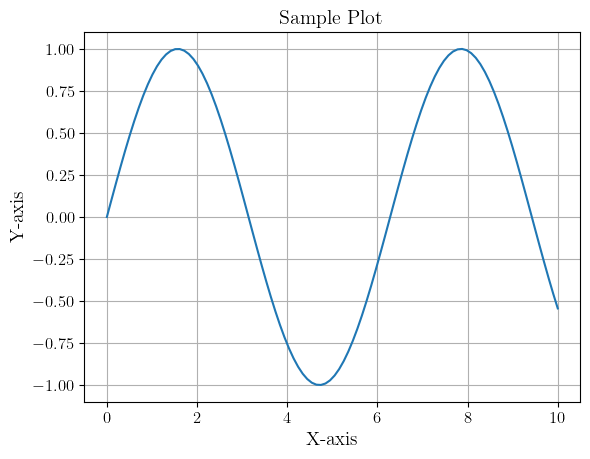

In [175]:
plt.rcParams.update({
    "text.usetex": True,             # use LaTeX for all text
    "font.family": "serif",          # serif fonts
    "font.serif": ["Computer Modern"],  # LaTeX default
    "axes.labelsize": 14,
    "font.size": 12,
    "legend.fontsize": 10,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12
})


plt.plot(np.linspace(0, 10, 100), np.sin(np.linspace(0, 10, 100)))
plt.xlabel('X-axis')
plt.ylabel('Y-axis')
plt.title('Sample Plot')
plt.grid(True)

# Utility Functions

In [176]:
def load_dat(path, verbose=False):
    """
    Load a .dat file into a pandas DataFrame, handling comment lines and extracting column names
    from the last commented line.
    
    Parameters:
    - path: Path to the .dat file.
    
    Returns:
    - df: pandas DataFrame containing the data.
    """
    # Read the file line by line to handle comments and column names
    with open(path, 'r') as file:
        lines = file.readlines()
    
    # Extract column names from the last line starting with '#'
    coments = [line for line in lines if line.startswith('#')]
    column_line = [line for line in lines if line.startswith('#')][-1]
    column_names = column_line.strip('#').strip().split()

    # Read the data, skipping all comment lines
    df = pd.read_csv(
        path,
        comment='#',           # Ignores all lines that begin with '#'
        delim_whitespace=True, # Split columns by whitespace
        header=None,           # No header row in the data portion
        names=column_names     # Assign column names from the last '#'
    )
    
    if verbose:
        for i in coments:
            print(i)
    return df

In [177]:
def extract_cell_counts(log_path):
    """
    Extracts cell counts from a checkMesh.log file.
    
    Returns a dictionary like:
    {
        'hexahedra': 16850459,
        'prisms': 32,
        ...
    }
    """
    cell_counts = {}
    start_marker = "Overall number of cells of each type:"
    pattern = r"(\w[\w ]*?):\s+(\d+)"

    with open(log_path, "r") as f:
        lines = f.readlines()

    capturing = False
    for line in lines:
        if start_marker in line:
            capturing = True
            continue

        if capturing:
            if line.strip() == "":
                break  # end of section
            match = re.match(pattern, line.strip())
            if match:
                cell_type = match.group(1).strip()
                count = int(match.group(2))
                cell_counts[cell_type] = count

    return cell_counts

In [178]:

def extract_all_times(log_path):
    """
    Extracts ExecutionTime and ClockTime from a rhoSimpleFoam log file.

    Returns:
        {
            'ExecutionTime': [exec1, exec2, ...],
            'ClockTime': [clock1, clock2, ...]
        }
    """
    times = {
        'ExecutionTime': [],
        'ClockTime': []
    }

    pattern = r"ExecutionTime\s*=\s*([\d.]+)\s*s\s+ClockTime\s*=\s*(\d+)\s*s"

    with open(log_path, "r") as f:
        for line in f:
            match = re.search(pattern, line)
            if match:
                exec_time = float(match.group(1))
                clock_time = int(match.group(2))
                times['ExecutionTime'].append(exec_time)
                times['ClockTime'].append(clock_time)

    return times

In [179]:
def summarize_cases(base_dir):
    rows = []

    for case_name in sorted(os.listdir(base_dir)):
        case_path = os.path.join(base_dir, case_name)
        if not os.path.isdir(case_path):
            continue

        # 1. Mesh info
        mesh_log = os.path.join(case_path, 'logs', 'checkMesh.log')
        try:
            cell_counts = extract_cell_counts(mesh_log)
            mesh_total = sum(cell_counts.values())
        except Exception:
            mesh_total = np.nan

        # 2. Solver times
        foam_log = os.path.join(case_path, 'logs', 'rhoSimpleFoam.log')
        try:
            times = extract_all_times(foam_log)
            exec_time = np.diff(times['ExecutionTime'], prepend=0, append=0)[1:-1].mean()
            clock_time = np.diff(times['ClockTime'], prepend=0, append=0)[1:-1].mean()
        except Exception:
            exec_time = np.nan
            clock_time = np.nan

        # 3. Final Cd from forceCoeffs/latest/coefficient.dat
        coeff_path = os.path.join(case_path, 'postProcessing', 'forceCoeffs')
        Cd = np.nan
        if os.path.exists(coeff_path):
            subdirs = [d for d in os.listdir(coeff_path) if os.path.isdir(os.path.join(coeff_path, d))]
            if subdirs:
                latest = sorted(subdirs, key=lambda x: float(x))[-1]
                dat_file = os.path.join(coeff_path, latest, 'coefficient.dat')
                if os.path.exists(dat_file):
                    try:
                        df = load_dat(dat_file)
                        Cd = df["Cd"].iloc[-1]
                    except Exception:
                        pass

        # 4. Final max y+ from yPlus1/latest/yPlus.dat
        yplus_path = os.path.join(case_path, 'postProcessing', 'yPlus1')
        max_yplus = np.nan
        if os.path.exists(yplus_path):
            subdirs = [d for d in os.listdir(yplus_path) if os.path.isdir(os.path.join(yplus_path, d))]
            if subdirs:
                latest = sorted(subdirs, key=lambda x: float(x))[-1]
                dat_file = os.path.join(yplus_path, latest, 'yPlus.dat')
                if os.path.exists(dat_file):
                    try:
                        df = load_dat(dat_file)
                        max_yplus = df["max"].iloc[-1]
                    except Exception:
                        pass

        # 5. Append row
        rows.append({
            "case_name": case_name,
            "mesh_cells": mesh_total,
            "exec_time": exec_time,
            "clock_time": clock_time,
            "Cd": Cd,
            "max_yplus": max_yplus
        })

    return pd.DataFrame(rows)

## Test utility tools

In [180]:
extract_cell_counts("OpenFOAM_Results_gathered/Mesh_Study/mesh_1p7/logs/checkMesh.log")

{'hexahedra': 14933389,
 'prisms': 108,
 'wedges': 0,
 'pyramids': 82,
 'tet wedges': 0,
 'tetrahedra': 90,
 'polyhedra': 748636}

In [181]:
Volume = 40 * 20 * 20  # Volume of the mesh in mm^3

df = summarize_cases("OpenFOAM_Results_gathered/Mesh_Study")
df['h'] =  df['mesh_cells'].apply(lambda x: ((Volume)/x)**(1/3) if x > 0 else np.nan)


df.head(10)

,case_name,mesh_cells,exec_time,clock_time,Cd,max_yplus,h
0,mesh_1p5,21300732,4.335322,6.605701,0.371076,315.897660,0.090902
1,mesh_1p6,17919290,3.690566,9.144644,0.372016,327.406439,0.096294
2,mesh_1p7,15682305,2.862390,4.677710,0.379148,373.775475,0.100671
3,mesh_1p8,13646546,2.362013,2.958120,0.380248,305.800506,0.105447
4,mesh_1p9,12026622,1.950696,6.371874,0.378254,392.192572,0.109983
5,mesh_2p0,10732045,1.595407,2.053382,0.381555,354.446930,0.114239
6,mesh_2p1,9651938,1.313693,2.042630,0.381864,402.958151,0.118350
7,mesh_2p2,8826450,1.133084,1.684211,0.385173,446.062243,0.121930
8,mesh_2p3,7860844,0.891658,1.448056,0.385297,486.100501,0.126731
9,mesh_2p4,7386881,0.816185,1.802100,0.389932,514.259976,0.129386


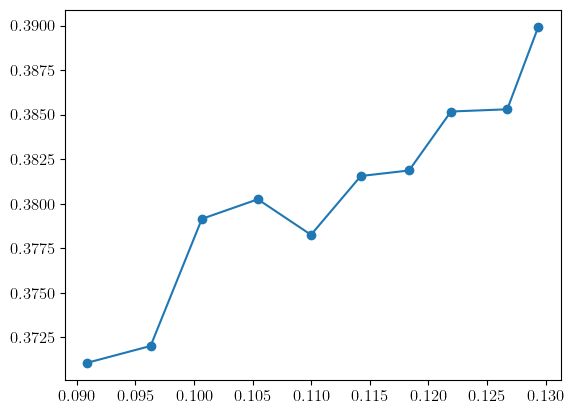

In [182]:
plt.plot(df['h'], df['Cd'], marker='o', linestyle='-')

# Mesh Analysis

In [183]:
def richardson_triplet(h1, h2, h3, phi1, phi2, phi3, Fs=1.25,verbose=False):
    '''
    h3: coarse
    h2: medium
    h1: fine
    '''
    # Bundle and sort by decreasing h (coarse → fine)
    sorted_data = sorted(zip([h1, h2, h3], [phi1, phi2, phi3]), key=lambda x: -x[0])
    (h3, phi3), (h2, phi2), (h1, phi1) = sorted_data
    
    # Compute refinement ratios
    r32 = h3 / h2
    r21 = h2 / h1

    # Error differences
    e21 = phi2 - phi1
    e32 = phi3 - phi2

    # Sign factor
    s = np.sign(e32 / e21)


    if e21 == 0 or e32 == 0 or np.sign(e32 / e21) == 0:
        raise RuntimeError("Unstable error ratios: division or log undefined.")
    
    # System of equations
    def equations(x):
        p, q = x
        try:
            eq1 = q - np.log((r21**p - s) / (r32**p - s))
            eq2 = p - (1 / np.log(r21)) * abs(np.log(np.abs(e32 / e21)) + q)
            if verbose:
                print(f"  ↪ p = {p:.6f}, q = {q:.6f}, eq1 = {eq1:.2e}, eq2 = {eq2:.2e}")
            return [eq1, eq2]
        except Exception as e:
            print(f"  ✗ Exception in equations: {e}")
            raise


    # Initial guess
    x0 = [1.0, 0.1]

    # Solve nonlinear system
    sol = root(equations, x0)

    if not sol.success:
        raise RuntimeError("Failed to converge: " + sol.message)

    p, q = sol.x

    # Extrapolated solution using fine and medium
    phi_ext = phi1 + (phi1 - phi2) / (r21**p - 1)

    # GCI for fine–medium and medium–coarse
    GCI_12 = Fs * abs(phi1 - phi2) / abs(phi1) / abs(r21**p - 1)
    GCI_23 = Fs * abs(phi2 - phi3) / abs(phi2) / abs(r32**p - 1)

    return {
        'p': p,
        'q': q,
        's': s,
        'r21': r21,
        'r32': r32,
        'e21': e21,
        'e32': e32,
        'phi_ext': phi_ext,
        'GCI_12 (%)': GCI_12 * 100,
        'GCI_23 (%)': GCI_23 * 100,
    }


In [184]:
def analyze_richardson_dataset(h_list, phi_list, tolerance=0.05,verbose=True):
    results = []

    # Iterate over all unique triplets (coarse, medium, fine)
    for i, j, k in combinations(range(len(h_list)), 3):
        # Extract values
        hs = [h_list[i], h_list[j], h_list[k]]
        phis = [phi_list[i], phi_list[j], phi_list[k]]

        try:
            # Run triplet Richardson analysis
            result = richardson_triplet(*hs, *phis,verbose=verbose)
            result['Triplet'] = f"[{i}-{j}-{k}]"
            result['h1'] = hs[0]
            result['h2'] = hs[1]
            result['h3'] = hs[2]
            result['phi1'] = phis[0]
            result['phi2'] = phis[1]
            result['phi3'] = phis[2]
            results.append(result)
        except Exception as e:
            results.append({'Triplet': f"[{i}-{j}-{k}]", 'Error': str(e)})



    # Convert to DataFrame
    df = pd.DataFrame(results)
    # Drop failed rows
    df_valid = df.dropna(subset=['phi_ext']).copy()

    # Optionally average close phi_ext values
    if not df_valid.empty:
        phi_exts = df_valid['phi_ext'].values
        ref = np.median(phi_exts)
        within_tol = np.abs((phi_exts - ref) / ref) < tolerance
        phi_avg = np.mean(phi_exts[within_tol])
        phi_std = np.std(phi_exts[within_tol])
        print(f"\nAverage extrapolated φ (within {tolerance*100:.1f}%): {phi_avg:.6f} ± {phi_std:.6f} from {within_tol.sum()} triplets")
    else:
        print("No valid triplets found.")

    return df

## Test Mesh functions

In [185]:
h_list = df.h.values
phi_list = df.Cd.values

df1 = analyze_richardson_dataset(h_list, phi_list, tolerance=0.05,verbose=True)
df1.dropna(subset=['phi_ext'], inplace=True)

  ↪ p = 1.000000, q = 0.100000, eq1 = -1.66e-01, eq2 = -3.59e+01
  ↪ p = 1.000000, q = 0.100000, eq1 = -1.66e-01, eq2 = -3.59e+01
  ↪ p = 1.000000, q = 0.100000, eq1 = -1.66e-01, eq2 = -3.59e+01
  ↪ p = 1.000000, q = 0.100000, eq1 = -1.66e-01, eq2 = -3.59e+01
  ↪ p = 1.000000, q = 0.100000, eq1 = -1.66e-01, eq2 = -3.59e+01
  ↪ p = 44.888100, q = 0.560197, eq1 = -9.90e-02, eq2 = -5.17e-07
  ↪ p = 46.936334, q = 0.678218, eq1 = -3.39e-03, eq2 = -1.05e-07
  ↪ p = 47.008978, q = 0.682404, eq1 = -5.05e-06, eq2 = 0.00e+00
  ↪ p = 47.009086, q = 0.682410, eq1 = -2.54e-10, eq2 = 0.00e+00
  ↪ p = 47.009086, q = 0.682410, eq1 = 1.11e-16, eq2 = 0.00e+00
  ↪ p = 1.000000, q = 0.100000, eq1 = 5.72e-01, eq2 = -3.84e+01
  ↪ p = 1.000000, q = 0.100000, eq1 = 5.72e-01, eq2 = -3.84e+01
  ↪ p = 1.000000, q = 0.100000, eq1 = 5.72e-01, eq2 = -3.84e+01
  ↪ p = 1.000000, q = 0.100000, eq1 = 5.72e-01, eq2 = -3.84e+01
  ↪ p = 1.000000, q = 0.100000, eq1 = 5.72e-01, eq2 = -3.84e+01
  ↪ p = 22.985754, q = -0.845

In [186]:
df1

,p,q,s,r21,r32,e21,e32,phi_ext,GCI_12 (%),GCI_23 (%),Triplet,h1,h2,h3,phi1,phi2,phi3,Error
0,47.009086,0.682410,1.0,1.059314,1.045451,0.000940,0.007132,0.371009,0.022606,0.338463,[0-1-2],0.090902,0.096294,0.100671,0.371076,0.372016,0.379148,NaN
1,21.847264,-0.910850,1.0,1.059314,1.095047,0.000940,0.008232,0.370703,0.125609,0.441206,[0-1-3],0.090902,0.096294,0.105447,0.371076,0.372016,0.380248,NaN
2,10.420966,-1.291902,1.0,1.059314,1.142157,0.000940,0.006238,0.369933,0.384842,0.699783,[0-1-4],0.090902,0.096294,0.109983,0.371076,0.372016,0.378254,NaN
3,9.869081,-1.748341,1.0,1.059314,1.186350,0.000940,0.009539,0.369848,0.413511,0.728380,[0-1-5],0.090902,0.096294,0.114239,0.371076,0.372016,0.381555,NaN
4,7.463113,-1.918867,1.0,1.059314,1.229048,0.000940,0.009848,0.369326,0.589445,0.903869,[0-1-6],0.090902,0.096294,0.118350,0.371076,0.372016,0.381864,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115,38.367303,3.768040,1.0,1.109356,1.020946,0.003743,0.004634,0.381483,0.023306,1.237304,[5-8-9],0.114239,0.126731,0.129386,0.381555,0.385297,0.389932,NaN
116,156.847801,-1.390068,1.0,1.030250,1.039375,0.003310,0.000124,0.381833,0.010205,0.000094,[6-7-8],0.118350,0.121930,0.126731,0.381864,0.385173,0.385297,NaN
117,26.782258,-1.161268,1.0,1.030250,1.061146,0.003310,0.004758,0.379154,0.886950,0.395834,[6-7-9],0.118350,0.121930,0.129386,0.381864,0.385173,0.389932,NaN
118,39.290307,2.388386,1.0,1.070817,1.020946,0.003434,0.004634,0.381613,0.082001,1.195215,[6-8-9],0.118350,0.126731,0.129386,0.381864,0.385297,0.389932,NaN


In [187]:
dfFinal = df1[(df1['r21'] > 1.1) & (df1['r32'] > 1.1) & (df1['GCI_12 (%)'] < 10) & (df1['GCI_23 (%)'] < 10) ]
dfFinal

,p,q,s,r21,r32,e21,e32,phi_ext,GCI_12 (%),GCI_23 (%),Triplet,h1,h2,h3,phi1,phi2,phi3,Error
10,16.512132,-0.474958,1.0,1.107460,1.134773,0.008073,0.002406,0.369239,0.618798,0.112266,[0-2-5],0.090902,0.100671,0.114239,0.371076,0.379148,0.381555,NaN
11,26.980928,-1.664356,1.0,1.107460,1.175615,0.008073,0.002715,0.370527,0.184935,0.011525,[0-2-6],0.090902,0.100671,0.118350,0.371076,0.379148,0.381864,NaN
12,27.760430,-2.540918,1.0,1.107460,1.211178,0.008073,0.006025,0.370571,0.169907,0.009779,[0-2-7],0.090902,0.100671,0.121930,0.371076,0.379148,0.385173,NaN
17,8.838960,0.424691,1.0,1.159998,1.122370,0.009172,0.001615,0.367695,1.138850,0.299314,[0-3-6],0.090902,0.105447,0.118350,0.371076,0.380248,0.381864,NaN
18,3.997335,0.028577,1.0,1.159998,1.156322,0.009172,0.004925,0.359751,3.814986,2.056985,[0-3-7],0.090902,0.105447,0.121930,0.371076,0.380248,0.385173,NaN
19,6.355312,-0.346256,1.0,1.159998,1.201853,0.009172,0.005049,0.365227,1.970157,0.748601,[0-3-8],0.090902,0.105447,0.126731,0.371076,0.380248,0.385297,NaN
20,2.251576,-0.388410,1.0,1.159998,1.227026,0.009172,0.009684,0.347959,7.787034,5.440479,[0-3-9],0.090902,0.105447,0.129386,0.371076,0.380248,0.389932,NaN
23,4.049143,0.808341,1.0,1.209902,1.108628,0.007178,0.006919,0.364904,2.079124,4.411914,[0-4-7],0.090902,0.109983,0.121930,0.371076,0.378254,0.385173,NaN
24,1.677412,0.338670,1.0,1.209902,1.152280,0.007178,0.007043,0.352014,6.421051,8.671439,[0-4-8],0.090902,0.109983,0.126731,0.371076,0.378254,0.385297,NaN
25,3.691153,0.216737,1.0,1.209902,1.176416,0.007178,0.011678,0.364041,2.369723,4.696997,[0-4-9],0.090902,0.109983,0.129386,0.371076,0.378254,0.389932,NaN


In [188]:
meanCd = dfFinal['phi_ext'].mean()

df['error'] = np.abs(df['Cd'] - meanCd) / meanCd * 100
print(meanCd)

0.36314961607025453


In [189]:
df

,case_name,mesh_cells,exec_time,clock_time,Cd,max_yplus,h,error
0,mesh_1p5,21300732,4.335322,6.605701,0.371076,315.897660,0.090902,2.182622
1,mesh_1p6,17919290,3.690566,9.144644,0.372016,327.406439,0.096294,2.441524
2,mesh_1p7,15682305,2.862390,4.677710,0.379148,373.775475,0.100671,4.405563
3,mesh_1p8,13646546,2.362013,2.958120,0.380248,305.800506,0.105447,4.708413
4,mesh_1p9,12026622,1.950696,6.371874,0.378254,392.192572,0.109983,4.159356
5,mesh_2p0,10732045,1.595407,2.053382,0.381555,354.446930,0.114239,5.068155
6,mesh_2p1,9651938,1.313693,2.042630,0.381864,402.958151,0.118350,5.153271
7,mesh_2p2,8826450,1.133084,1.684211,0.385173,446.062243,0.121930,6.064631
8,mesh_2p3,7860844,0.891658,1.448056,0.385297,486.100501,0.126731,6.098777
9,mesh_2p4,7386881,0.816185,1.802100,0.389932,514.259976,0.129386,7.374972


## Ploting the mesh Independency graphs

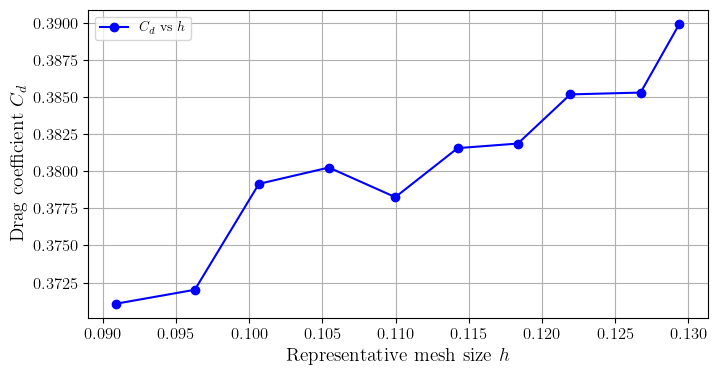

In [190]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(df['h'], df['Cd'], 'b-o', label=r'$C_d$ vs $h$')

ax.set_xlabel(r'Representative mesh size $h$')
ax.set_ylabel(r'Drag coefficient $C_d$')
ax.grid(True)
ax.legend()

plt.savefig("./results/MeshDependence/CdMesh.pdf")

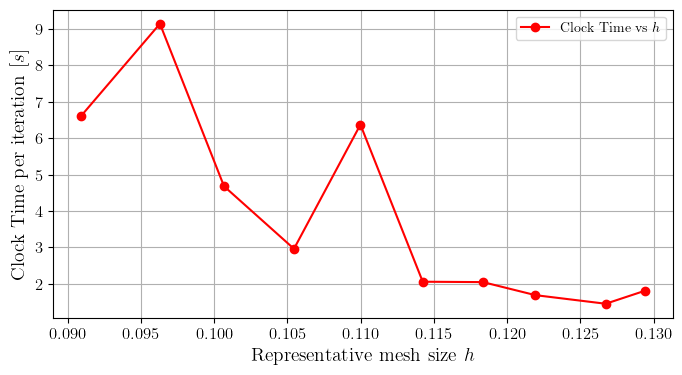

In [191]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(df['h'], df['clock_time'], 'r-o', label=r'Clock Time vs $h$')

ax.set_xlabel(r'Representative mesh size $h$')
ax.set_ylabel(r'Clock Time per iteration [$s$]')
ax.grid(True)
ax.legend()

plt.savefig("./results/MeshDependence/ClockTimeMesh.pdf")

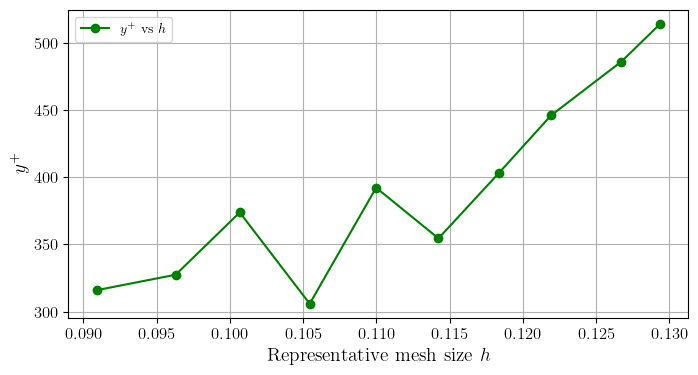

In [192]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(df['h'], df['max_yplus'], 'g-o', label=r'$y^{+}$ vs $h$')

ax.set_xlabel(r'Representative mesh size $h$')
ax.set_ylabel(r'$y^{+}$')
ax.grid(True)
ax.legend()

plt.savefig("./results/MeshDependence/yPlusMesh.pdf")

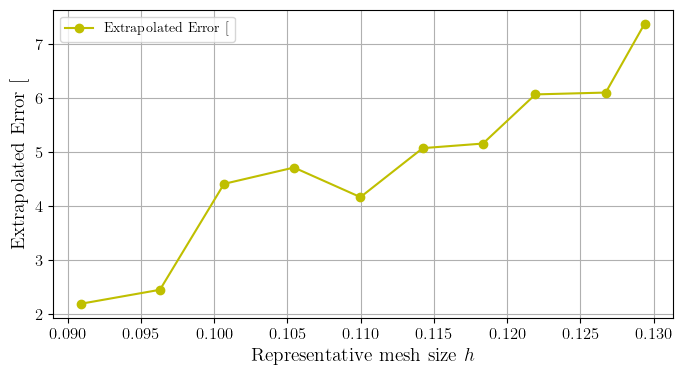

In [193]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(df['h'], df['error'], 'y-o', label=r'Extrapolated Error [%] vs $h$')

ax.set_xlabel(r'Representative mesh size $h$')
ax.set_ylabel(r'Extrapolated Error [%]')
ax.grid(True)
ax.legend()

plt.savefig("./results/MeshDependence/errorMesh.pdf")

# Mach Angle Contours

In [194]:
def compute_center_of_pressure(mesh, pressure_field='p'):
    pressure = mesh[pressure_field]
    cell_centers = mesh.cell_centers()
    cell_areas = mesh.compute_cell_sizes()['Area']
    mesh_n = mesh.compute_normals(cell_normals=True, point_normals=False)
    normals = mesh_n['Normals']
    if pressure.size == mesh.n_points:
        mesh_copy = mesh.copy()
        mesh_copy[pressure_field] = pressure
        cell_data = mesh_copy.cell_data_to_point_data().point_data_to_cell_data()
        pressure_cells = cell_data[pressure_field]
    else:
        pressure_cells = pressure
    ref = np.array([mesh.bounds[0], 0, 0])
    forces = pressure_cells[:,None] * cell_areas[:,None] * (-normals)
    total_force = forces.sum(axis=0)
    centers = cell_centers.points
    moments = np.cross(centers - ref, forces)
    total_moment = moments.sum(axis=0)
    cp_x = ref[0] + total_moment[2]/total_force[1] if abs(total_force[1]) > 1e-10 else ref[0]
    cp_y = ref[1] - total_moment[2]/total_force[0] if abs(total_force[0]) > 1e-10 else ref[1]
    return np.array([cp_x, cp_y, ref[2]])


In [195]:
def plot_slice_contour(sliceZ, 
                       field='Ma',
                       rocket=None,
                       cmap='jet', 
                       Ma=1.2, 
                       cg=1.8, 
                       vmin=None, 
                       vmax=None,
                       show_cop=True,
                       show_cog=True,
                       show_shock_angle=True,
                       show_axes=True,
                       colorbar_label=None,
                       pressure_field='p'):
    """
    General function to plot contours of any field on a slice.
    
    Parameters:
    -----------
    sliceZ : pyvista object
        The slice to plot
    field : str
        Name of the field to plot (e.g., 'Ma', 'p', 'T', 'rho', etc.)
    rocket : object, optional
        Rocket object for computing center of pressure
    cmap : str
        Colormap name
    Ma : float
        Mach number for shock angle calculation
    cg : float
        Center of gravity x-coordinate
    vmin, vmax : float, optional
        Min and max values for color scale
    show_cop : bool
        Show center of pressure annotation
    show_cog : bool
        Show center of gravity annotation
    show_shock_angle : bool
        Show shock angle lines
    show_axes : bool
        Show coordinate axes at origin
    colorbar_label : str, optional
        Custom label for colorbar (if None, uses field name)
    pressure_field : str
        Field to use for computing center of pressure
    
    Returns:
    --------
    fig : matplotlib figure
    """
    
    # Get center of pressure if needed
    if show_cop and rocket is not None:
        Cop = compute_center_of_pressure(rocket, pressure_field=pressure_field)
        print(Cop)
        cp_x, cp_y = Cop[0], Cop[1]
    
    # Triangulate mesh
    tri_mesh = sliceZ.triangulate()
    faces = tri_mesh.faces.reshape(-1, 4)[:, 1:]
    
    pts = tri_mesh.points
    x, y = pts[:, 0], pts[:, 1]
    
    # Get the field data
    if field not in tri_mesh.array_names:
        raise ValueError(f"Field '{field}' not found in slice data. Available fields: {tri_mesh.array_names}")
    
    var = tri_mesh[field]
    
    # Create triangulation and plot
    triang = mtri.Triangulation(x, y, faces)
    fig, ax = plt.subplots(figsize=(20, 14), facecolor='white')
    cont = ax.tricontourf(triang, var, cmap=cmap, levels=400, vmin=vmin, vmax=vmax)
    
    # Shock angle annotation
    if show_shock_angle and Ma > 1:
        theta = np.degrees(np.arcsin(1 / Ma))
        L = 15
        x_off, y_off = L * np.cos(np.radians(theta)), L * np.sin(np.radians(theta))
        
        ax.plot([0, x_off], [0, y_off], '--k')
        ax.plot([0, x_off], [0, -y_off], '--k')
        ax.text(-1.2, 0.5, f"Shock Angle={theta:.2f}°", color='black', fontsize=14)
    
    # Center of Pressure annotation
    if show_cop and rocket is not None:
        ax.plot(cp_x, 0.0, 'ro', markersize=8)
        ax.text(cp_x - 0.1, 0.3, 'CoP', color='red', fontsize=14)
        arrow = FancyArrowPatch((0.0, -0.2), (cp_x, -0.2), arrowstyle='<->', color='red',
                                linewidth=1, mutation_scale=20)
        ax.add_patch(arrow)
        ax.text(cp_x / 2 - 0.1, -0.4, f'{cp_x:.2f} m', color='red', fontsize=14)
    
    # Center of Gravity annotation
    if show_cog:
        ax.plot(cg, 0.0, 'bo', markersize=8)
        ax.text(cg - 0.1, 0.3, 'CoG', color='blue', fontsize=14)
        arrow = FancyArrowPatch((0.0, 0.2), (cg, 0.2), arrowstyle='<->', color='blue',
                                linewidth=1, mutation_scale=20)
        ax.add_patch(arrow)
        ax.text(cg / 2 - 0.1, 0.4, f'{cg:.2f} m', color='blue', fontsize=14)
    
    # Coordinate axes annotation
    if show_axes:
        origin_x, origin_y = -1.8, -2.5
        dx, dz = 0.5, 0.5
        
        # X direction arrow
        ax.annotate('', xy=(origin_x + dx, origin_y), xytext=(origin_x, origin_y),
                    arrowprops=dict(facecolor='black', shrink=0.0, width=2, headwidth=8))
        ax.text(origin_x + dx + 0.1, origin_y, 'x', fontsize=14, ha='center', va='center')
        
        # Z direction arrow
        ax.annotate('', xy=(origin_x, origin_y + dz), xytext=(origin_x, origin_y),
                    arrowprops=dict(facecolor='black', shrink=0.0, width=2, headwidth=8))
        ax.text(origin_x, origin_y + dz + 0.1, 'z', fontsize=14, ha='center', va='center')
    
    # Set plot properties
    ax.set_xlim(-2, 10)
    ax.set_ylim(-3, 3)
    ax.set_aspect('equal')
    ax.axis('off')
    
    # Colorbar
    cb = fig.colorbar(cont, ax=ax, orientation='horizontal', fraction=0.046, pad=0.04)
    if colorbar_label is None:
        # Create a nice default label based on field name
        field_labels = {
            'Ma': 'Mach number',
            'p': 'Pressure [Pa]',
            'T': 'Temperature [K]',
            'rho': 'Density [kg/m³]',
            'U': 'Velocity magnitude [m/s]',
            'omega': 'Vorticity [1/s]'
        }
        colorbar_label = field_labels.get(field, field)
    cb.set_label(colorbar_label, fontsize=14)
    
    plt.tight_layout()
    plt.show()
    
    return fig

In [23]:
def plot_mesh_edges(sliceZ, linewidth=0.5, figsize=(20, 14)):
    """
    Plot only the mesh edges in black on white background.
    
    Parameters:
    -----------
    sliceZ : pyvista object
        The slice to plot
    linewidth : float
        Width of the mesh edges
    figsize : tuple
        Figure size (width, height)
    
    Returns:
    --------
    fig : matplotlib figure
    """
    pts = sliceZ.points
    
    # Extract faces - PyVista stores faces as [n, v1, v2, ..., vn, n, v1, ...]
    faces_raw = sliceZ.faces
    
    fig, ax = plt.subplots(figsize=figsize, facecolor='white')
    
    # Parse faces
    i = 0
    while i < len(faces_raw):
        n_points = faces_raw[i]  # Number of points in this face
        face_indices = faces_raw[i+1:i+1+n_points]  # Get the vertex indices
        
        # Get the vertices
        face_pts = pts[face_indices]
        
        # Close the polygon by adding the first point at the end
        face_closed = np.vstack([face_pts, face_pts[0]])
        
        # Plot the edges
        ax.plot(face_closed[:, 0], face_closed[:, 1], 'k-', linewidth=linewidth)
        
        # Move to next face
        i += n_points + 1
    
    ax.set_xlim(-2, 10)
    ax.set_ylim(-3, 3)
    ax.set_aspect('equal')
    ax.axis('off')
    
    plt.tight_layout()
    plt.show()
    
    return fig

# Usage
path = "OpenFOAM_Results_gathered/Parametric_Study/TwoStage/Ma_2p4_AoA_5p0"
sliceZ = pv.read(f"{path}/postProcessing/sliceCentreZ/{t}/planeSlice.vtp")
fig = plot_mesh_edges(sliceZ)

NameError: name 't' is not defined

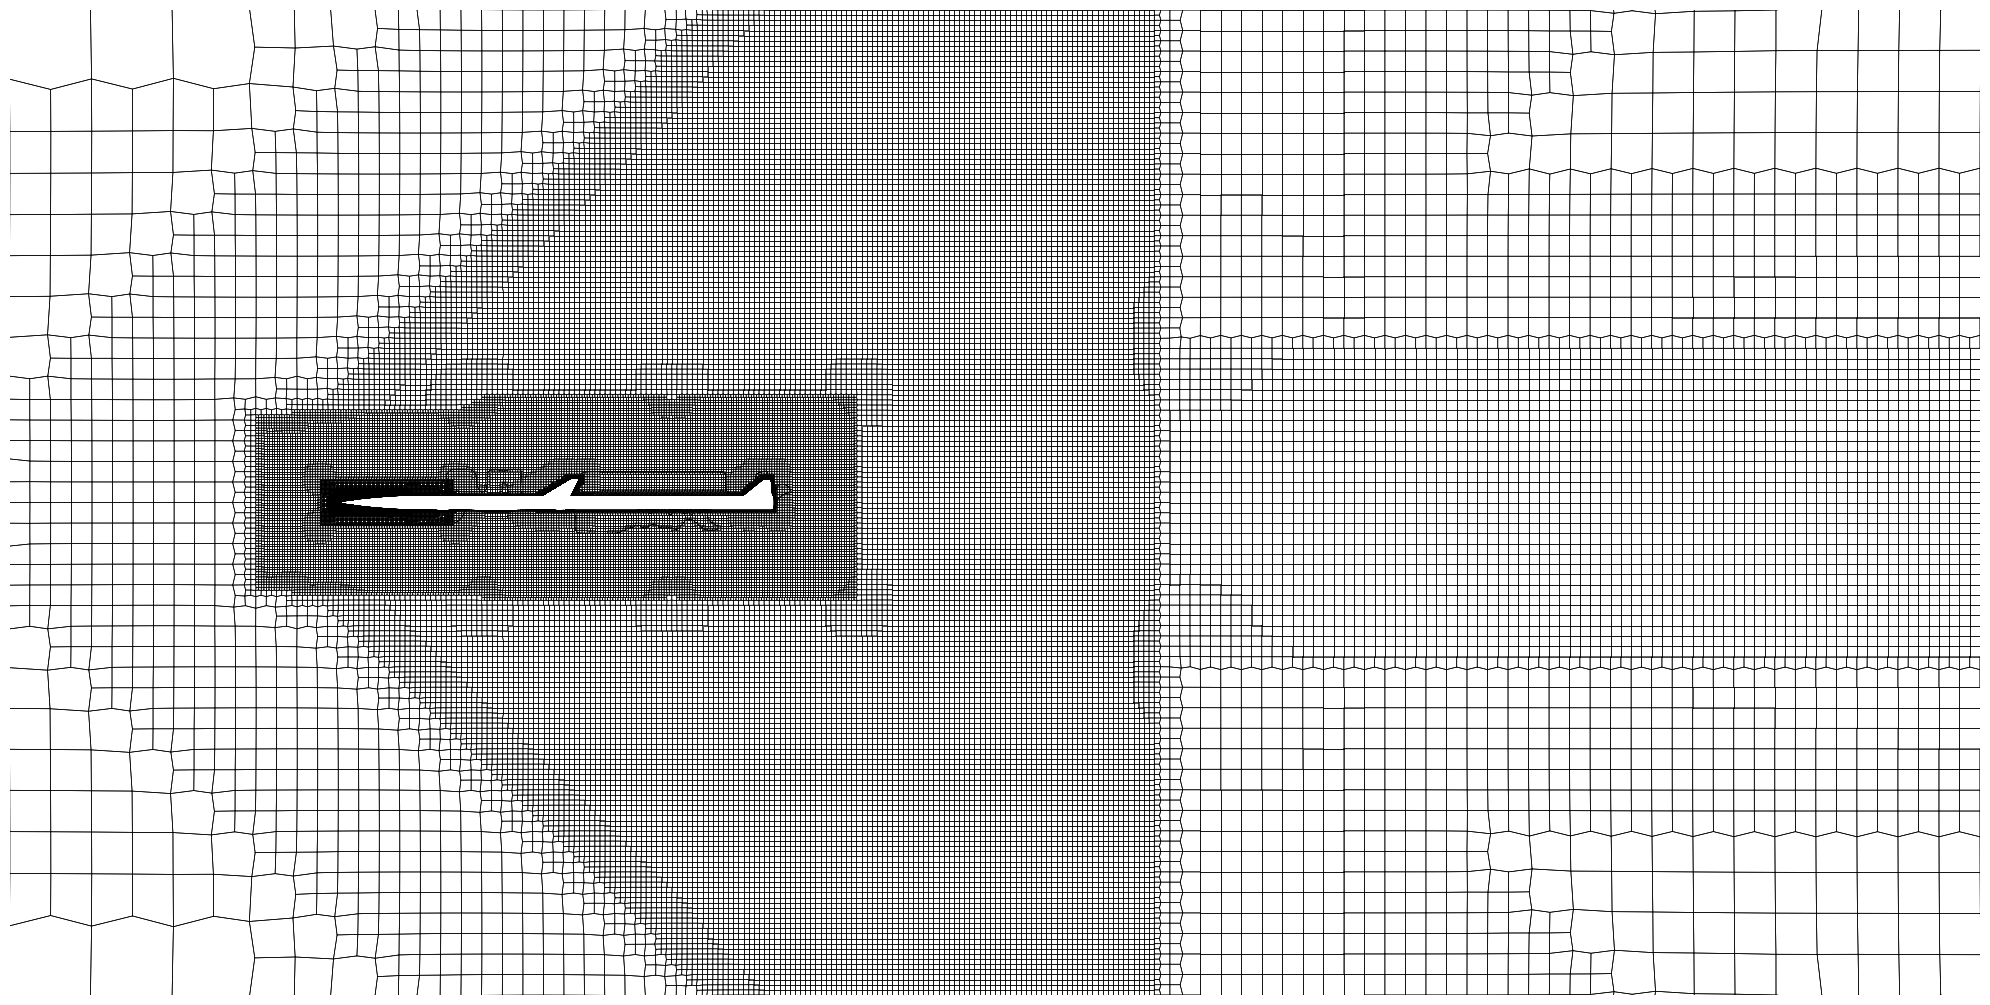

In [16]:
path = "OpenFOAM_Results_gathered/Parametric_Study/TwoStage/Ma_1p4_AoA_1p0"
sliceZ = pv.read(f"{path}/postProcessing/sliceCentreZ/{t}/planeSlice.vtp")
fig = plot_mesh_edges(sliceZ)

## Ploting the contours

[ 1.6989679  -9.81122631  0.        ]


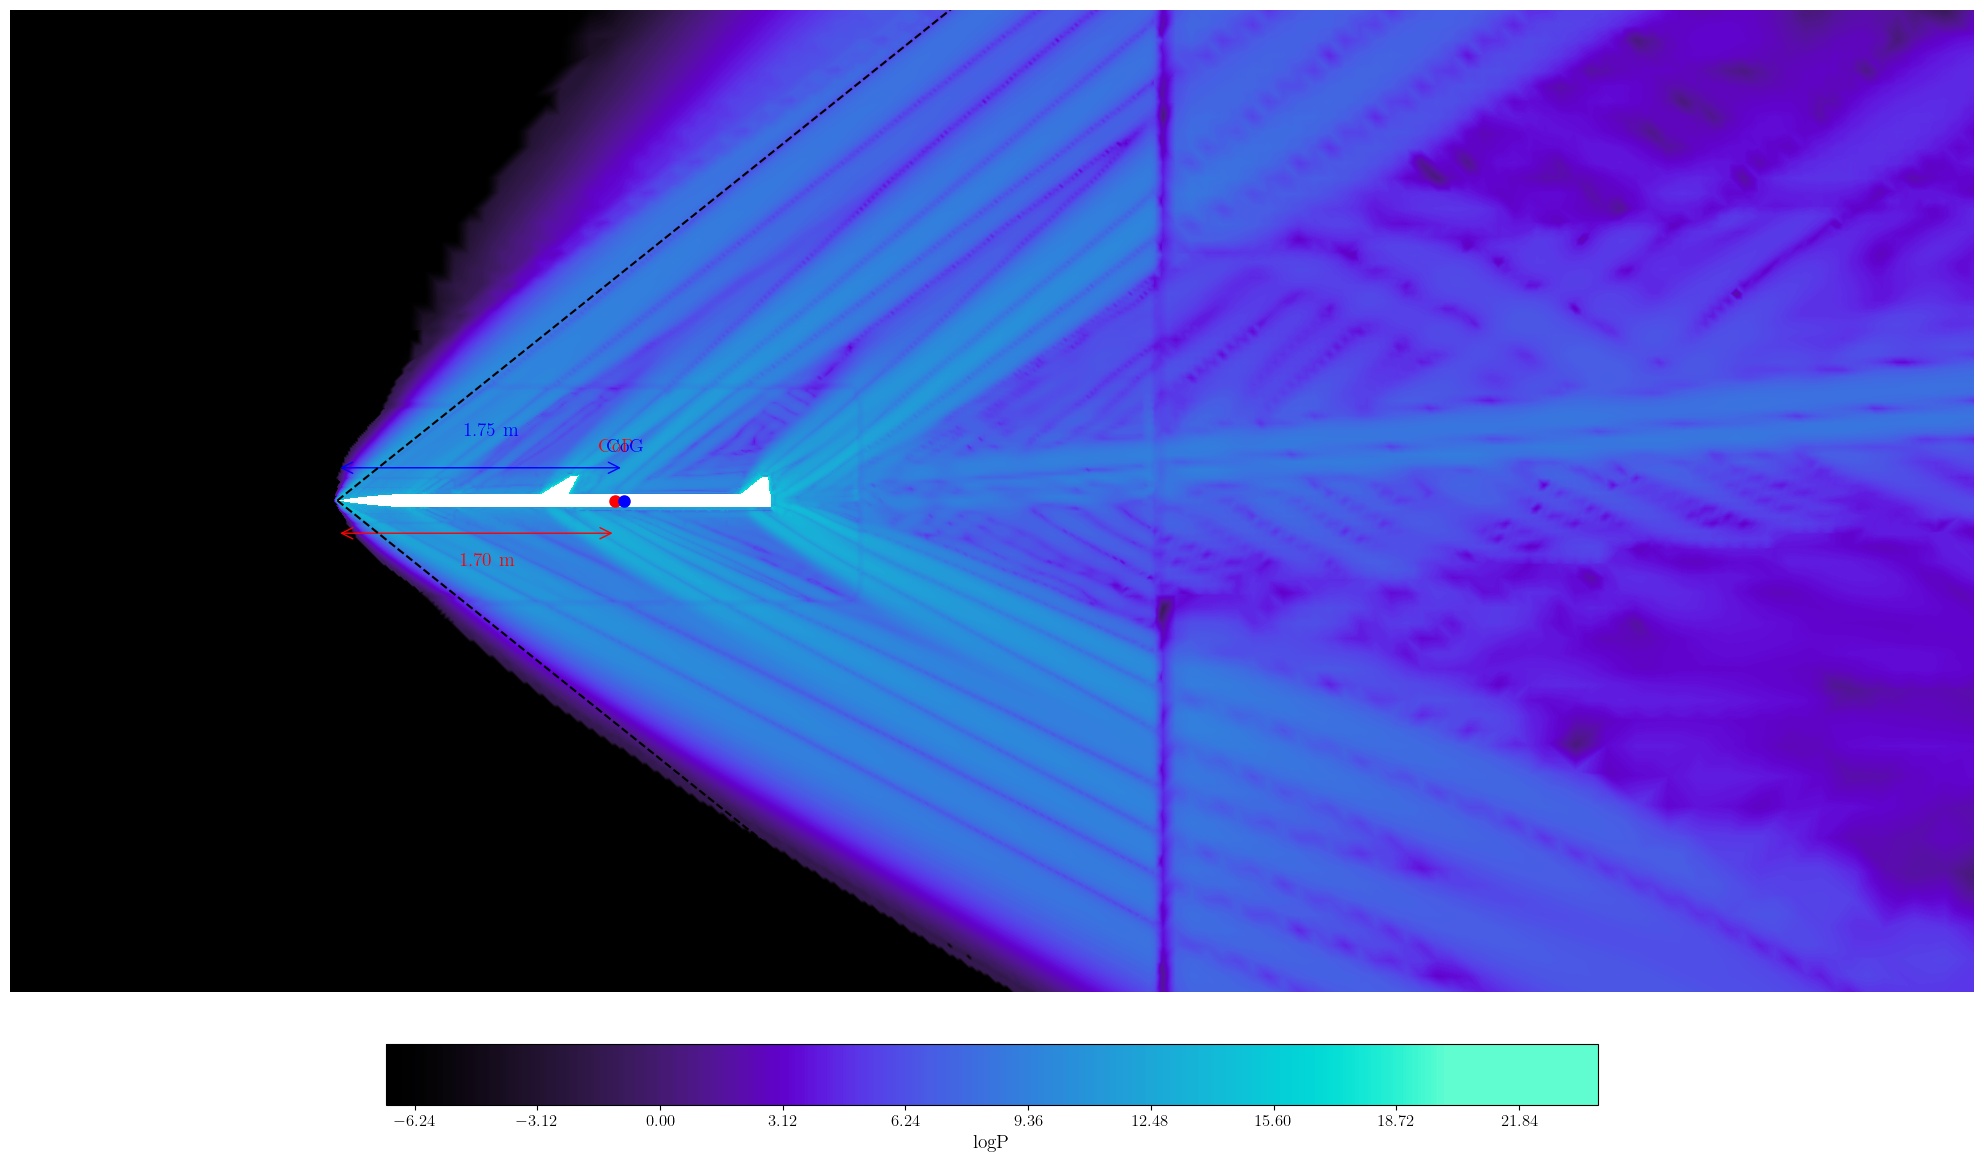

In [34]:
path = "OpenFOAM_Results_gathered/Parametric_Study/TwoStage/Ma_2p4_AoA_1p0"
path = "OpenFOAM_Results_gathered/Mesh_Study/mesh_1p5"
t = 8000
sliceZ = pv.read(f"{path}/postProcessing/sliceCentreZ/{t}/planeSlice.vtp")
rocket = pv.read(f"{path}/postProcessing/rocketVTK/{t}/rocketWall.vtp")
sliceZ = sliceZ.compute_derivative(scalars='p', gradient='p_gradient')

sliceZ['logP'] = np.log(np.abs(np.linalg.norm(sliceZ['p_gradient'], axis=1)) + 0.001)

_ = plot_slice_contour(sliceZ, field='logP', rocket=rocket, cmap=cmr.cosmic, Ma=1.6, cg=1.75, vmax= 20)

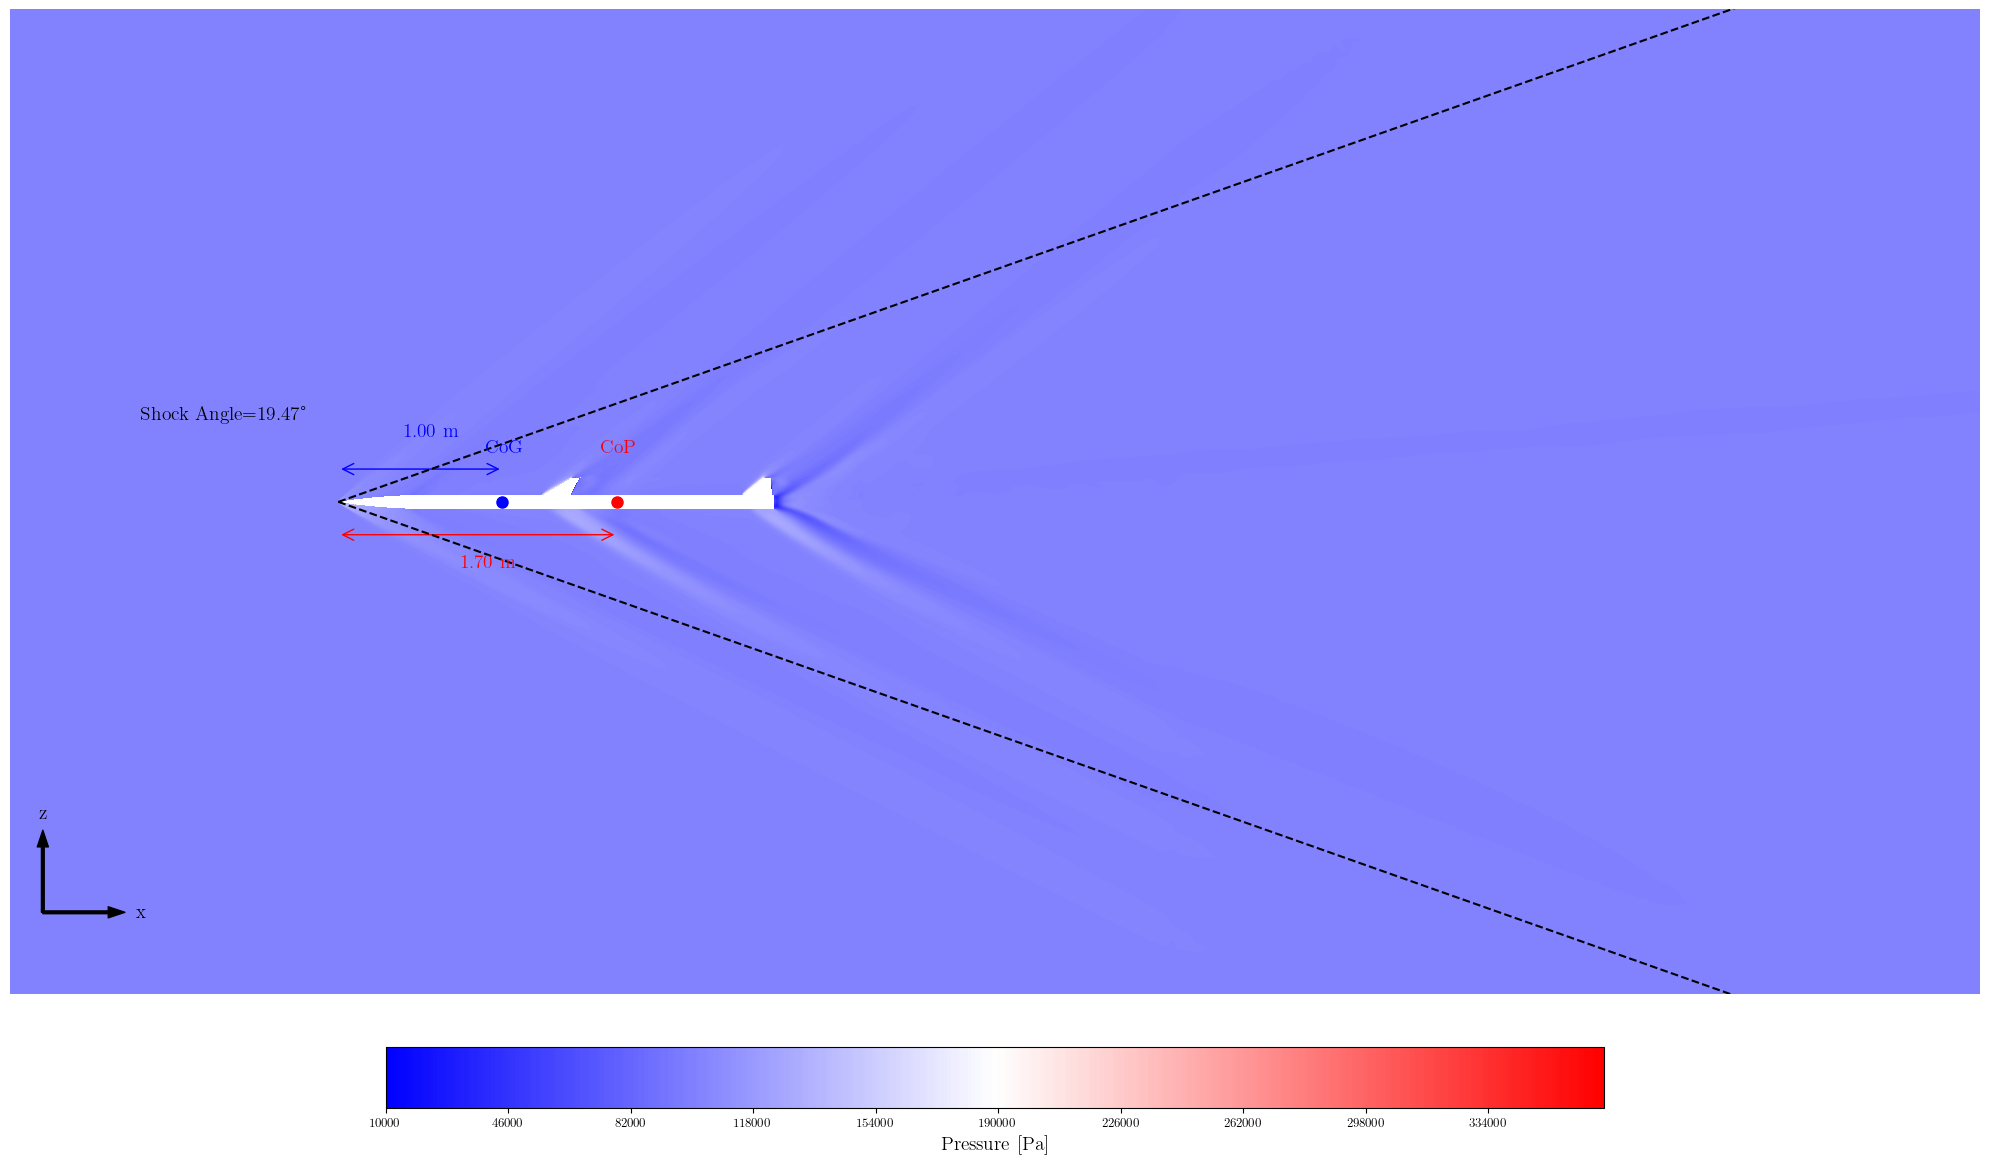

In [32]:
_ = plot_slice_contour(sliceZ, field='p', rocket=rocket, cmap='bwr', Ma=3, cg=1, vmax= None)


In [120]:
sliceZ

PolyData (0x7f01254794e0)
  N Cells:    81345
  N Points:   84424
  N Strips:   0
  X Bounds:   -1.000e+01, 3.000e+01
  Y Bounds:   -1.000e+01, 1.000e+01
  Z Bounds:   -1.681e-02, 1.548e-02
  N Arrays:   10

In [36]:
compute_center_of_pressure(rocket, pressure_field='p')

array([ 1.6989679 , -9.81122631,  0.        ])

In [37]:
def plot_slice_contour(sliceZ, 
                       field='Ma',
                       rocket=None,
                       cmap='jet', 
                       Ma=1.2, 
                       cg=1.8, 
                       vmin=None, 
                       vmax=None,
                       show_cop=True,
                       show_cog=True,
                       show_shock_angle=True,
                       show_axes=True,
                       colorbar_label=None,
                       pressure_field='p'):
    """
    General function to plot contours of any field on a slice.
    
    Parameters:
    -----------
    sliceZ : pyvista object
        The slice to plot
    field : str
        Name of the field to plot (e.g., 'Ma', 'p', 'T', 'rho', etc.)
    rocket : object, optional
        Rocket object for computing center of pressure
    cmap : str
        Colormap name
    Ma : float
        Mach number for shock angle calculation
    cg : float
        Center of gravity x-coordinate
    vmin, vmax : float, optional
        Min and max values for color scale
    show_cop : bool
        Show center of pressure annotation
    show_cog : bool
        Show center of gravity annotation
    show_shock_angle : bool
        Show shock angle lines
    show_axes : bool
        Show coordinate axes at origin
    colorbar_label : str, optional
        Custom label for colorbar (if None, uses field name)
    pressure_field : str
        Field to use for computing center of pressure
    
    Returns:
    --------
    fig : matplotlib figure
    """
    
    # Get center of pressure if needed
    if show_cop and rocket is not None:
        Cop = compute_center_of_pressure(rocket, pressure_field=pressure_field)
        cp_x, cp_y = Cop[0], Cop[1]
    
    # Triangulate mesh
    tri_mesh = sliceZ.triangulate()
    faces = tri_mesh.faces.reshape(-1, 4)[:, 1:]
    
    pts = tri_mesh.points
    x, y = pts[:, 0], pts[:, 1]
    
    # Get the field data
    if field not in tri_mesh.array_names:
        raise ValueError(f"Field '{field}' not found in slice data. Available fields: {tri_mesh.array_names}")
    
    var = tri_mesh[field]
    
    # Create triangulation and plot
    triang = mtri.Triangulation(x, y, faces)
    fig, ax = plt.subplots(figsize=(20, 14), facecolor='white')
    cont = ax.tricontourf(triang, var, cmap=cmap, levels=400, vmin=vmin, vmax=vmax)
    
    # Shock angle annotation
    if show_shock_angle and Ma > 1:
        theta = np.degrees(np.arcsin(1 / Ma))
        L = 15
        x_off, y_off = L * np.cos(np.radians(theta)), L * np.sin(np.radians(theta))
        
        ax.plot([0, x_off], [0, y_off], '--k')
        ax.plot([0, x_off], [0, -y_off], '--k')
        ax.text(-1.2, 0.5, f"Shock Angle={theta:.2f}°", color='black', fontsize=14)
    
    # Center of Pressure annotation
    if show_cop and rocket is not None:
        ax.plot(cp_x, 0.0, 'ro', markersize=8)
        ax.text(cp_x - 0.1, 0.3, 'CoP', color='red', fontsize=14)
        arrow = FancyArrowPatch((0.0, -0.2), (cp_x, -0.2), arrowstyle='<->', color='red',
                                linewidth=1, mutation_scale=20)
        ax.add_patch(arrow)
        ax.text(cp_x / 2 - 0.1, -0.4, f'{cp_x:.2f} m', color='red', fontsize=14)
    
    # Center of Gravity annotation
    if show_cog:
        ax.plot(cg, 0.0, 'bo', markersize=8)
        ax.text(cg - 0.1, 0.3, 'CoG', color='blue', fontsize=14)
        arrow = FancyArrowPatch((0.0, 0.2), (cg, 0.2), arrowstyle='<->', color='blue',
                                linewidth=1, mutation_scale=20)
        ax.add_patch(arrow)
        ax.text(cg / 2 - 0.1, 0.4, f'{cg:.2f} m', color='blue', fontsize=14)
    
    # Coordinate axes annotation
    if show_axes:
        origin_x, origin_y = -1.8, -2.5
        dx, dz = 0.5, 0.5
        
        # X direction arrow
        ax.annotate('', xy=(origin_x + dx, origin_y), xytext=(origin_x, origin_y),
                    arrowprops=dict(facecolor='black', shrink=0.0, width=2, headwidth=8))
        ax.text(origin_x + dx + 0.1, origin_y, 'x', fontsize=14, ha='center', va='center')
        
        # Z direction arrow
        ax.annotate('', xy=(origin_x, origin_y + dz), xytext=(origin_x, origin_y),
                    arrowprops=dict(facecolor='black', shrink=0.0, width=2, headwidth=8))
        ax.text(origin_x, origin_y + dz + 0.1, 'z', fontsize=14, ha='center', va='center')
    
    # Set plot properties
    ax.set_xlim(-2, 10)
    ax.set_ylim(-3, 3)
    ax.set_aspect('equal')
    ax.axis('off')
    
    # Colorbar
    cb = fig.colorbar(cont, ax=ax, orientation='horizontal', fraction=0.046, pad=0.04)
    if colorbar_label is None:
        # Create a nice default label based on field name
        field_labels = {
            'Ma': 'Mach number',
            'p': 'Pressure [Pa]',
            'T': 'Temperature [K]',
            'rho': 'Density [kg/m³]',
            'U': 'Velocity magnitude [m/s]',
            'omega': 'Vorticity [1/s]'
        }
        colorbar_label = field_labels.get(field, field)
    cb.set_label(colorbar_label, fontsize=14)
    
    plt.tight_layout()
    plt.show()
    
    return fig

In [ ]:
cases = ["OneStage"]
fields = ['Ma', 'logP', 'p', 'T']
t = 8000

cg = 1.09
for case in cases:
    # Find all simulation folders
    paths = glob.glob(f"OpenFOAM_Results_gathered/Parametric_Study/{case}/Ma_*_AoA_*")
    
    for path in paths:
        # Parse Ma and AoA from folder name
        folder_name = os.path.basename(path)
        parts = folder_name.split('_')
        Ma = float(parts[1].replace('p', '.'))
        AoA = float(parts[3].replace('p', '.'))
        
        # Load data
        try:
            sliceZ = pv.read(f"{path}/postProcessing/sliceCentreZ/{t}/planeSlice.vtp")
            rocket = pv.read(f"{path}/postProcessing/rocketVTK/{t}/rocketWall.vtp")
            
            # Compute logP
            sliceZ = sliceZ.compute_derivative(scalars='p', gradient='p_gradient')
            sliceZ['logP'] = np.log(np.abs(np.linalg.norm(sliceZ['p_gradient'], axis=1)) + 0.001)
            
            # Create output folder
            output_dir = f"results/contours/{case}"
            os.makedirs(output_dir, exist_ok=True)
            
            # Plot each field
            field_settings = {
                'Ma': {'cmap': 'turbo', 'vmax': None},
                'logP': {'cmap': cmr.cosmic, 'vmax': 20},
                'p': {'cmap': 'bwr', 'vmax': None},
                'T': {'cmap': 'hot', 'vmax': None},
            }
            
            for field, settings in field_settings.items():
                fig = plot_slice_contour(
                    sliceZ, 
                    field=field, 
                    rocket=rocket, 
                    cmap=settings['cmap'], 
                    Ma=Ma, 
                    cg=cg, 
                    vmax=settings['vmax'],
                    show_cop = True,
                    show_cog=True,
                )
                
                os.makedirs(f"{output_dir}/{field}", exist_ok=True)
                filename = f"{output_dir}/{field}/{case}_Ma{Ma}_AoA{AoA}_{field}.png"
                fig.savefig(filename, dpi=300, bbox_inches='tight')
                print(f"Saved: {filename}")
        except Exception as e:
            print(f"Error processing {path}: {e}")

In [ ]:
cases = ["TwoStage"]
fields = ['Ma', 'logP', 'p', 'T']
t = 8000

cg = 1.75
for case in cases:
    # Find all simulation folders
    paths = glob.glob(f"OpenFOAM_Results_gathered/Parametric_Study/{case}/Ma_*_AoA_*")
    
    for path in paths:
        # Parse Ma and AoA from folder name
        folder_name = os.path.basename(path)
        parts = folder_name.split('_')
        Ma = float(parts[1].replace('p', '.'))
        AoA = float(parts[3].replace('p', '.'))
        
        # Load data
        try:
            sliceZ = pv.read(f"{path}/postProcessing/sliceCentreZ/{t}/planeSlice.vtp")
            rocket = pv.read(f"{path}/postProcessing/rocketVTK/{t}/rocketWall.vtp")
            
            # Compute logP
            sliceZ = sliceZ.compute_derivative(scalars='p', gradient='p_gradient')
            sliceZ['logP'] = np.log(np.abs(np.linalg.norm(sliceZ['p_gradient'], axis=1)) + 0.001)
            
            # Create output folder
            output_dir = f"results/contours/{case}"
            os.makedirs(output_dir, exist_ok=True)
            
            # Plot each field
            field_settings = {
                'Ma': {'cmap': 'turbo', 'vmax': None},
                'logP': {'cmap': cmr.cosmic, 'vmax': 20},
                'p': {'cmap': 'bwr', 'vmax': None},
                'T': {'cmap': 'hot', 'vmax': None},
            }
            
            for field, settings in field_settings.items():
                fig = plot_slice_contour(
                    sliceZ, 
                    field=field, 
                    rocket=rocket, 
                    cmap=settings['cmap'], 
                    Ma=Ma, 
                    cg=cg, 
                    vmax=settings['vmax'],
                    show_cop = True,
                    show_cog=True,
                )
                
                os.makedirs(f"{output_dir}/{field}", exist_ok=True)
                filename = f"{output_dir}/{field}/{case}_Ma{Ma}_AoA{AoA}_{field}.png"
                fig.savefig(filename, dpi=300, bbox_inches='tight')
                print(f"Saved: {filename}")
        except Exception as e:
            print(f"Error processing {path}: {e}")

# Center of Pressure Calculations

In [41]:
def compute_center_of_pressure(mesh, pressure_field='p', reference_point=None):
    """
    Compute the center of pressure for a rocket from CFD results.
    
    Parameters:
    -----------
    mesh : pyvista.PolyData
        The surface mesh with pressure data
    pressure_field : str
        Name of the pressure field in the mesh data
    reference_point : array-like, optional
        Reference point for moment calculation (default: nose of rocket)
    
    Returns:
    --------
    dict : Dictionary containing center of pressure results
    """
    
    # Check if pressure data exists
    if pressure_field not in mesh.array_names:
        print(f"Available arrays: {mesh.array_names}")
        raise ValueError(f"Pressure field '{pressure_field}' not found in mesh")
    
    # Get pressure data and check if it's point or cell data
    pressure = mesh[pressure_field]
    
    print(f"Pressure data shape: {pressure.shape}")
    print(f"Number of cells: {mesh.n_cells}")
    print(f"Number of points: {mesh.n_points}")
    
    # Compute cell centers and areas
    cell_centers = mesh.cell_centers()
    cell_areas = mesh.compute_cell_sizes()['Area']
    
    # Compute surface normals (pointing outward from rocket)
    mesh_with_normals = mesh.compute_normals(cell_normals=True, point_normals=False)
    normals = mesh_with_normals['Normals']
    
    # Handle pressure data - convert to cell data if it's point data
    if len(pressure) == mesh.n_points:
        print("Converting point data to cell data...")
        # Interpolate point data to cell centers
        mesh_with_pressure = mesh.copy()
        mesh_with_pressure[pressure_field] = pressure
        cell_mesh = mesh_with_pressure.cell_data_to_point_data().point_data_to_cell_data()
        pressure_cells = cell_mesh[pressure_field]
    elif len(pressure) == mesh.n_cells:
        print("Using cell data directly...")
        pressure_cells = pressure
    else:
        raise ValueError(f"Pressure data size ({len(pressure)}) doesn't match cells ({mesh.n_cells}) or points ({mesh.n_points})")
    
    # Set reference point (typically nose of rocket)
    if reference_point is None:
        # Use the point with minimum x-coordinate (nose)
        reference_point = np.array([mesh.bounds[0], 0, 0])
    
    # Compute pressure forces on each cell
    # Force = pressure * area * normal (pointing into the fluid)
    pressure_forces = pressure_cells[:, np.newaxis] * cell_areas[:, np.newaxis] * (-normals)
    
    # Total force components
    total_force = np.sum(pressure_forces, axis=0)
    
    # Compute moments about reference point
    # Get cell center coordinates
    centers = cell_centers.points
    
    # Moment arm from reference point to each cell center
    moment_arms = centers - reference_point
    
    # Compute moments for each cell
    moments = np.cross(moment_arms, pressure_forces)
    
    # Total moment
    total_moment = np.sum(moments, axis=0)
    
    # Compute center of pressure
    # For a rocket, we're primarily interested in the longitudinal position (x-direction)
    # CP_x = reference_x + M_z / F_y (for pitching moment)
    # CP_y = reference_y - M_z / F_x (for yawing moment)
    
    results = {
        'total_force': total_force,
        'total_moment': total_moment,
        'reference_point': reference_point,
        #'pressure_forces': pressure_forces,
        #'cell_centers': centers,
        #'cell_areas': cell_areas,
        #'pressure': pressure_cells
    }
    
    # Calculate center of pressure coordinates
    if abs(total_force[1]) > 1e-10:  # F_y component
        cp_x = reference_point[0] + total_moment[2] / total_force[1]
    else:
        cp_x = reference_point[0]
    
    if abs(total_force[0]) > 1e-10:  # F_x component
        cp_y = reference_point[1] - total_moment[2] / total_force[0]
    else:
        cp_y = reference_point[1]
    
    results['center_of_pressure'] = np.array([cp_x, cp_y, reference_point[2]])
    
    return results

In [42]:
def parse_case_name(case_name):
    """
    Parse case name to extract AoA and Mach number
    Examples: 
        AoA_0p0_Ma_0p8 -> AoA=0.0, Ma=0.8
        Ma_1p2_AoA_3p0 -> AoA=3.0, Ma=1.2
    """
    # Extract AoA (handles both positions)
    aoa_match = re.search(r'AoA[_-]([0-9]+p[0-9]+)', case_name)
    if aoa_match:
        aoa_str = aoa_match.group(1).replace('p', '.')
        aoa = float(aoa_str)
    else:
        aoa = None
    
    # Extract Mach number (handles both positions)
    ma_match = re.search(r'Ma[_-]([0-9]+p[0-9]+)', case_name)
    if ma_match:
        ma_str = ma_match.group(1).replace('p', '.')
        ma = float(ma_str)
    else:
        ma = None
    
    return aoa, ma

# Test
print(parse_case_name("AoA_0p0_Ma_0p8"))  # (0.0, 0.8)
print(parse_case_name("Ma_1p2_AoA_3p0"))  # (3.0, 1.2)

(0.0, 0.8)
(3.0, 1.2)


In [43]:
def find_latest_time_directory(base_path):
    """
    Find the directory with the highest numerical name (latest time)
    """
    time_dirs = []
    for item in os.listdir(base_path):
        item_path = os.path.join(base_path, item)
        if os.path.isdir(item_path):
            try:
                time_val = float(item)
                time_dirs.append((time_val, item))
            except ValueError:
                continue
    
    if time_dirs:
        # Return the directory name with the highest time value
        latest_time = max(time_dirs, key=lambda x: x[0])
        return latest_time[1], latest_time[0]
    else:
        return None, None

In [44]:
def load_mesh_from_case(case_path):
    """
    Load the rocket mesh from the case directory
    """
    vtk_path = os.path.join(case_path, "postProcessing", "rocketVTK")
    
    if not os.path.exists(vtk_path):
        print(f"VTK path not found: {vtk_path}")
        return None, None
    
    # Find latest time directory
    time_dir, time_value = find_latest_time_directory(vtk_path)
    if time_dir is None:
        print(f"No time directories found in: {vtk_path}")
        return None, None
    
    # Load the mesh
    mesh_file = os.path.join(vtk_path, time_dir, "rocketWall.vtp")
    if not os.path.exists(mesh_file):
        print(f"Mesh file not found: {mesh_file}")
        return None, None
    
    try:
        mesh = pv.read(mesh_file)
        return mesh, time_value
    except Exception as e:
        print(f"Error loading mesh from {mesh_file}: {e}")
        return None, None

In [45]:
def compute_center_of_pressure_simple(mesh, pressure_field='p', reference_point=None):
    """
    Simplified center of pressure calculation from mesh
    """
    if pressure_field not in mesh.array_names:
        print(f"Pressure field '{pressure_field}' not found. Available: {mesh.array_names}")
        return None
    
    # Get pressure data
    pressure = mesh[pressure_field]
    
    # Compute cell centers and areas
    cell_centers = mesh.cell_centers()
    cell_areas = mesh.compute_cell_sizes()['Area']
    
    # Compute surface normals
    mesh_with_normals = mesh.compute_normals(cell_normals=True, point_normals=False)
    normals = mesh_with_normals['Normals']
    
    # Handle pressure data conversion if needed
    if len(pressure) == mesh.n_points:
        # Convert point data to cell data
        mesh_temp = mesh.copy()
        mesh_temp[pressure_field] = pressure
        cell_mesh = mesh_temp.cell_data_to_point_data().point_data_to_cell_data()
        pressure_cells = cell_mesh[pressure_field]
    elif len(pressure) == mesh.n_cells:
        pressure_cells = pressure
    else:
        print(f"Pressure data size mismatch: {len(pressure)} vs cells:{mesh.n_cells} points:{mesh.n_points}")
        return None
    
    # Set reference point
    if reference_point is None:
        reference_point = np.array([mesh.bounds[0], 0, 0])  # Nose of rocket
    
    # Compute pressure forces
    pressure_forces = pressure_cells[:, np.newaxis] * cell_areas[:, np.newaxis] * (normals)
    
    # Total force
    total_force = np.sum(pressure_forces, axis=0)
    
    # Compute moments about reference point
    centers = cell_centers.points
    moment_arms = centers - reference_point
    moments = np.cross(moment_arms, pressure_forces)
    total_moment = np.sum(moments, axis=0)
    
    # Calculate center of pressure using component method
    cp = np.zeros(3)
    
    # X-component (longitudinal position)
    if abs(total_force[1]) > 1e-10:  # F_y component
        cp[0] = reference_point[0] + total_moment[2] / total_force[1]
    else:
        cp[0] = reference_point[0]
    
    # Y-component (vertical position)
    if abs(total_force[0]) > 1e-10:  # F_x component
        cp[1] = reference_point[1] - total_moment[2] / total_force[0]
    else:
        cp[1] = reference_point[1]
        
    # Z-component (lateral position)
    if abs(total_force[0]) > 1e-10:  # F_x component
        cp[2] = reference_point[2] + total_moment[1] / total_force[0]
    else:
        cp[2] = reference_point[2]
    
    return {
        'center_of_pressure': cp,
        'total_force': total_force,
        'total_moment': total_moment,
        'reference_point': reference_point
    }

In [46]:
def load_force_coefficients(case_path):
    """
    Load force coefficients from coefficient.dat file using the provided load_dat function
    
    Parameters:
    -----------
    case_path : str
        Path to the case directory
    load_dat : function
        Your existing function to load .dat files
    """
    coeffs_path = os.path.join(case_path, "postProcessing", "forceCoeffs",)
    
    if not os.path.exists(coeffs_path):
        print(f"Force coefficients path not found: {coeffs_path}")
        return None
    
    # Find latest time directory
    time_dir, _ = find_latest_time_directory(coeffs_path)
    if time_dir is None:
        print(f"No time directories found in: {coeffs_path}")
        return None

    coeffs_file = os.path.join(coeffs_path, f"{time_dir}", "coefficient.dat")
    if not os.path.exists(coeffs_file):
        print(f"Coefficient file not found: {coeffs_file}")
        return None
    
    try:
        # Use your load_dat function
        df = load_dat(coeffs_file)
        
        if df is None or df.empty:
            print(f"load_dat returned empty DataFrame for {coeffs_file}")
            return None
        
        # Get the final row (converged values)
        final_row = df.iloc[-1]
        
        # Extract coefficients - adjust column names as needed
        # Common names: Cd, Cl, CmPitch, Cs, CmRoll, CmYaw
        coeffs = {}
        
        # Try different possible column names
        cd_cols = ['Cd', 'cd', 'CD', 'drag']
        cl_cols = ['Cl', 'cl', 'CL', 'lift']
        cm_cols = ['CmPitch', 'Cm', 'cm', 'CMpitch', 'moment']
        
        for col in cd_cols:
            if col in df.columns:
                coeffs['Cd'] = final_row[col]
                break
        else:
            coeffs['Cd'] = None
            
        for col in cl_cols:
            if col in df.columns:
                coeffs['Cl'] = final_row[col]
                break
        else:
            coeffs['Cl'] = None
            
        for col in cm_cols:
            if col in df.columns:
                coeffs['CmPitch'] = final_row[col]
                break
        else:
            coeffs['CmPitch'] = None
        
        # Also return the time and all available columns for debugging
        coeffs['time'] = final_row.get('Time', final_row.iloc[0])
        coeffs['available_columns'] = df.columns.tolist()
        
        return coeffs
        
    except Exception as e:
        print(f"Error loading coefficients from {coeffs_file}: {e}")
        return None


In [47]:
def calc_force_coeffs(mesh, mach, aoa_deg=0, A_ref=0.00608, rho_inf=1, p_inf=101325, a=343):
    """
    Calculate drag and lift coefficients from surface mesh.
    
    Parameters:
    -----------
    mesh : pyvista mesh
        Surface mesh with pressure data
    mach : float
        Freestream Mach number
    aoa_deg : float
        Angle of attack in degrees (default: 0)
    A_ref : float
        Reference area (default: 0.00608 m²)
    rho_inf : float
        Freestream density (default: 1 kg/m³)
    p_inf : float
        Freestream pressure (default: 101325 Pa)
    a : float
        Speed of sound (default: 343 m/s)
    
    Returns:
    --------
    dict : Cd, Cl, Drag, Lift, F_total
    """
    # Freestream velocity
    U_inf = a * mach
    
    # Get surface normals and areas
    mesh = mesh.compute_normals(cell_normals=True, point_normals=False)
    normals = mesh.cell_data['Normals']
    areas = mesh.compute_cell_sizes()['Area']
    
    # Pressure force on each cell
    p_cells = mesh.point_data_to_cell_data()['p']
    F_pressure = -((p_cells - p_inf) * areas)[:, np.newaxis] * normals
    
    # Sum forces (body frame: X=axial, Y=normal)
    F_total = F_pressure.sum(axis=0)
    Fx = F_total[0]
    Fy = F_total[1]
    
    # Rotate to wind frame if AoA != 0
    aoa_rad = np.radians(aoa_deg)
    Drag = Fx * np.cos(aoa_rad) + Fy * np.sin(aoa_rad)
    Lift = -Fx * np.sin(aoa_rad) + Fy * np.cos(aoa_rad)
    
    # Dynamic pressure and coefficients
    q_inf = 0.5 * rho_inf * U_inf**2
    Cd = -1 * Drag / (q_inf * A_ref)
    Cl = -1 * Lift / (q_inf * A_ref)
    
    return {
        'Cd': Cd,
        'Cl': Cl,
        'Drag': Drag,
        'Lift': Lift,
        'F_total': F_total,
        'q_inf': q_inf
    }


In [48]:
def analyze_all_cases(base_directory):
    """
    Analyze all cases in the base directory
    """
    results = []
    
    # Find all case directories
    case_pattern = os.path.join(base_directory, "Ma_*_AoA_*")
    case_dirs = glob.glob(case_pattern)
    
    if not case_dirs:
        print(f"No case directories found matching pattern: {case_pattern}")
        return pd.DataFrame()
    
    print(f"Found {len(case_dirs)} cases to analyze...")
    
    for case_dir in sorted(case_dirs):
        case_name = os.path.basename(case_dir)
        print(f"\nAnalyzing case: {case_name}")
        
        # Parse AoA and Mach number
        aoa, ma = parse_case_name(case_name)
        
        # Load mesh and get iteration number
        mesh, iterations = load_mesh_from_case(case_dir)
        if mesh is None:
            print(f"Skipping {case_name} - mesh loading failed")
            continue
        
        # Compute center of pressure
        cop_results = compute_center_of_pressure_simple(mesh)
        if cop_results is None:
            print(f"Skipping {case_name} - CoP calculation failed")
            continue
        
        # Load force coefficients
        coeffs = load_force_coefficients(case_dir)
        if coeffs is None:
            print(f"Warning: Could not load coefficients for {case_name}")
            coeffs = {'Cd': None, 'Cl': None, 'CmPitch': None}
        
        calc_force_coeffs_result = calc_force_coeffs(mesh, ma, aoa_deg=aoa)
        # Compile results
        result = {
            'AoA': aoa,
            'Ma': ma,
            'iterations': iterations,
            'CopX': cop_results['center_of_pressure'][0],
            'CopY': cop_results['center_of_pressure'][1],
            'CopZ': cop_results['center_of_pressure'][2],
            'Force_X': cop_results['total_force'][0],
            'Force_Y': cop_results['total_force'][1],
            'Force_Z': cop_results['total_force'][2],
            'Moment_X': cop_results['total_moment'][0],
            'Moment_Y': cop_results['total_moment'][1],
            'Moment_Z': cop_results['total_moment'][2],
            'Cd': coeffs['Cd'],
            'Cl': coeffs['Cl'],
            'CmPitch': coeffs['CmPitch'],
            'Cd_calc': calc_force_coeffs_result['Cd'],
            'Cl_calc': calc_force_coeffs_result['Cl'],
            'Drag': calc_force_coeffs_result['Drag'],
            'Lift': calc_force_coeffs_result['Lift'],
            'case_name': case_name
        }
        
        results.append(result)
        
        # Print summary for this case
        print(f"  AoA: {aoa}, Ma: {ma}, Iterations: {iterations}")
        print(f"  CoP: [{result['CopX']:.6f}, {result['CopY']:.6f}, {result['CopZ']:.6f}]")
        print(f"  Coeffs: Cd={coeffs['Cd']}, Cl={coeffs['Cl']}, Cm={coeffs['CmPitch']}")
    
    # Convert to DataFrame
    df = pd.DataFrame(results)
    
    # Sort by AoA and Mach number
    if not df.empty:
        df = df.sort_values(['AoA', 'Ma']).reset_index(drop=True)
    
    return df

## Testing the CoP calc functions

In [49]:
mesh = pv.read("OpenFOAM_Results_gathered/Parametric_Study/TwoStage/Ma_1p2_AoA_3p0/postProcessing/rocketVTK/8000/rocketWall.vtp")
mesh

PolyData (0x7f86851fe140)
  N Cells:    419759
  N Points:   439522
  N Strips:   0
  X Bounds:   3.500e-05, 2.655e+00
  Y Bounds:   -7.749e-02, 1.508e-01
  Z Bounds:   -1.317e-01, 1.317e-01
  N Arrays:   10

In [50]:
results = compute_center_of_pressure(mesh)
results


Pressure data shape: (439522,)
Number of cells: 419759
Number of points: 439522
Converting point data to cell data...


{'total_force': pyvista_ndarray([-340.6399306 , -889.24205311,    3.36229679]),
 'total_moment': array([-9.43425482e-01, -2.62158417e+00, -1.50479729e+03]),
 'reference_point': array([3.49975744e-05, 0.00000000e+00, 0.00000000e+00]),
 'center_of_pressure': array([ 1.69225961, -4.41755988,  0.        ])}

In [51]:
coeffs = load_force_coefficients("OpenFOAM_Results_gathered/Parametric_Study/TwoStage/Ma_1p2_AoA_4p0")
coeffs


{'Cd': np.float64(0.3784844),
 'Cl': np.float64(0.7332422),
 'CmPitch': np.float64(-0.4340951),
 'time': np.float64(8000.0),
 'available_columns': ['Time',
  'Cd',
  'Cd(f)',
  'Cd(r)',
  'Cl',
  'Cl(f)',
  'Cl(r)',
  'CmPitch',
  'CmRoll',
  'CmYaw',
  'Cs',
  'Cs(f)',
  'Cs(r)']}

In [52]:
the_df_one = analyze_all_cases("OpenFOAM_Results_gathered/Parametric_Study/OneStage")
the_df_two = analyze_all_cases("OpenFOAM_Results_gathered/Parametric_Study/TwoStage")


Found 45 cases to analyze...

Analyzing case: Ma_0p8_AoA_1p0
VTK path not found: OpenFOAM_Results_gathered/Parametric_Study/OneStage/Ma_0p8_AoA_1p0/postProcessing/rocketVTK
Skipping Ma_0p8_AoA_1p0 - mesh loading failed

Analyzing case: Ma_0p8_AoA_2p0
VTK path not found: OpenFOAM_Results_gathered/Parametric_Study/OneStage/Ma_0p8_AoA_2p0/postProcessing/rocketVTK
Skipping Ma_0p8_AoA_2p0 - mesh loading failed

Analyzing case: Ma_0p8_AoA_3p0
VTK path not found: OpenFOAM_Results_gathered/Parametric_Study/OneStage/Ma_0p8_AoA_3p0/postProcessing/rocketVTK
Skipping Ma_0p8_AoA_3p0 - mesh loading failed

Analyzing case: Ma_0p8_AoA_4p0
VTK path not found: OpenFOAM_Results_gathered/Parametric_Study/OneStage/Ma_0p8_AoA_4p0/postProcessing/rocketVTK
Skipping Ma_0p8_AoA_4p0 - mesh loading failed

Analyzing case: Ma_0p8_AoA_5p0
VTK path not found: OpenFOAM_Results_gathered/Parametric_Study/OneStage/Ma_0p8_AoA_5p0/postProcessing/rocketVTK
Skipping Ma_0p8_AoA_5p0 - mesh loading failed

Analyzing case: Ma_1

In [53]:
the_df_one.loc[7, "Cd"] = 2.365287e-01
the_df_one.loc[7, "Cl"] = 1.127420e-01
the_df_one.loc[7, "CmPitch"] = -6.206555e-02

In [54]:
the_df_one

,AoA,Ma,iterations,CopX,CopY,CopZ,Force_X,Force_Y,Force_Z,Moment_X,Moment_Y,Moment_Z,Cd,Cl,CmPitch,Cd_calc,Cl_calc,Drag,Lift,case_name
0,1.0,1.0,8000.0,1.214551,-0.790742,0.000845,198.597817,129.302272,-0.237766,0.212327,0.167789,157.039630,0.245575,0.107715,-0.045145,0.561467,0.351746,-200.810238,-125.802876,Ma_1p0_AoA_1p0
1,1.0,1.2,8000.0,1.211449,-0.736575,0.000486,298.300084,181.375132,-0.090136,0.184175,0.144923,219.720329,0.249272,0.104363,-0.043672,0.585232,0.341982,-301.406117,-176.127760,Ma_1p2_AoA_1p0
2,1.0,1.4,8000.0,1.201822,-0.738932,-0.005163,376.879810,231.728681,1.590707,0.169748,-1.945795,278.488517,0.233073,0.098170,-0.040710,0.543299,0.321116,-380.852666,-225.102250,Ma_1p4_AoA_1p0
3,1.0,1.6,8000.0,1.184813,-0.726164,-0.004305,459.874669,281.862470,1.854045,0.185474,-1.979774,333.944426,0.218925,0.091001,-0.037246,0.507551,0.299020,-464.709840,-273.779933,Ma_1p6_AoA_1p0
4,1.0,1.8,8000.0,1.161120,-0.697446,-0.002423,539.203752,323.891545,1.913254,0.181272,-1.306553,376.065545,0.204546,0.083073,-0.033333,0.470109,0.271332,-544.760349,-314.418141,Ma_1p8_AoA_1p0
5,1.0,2.0,8000.0,1.136956,-0.646335,-0.001072,646.552997,367.562599,0.911100,0.185631,-0.692839,417.889754,0.198112,0.076367,-0.030057,0.456347,0.248991,-652.855408,-356.209007,Ma_2p0_AoA_1p0
6,1.0,2.2,8000.0,1.109579,-0.630680,0.002106,718.414522,408.356533,-0.762329,0.266128,1.513231,453.089745,0.183839,0.071011,-0.027257,0.419065,0.228615,-725.417942,-395.742583,Ma_2p2_AoA_1p0
7,1.0,2.4,8000.0,1.093033,-0.727605,0.003015,694.506397,462.330479,-2.072454,0.347723,2.093637,505.326265,0.236529,0.112742,-0.062066,0.340984,0.218499,-702.455433,-450.125585,Ma_2p4_AoA_1p0
8,2.0,1.0,8000.0,1.216916,-1.624426,0.007498,199.911312,266.863552,-1.343682,0.269035,1.498865,324.741187,0.252494,0.222799,-0.093517,0.584613,0.726153,-209.088731,-259.710737,Ma_1p0_AoA_2p0
9,2.0,1.2,8000.0,1.211051,-1.503235,0.005305,295.724275,367.082704,-1.086959,0.229710,1.568956,444.543098,0.252502,0.212494,-0.088873,0.598697,0.692254,-308.340926,-356.525021,Ma_1p2_AoA_2p0


In [55]:
the_df_two

,AoA,Ma,iterations,CopX,CopY,CopZ,Force_X,Force_Y,Force_Z,Moment_X,Moment_Y,Moment_Z,Cd,Cl,CmPitch,Cd_calc,Cl_calc,Drag,Lift,case_name
0,1.0,1.0,8000.0,1.595252,-1.412636,0.000152,212.136953,187.856762,-0.147416,0.814674,0.032204,299.672394,0.314764,0.155031,-0.084779,0.602180,0.515111,-215.371291,-184.231141,Ma_1p0_AoA_1p0
1,1.0,1.2,8000.0,1.615798,-1.264225,-0.008509,340.768419,266.628108,1.087168,0.776648,-2.899479,430.807829,0.330803,0.153114,-0.084943,0.670572,0.506282,-345.357916,-260.745568,Ma_1p2_AoA_1p0
2,1.0,1.4,8000.0,1.590084,-1.304032,-0.004140,409.441927,335.791753,0.321193,0.823616,-1.695006,533.925268,0.294462,0.142924,-0.077986,0.592337,0.468902,-415.228037,-328.700122,Ma_1p4_AoA_1p0
3,1.0,1.6,8000.0,1.634389,-1.342072,-0.005979,541.671763,444.801110,1.780502,0.786619,-3.238446,726.962310,0.297949,0.143567,-0.080509,0.599984,0.475523,-549.340209,-435.385178,Ma_1p6_AoA_1p0
4,1.0,1.8,8000.0,1.603715,-1.352345,-0.002604,597.354366,503.734767,0.237185,1.007577,-1.555468,807.829129,0.263804,0.130688,-0.071748,0.522994,0.425733,-606.042866,-493.338084,Ma_1p8_AoA_1p0
5,1.0,2.0,8000.0,1.636459,-1.340213,-0.001415,745.111624,610.238359,0.053545,0.980257,-1.054294,998.608424,0.266475,0.127329,-0.071457,0.528191,0.417476,-755.636363,-597.246714,Ma_2p0_AoA_1p0
6,1.0,2.2,8000.0,1.591764,-1.352403,0.003098,785.827074,667.673413,-3.308251,1.033843,2.434882,1062.754984,0.235727,0.116404,-0.063559,0.460618,0.377786,-797.347992,-653.962455,Ma_2p2_AoA_1p0
7,1.0,2.4,8000.0,1.604757,-1.326298,0.004355,934.459302,772.327886,-2.537094,1.037906,4.069207,1239.371428,0.236529,0.112742,-0.062066,0.460071,0.366979,-947.784056,-756.006979,Ma_2p4_AoA_1p0
8,2.0,1.0,8000.0,1.662619,-3.102730,0.002847,216.118811,403.323089,-0.609180,0.874186,0.615273,670.558341,0.327563,0.337786,-0.192455,0.643229,1.106213,-230.052866,-395.640453,Ma_1p0_AoA_2p0
9,2.0,1.2,8000.0,1.650345,-2.703703,-0.002946,340.256568,557.442450,-0.273319,0.798362,-1.002397,919.952794,0.339520,0.324436,-0.184140,0.698019,1.058858,-359.493689,-545.333578,Ma_1p2_AoA_2p0


## Ploting the Coefficients

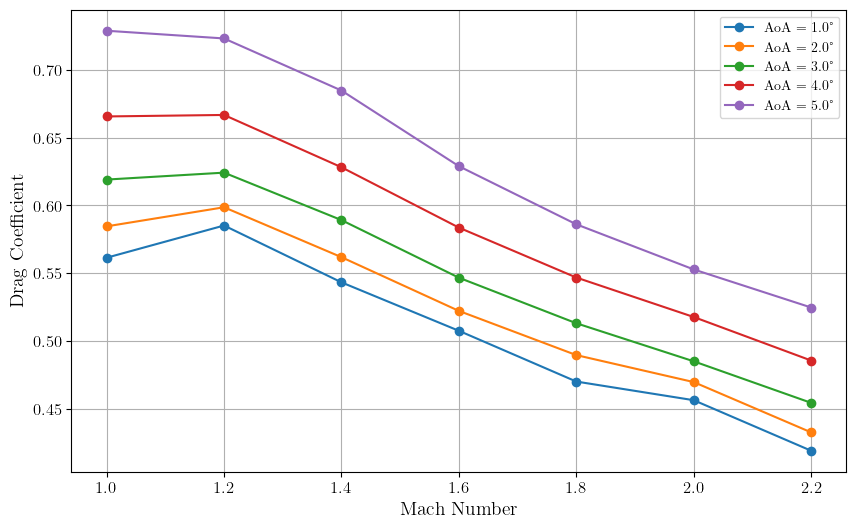

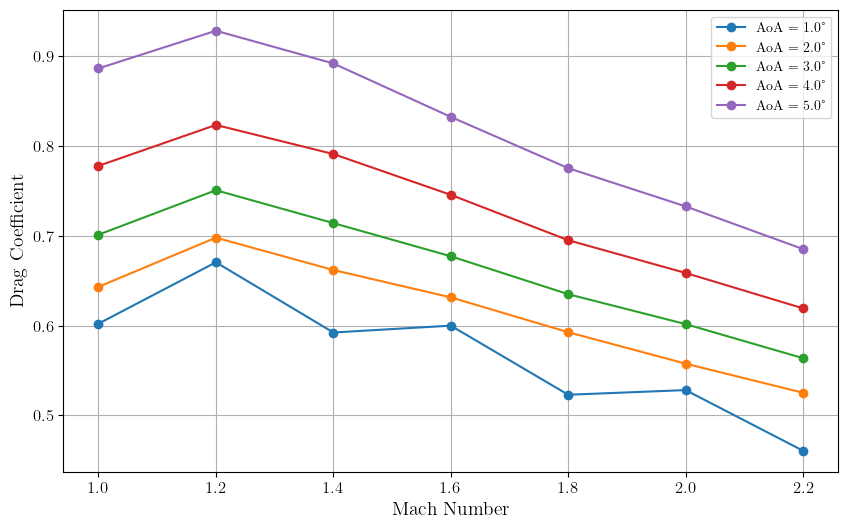

In [39]:
y_column = 'Cd_calc'  # Change this to the column you want to plot

plt.figure(figsize=(10, 6))

# Get unique AoA values
aoa_values = sorted(the_df_one['AoA'].unique())

# Plot each AoA
for aoa in aoa_values:
    data = the_df_one[the_df_one['AoA'] == aoa].sort_values('Ma')
    plt.plot(data['Ma'][:-1], data[y_column][:-1], 'o-', label=f'AoA = {aoa}°')

plt.xlabel('Mach Number')
plt.ylabel('Drag Coefficient')
#plt.title(f'{y_column} vs Mach Number')
plt.legend()
plt.grid(True)

plt.savefig(f"./results/Coeffs/One_{y_column}_vs_Ma.pdf", bbox_inches='tight')



plt.figure(figsize=(10, 6))

# Get unique AoA values
aoa_values = sorted(the_df_two['AoA'].unique())

# Plot each AoA
for aoa in aoa_values:
    data = the_df_two[the_df_two['AoA'] == aoa].sort_values('Ma')
    plt.plot(data['Ma'][:-1], data[y_column][:-1], 'o-', label=f'AoA = {aoa}°')

plt.xlabel('Mach Number')
plt.ylabel('Drag Coefficient')
#plt.title(f'{y_column} vs Mach Number')
plt.legend()
plt.grid(True)

plt.savefig(f"./results/Coeffs/Two_{y_column}_vs_Ma.pdf", bbox_inches='tight')


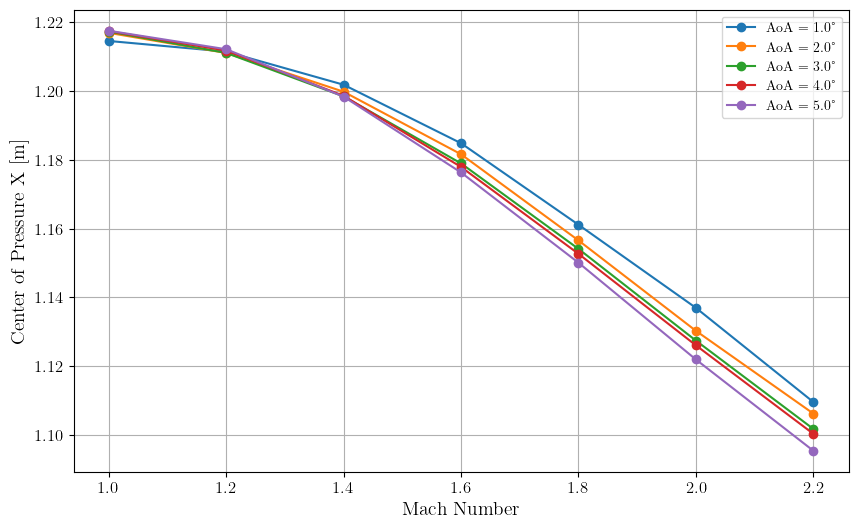

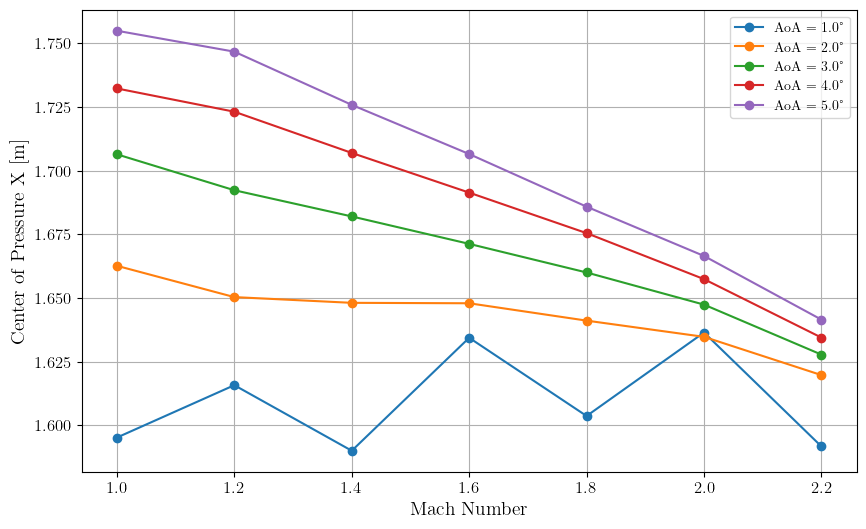

In [40]:
y_column = 'CopX'  # Change this to the column you want to plot

plt.figure(figsize=(10, 6))

# Get unique AoA values
aoa_values = sorted(the_df_one['AoA'].unique())

# Plot each AoA
for aoa in aoa_values:
    data = the_df_one[the_df_one['AoA'] == aoa].sort_values('Ma')
    plt.plot(data['Ma'][:-1], data[y_column][:-1], 'o-', label=f'AoA = {aoa}°')

plt.xlabel('Mach Number')
plt.ylabel('Center of Pressure X [m]')
#plt.title(f'{y_column} vs Mach Number')
plt.legend()
plt.grid(True)

plt.savefig(f"./results/Coeffs/One_{y_column}_vs_Ma.pdf", bbox_inches='tight')



plt.figure(figsize=(10, 6))

# Get unique AoA values
aoa_values = sorted(the_df_two['AoA'].unique())

# Plot each AoA
for aoa in aoa_values:
    data = the_df_two[the_df_two['AoA'] == aoa].sort_values('Ma')
    plt.plot(data['Ma'][:-1], data[y_column][:-1], 'o-', label=f'AoA = {aoa}°')

plt.xlabel('Mach Number')
plt.ylabel('Center of Pressure X [m]')
#plt.title(f'{y_column} vs Mach Number')
plt.legend()
plt.grid(True)

plt.savefig(f"./results/Coeffs/Two_{y_column}_vs_Ma.pdf", bbox_inches='tight')





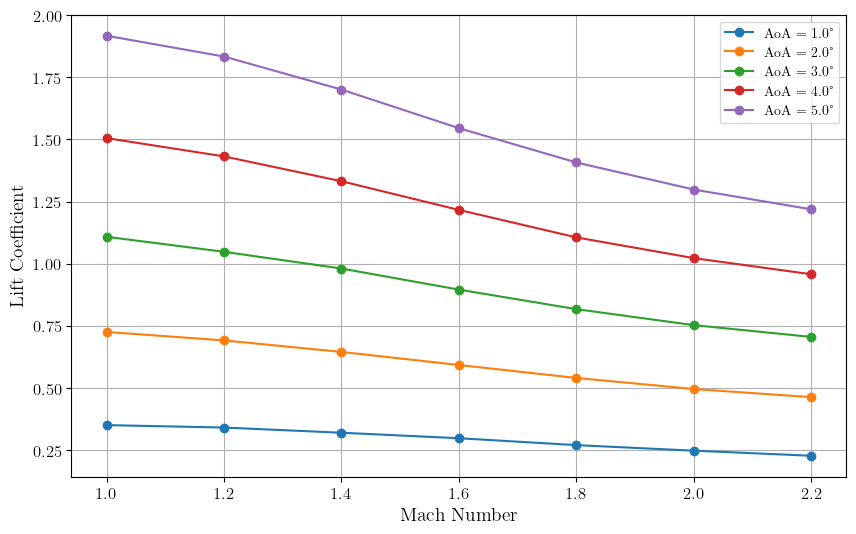

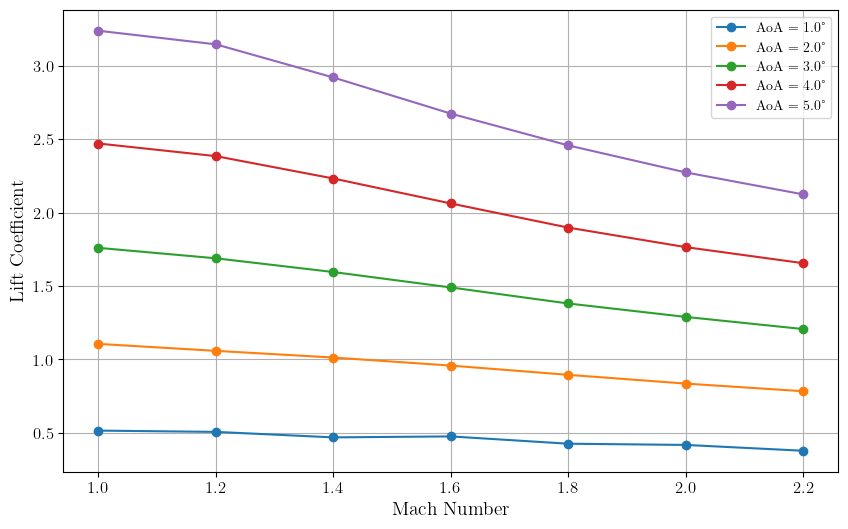

In [41]:
y_column = 'Cl_calc'  # Change this to the column you want to plot

plt.figure(figsize=(10, 6))

# Get unique AoA values
aoa_values = sorted(the_df_one['AoA'].unique())

# Plot each AoA
for aoa in aoa_values:
    data = the_df_one[the_df_one['AoA'] == aoa].sort_values('Ma')
    plt.plot(data['Ma'][:-1], data[y_column][:-1], 'o-', label=f'AoA = {aoa}°')

plt.xlabel('Mach Number')
plt.ylabel('Lift Coefficient')
#plt.title(f'{y_column} vs Mach Number')
plt.legend()
plt.grid(True)

plt.savefig(f"./results/Coeffs/One_{y_column}_vs_Ma.pdf", bbox_inches='tight')



plt.figure(figsize=(10, 6))

# Get unique AoA values
aoa_values = sorted(the_df_two['AoA'].unique())

# Plot each AoA
for aoa in aoa_values:
    data = the_df_two[the_df_two['AoA'] == aoa].sort_values('Ma')
    plt.plot(data['Ma'][:-1], data[y_column][:-1], 'o-', label=f'AoA = {aoa}°')

plt.xlabel('Mach Number')
plt.ylabel('Lift Coefficient')
#plt.title(f'{y_column} vs Mach Number')
plt.legend()
plt.grid(True)

plt.savefig(f"./results/Coeffs/Two_{y_column}_vs_Ma.pdf", bbox_inches='tight')





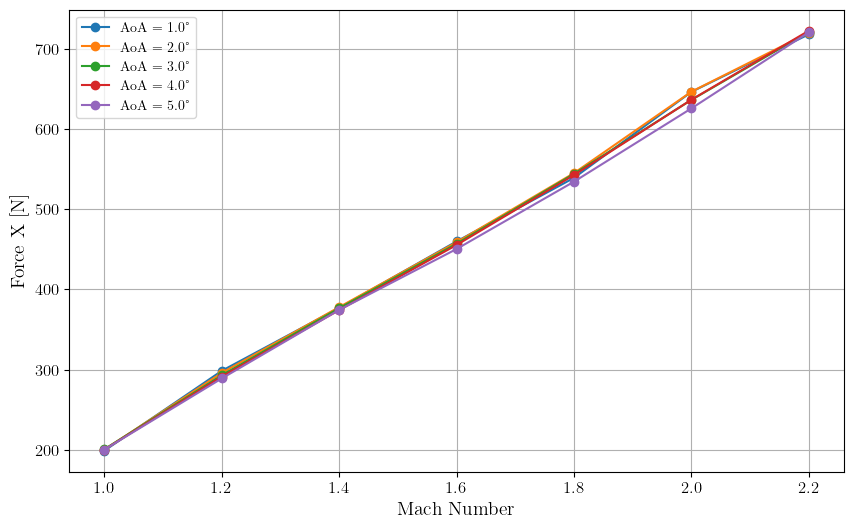

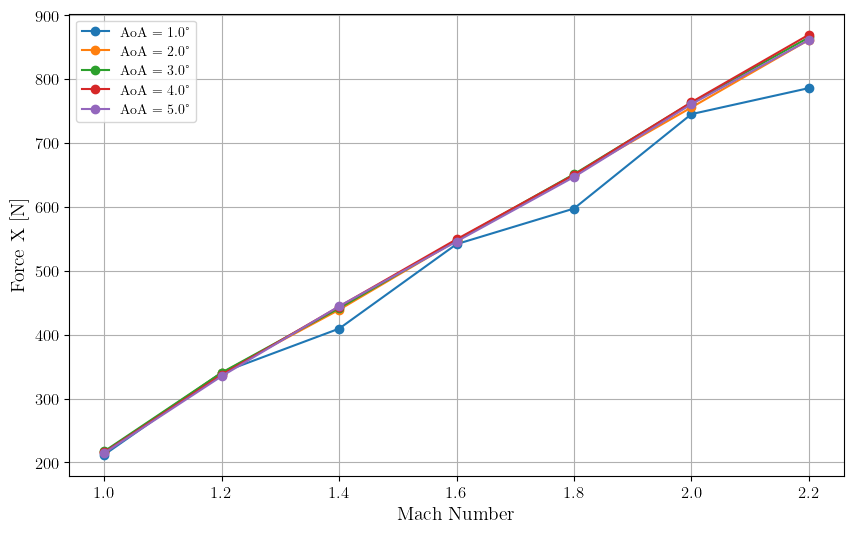

In [42]:
y_column = 'Force_X'  # Change this to the column you want to plot

plt.figure(figsize=(10, 6))

# Get unique AoA values
aoa_values = sorted(the_df_one['AoA'].unique())

# Plot each AoA
for aoa in aoa_values:
    data = the_df_one[the_df_one['AoA'] == aoa].sort_values('Ma')
    plt.plot(data['Ma'][:-1], data[y_column][:-1], 'o-', label=f'AoA = {aoa}°')

plt.xlabel('Mach Number')
plt.ylabel('Force X [N]')
#plt.title(f'{y_column} vs Mach Number')
plt.legend()
plt.grid(True)

plt.savefig(f"./results/Coeffs/One_{y_column}_vs_Ma.pdf", bbox_inches='tight')



plt.figure(figsize=(10, 6))

# Get unique AoA values
aoa_values = sorted(the_df_two['AoA'].unique())

# Plot each AoA
for aoa in aoa_values:
    data = the_df_two[the_df_two['AoA'] == aoa].sort_values('Ma')
    plt.plot(data['Ma'][:-1], data[y_column][:-1], 'o-', label=f'AoA = {aoa}°')

plt.xlabel('Mach Number')
plt.ylabel('Force X [N]')
#plt.title(f'{y_column} vs Mach Number')
plt.legend()
plt.grid(True)

plt.savefig(f"./results/Coeffs/Two_{y_column}_vs_Ma.pdf", bbox_inches='tight')





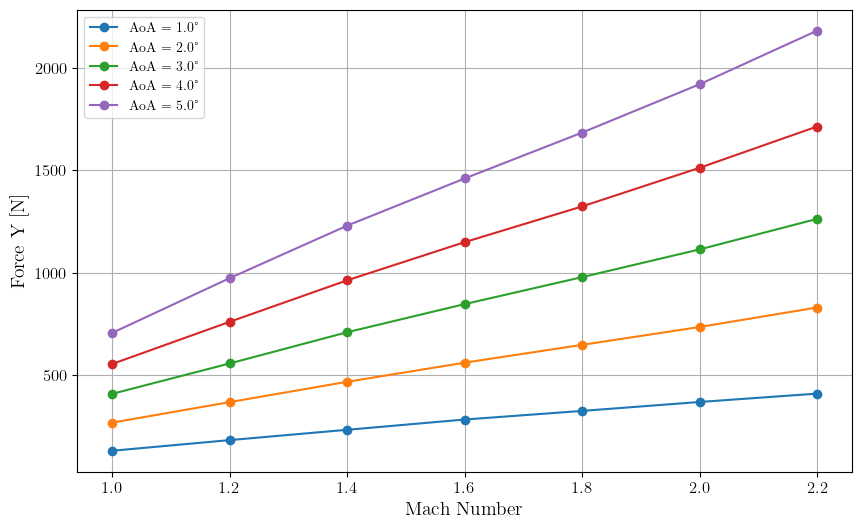

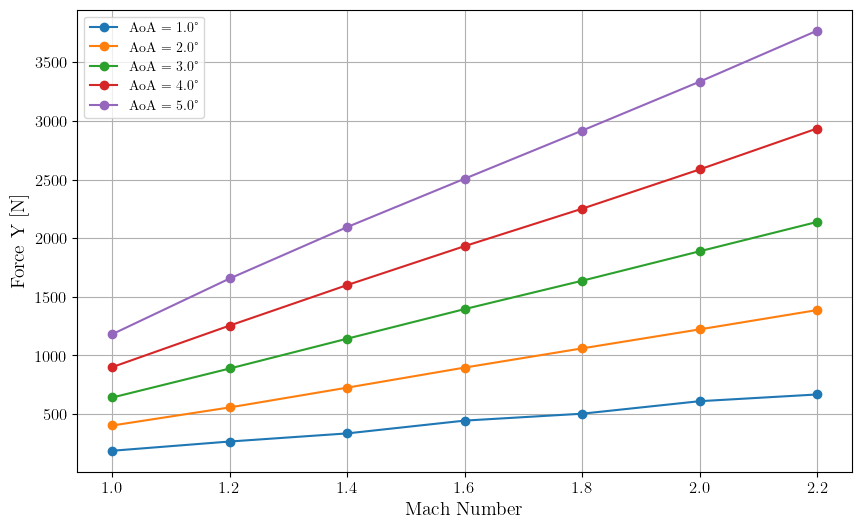

In [43]:
y_column = 'Force_Y'  # Change this to the column you want to plot

plt.figure(figsize=(10, 6))

# Get unique AoA values
aoa_values = sorted(the_df_one['AoA'].unique())

# Plot each AoA
for aoa in aoa_values:
    data = the_df_one[the_df_one['AoA'] == aoa].sort_values('Ma')
    plt.plot(data['Ma'][:-1], data[y_column][:-1], 'o-', label=f'AoA = {aoa}°')

plt.xlabel('Mach Number')
plt.ylabel('Force Y [N]')
#plt.title(f'{y_column} vs Mach Number')
plt.legend()
plt.grid(True)

plt.savefig(f"./results/Coeffs/One_{y_column}_vs_Ma.pdf", bbox_inches='tight')



plt.figure(figsize=(10, 6))

# Get unique AoA values
aoa_values = sorted(the_df_two['AoA'].unique())

# Plot each AoA
for aoa in aoa_values:
    data = the_df_two[the_df_two['AoA'] == aoa].sort_values('Ma')
    plt.plot(data['Ma'][:-1], data[y_column][:-1], 'o-', label=f'AoA = {aoa}°')

plt.xlabel('Mach Number')
plt.ylabel('Force Y [N]')
#plt.title(f'{y_column} vs Mach Number')
plt.legend()
plt.grid(True)

plt.savefig(f"./results/Coeffs/Two_{y_column}_vs_Ma.pdf", bbox_inches='tight')





# NoseTip Temperature

In [179]:
rocket = pv.read("OpenFOAM_Results_gathered/Parametric_Study/TwoStage/Ma_1p8_AoA_4p0/postProcessing/rocketVTK/8000/rocketWall.vtp")

Failed to read OpenFOAM_Results_gathered/Parametric_Study/OneStage/Ma_0p8_AoA_3p0: File (OpenFOAM_Results_gathered/Parametric_Study/OneStage/Ma_0p8_AoA_3p0/postProcessing/rocketVTK/8000/rocketWall.vtp) not found
Failed to read OpenFOAM_Results_gathered/Parametric_Study/OneStage/Ma_0p8_AoA_2p0: File (OpenFOAM_Results_gathered/Parametric_Study/OneStage/Ma_0p8_AoA_2p0/postProcessing/rocketVTK/8000/rocketWall.vtp) not found
Failed to read OpenFOAM_Results_gathered/Parametric_Study/OneStage/Ma_0p8_AoA_1p0: File (OpenFOAM_Results_gathered/Parametric_Study/OneStage/Ma_0p8_AoA_1p0/postProcessing/rocketVTK/8000/rocketWall.vtp) not found
Failed to read OpenFOAM_Results_gathered/Parametric_Study/OneStage/Ma_0p8_AoA_5p0: File (OpenFOAM_Results_gathered/Parametric_Study/OneStage/Ma_0p8_AoA_5p0/postProcessing/rocketVTK/8000/rocketWall.vtp) not found
Failed to read OpenFOAM_Results_gathered/Parametric_Study/OneStage/Ma_0p8_AoA_4p0: File (OpenFOAM_Results_gathered/Parametric_Study/OneStage/Ma_0p8_AoA_

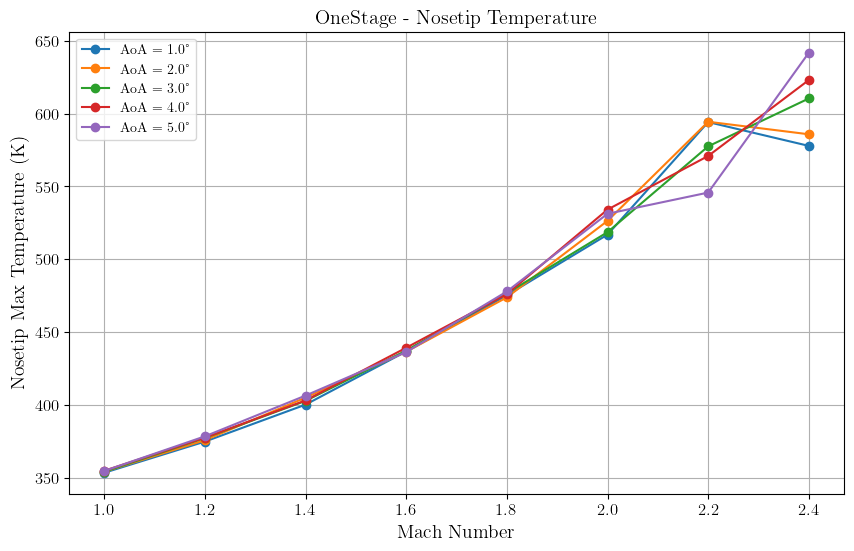

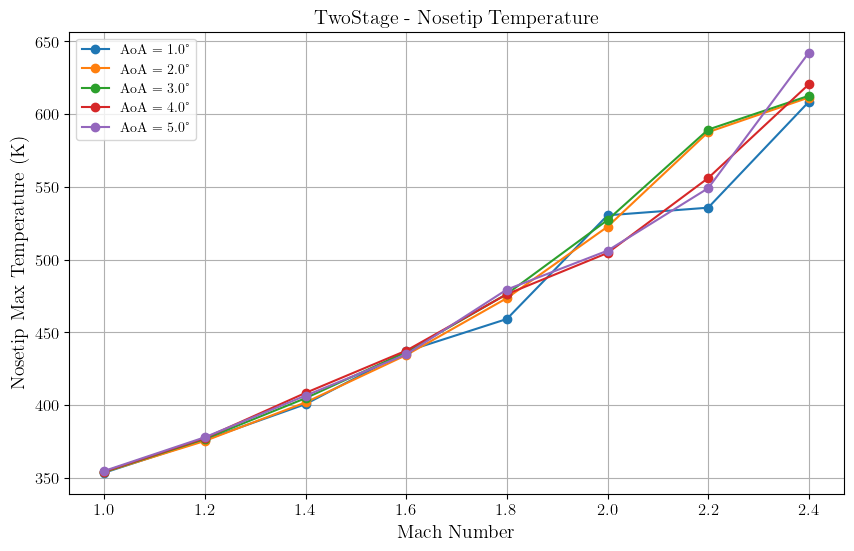

In [190]:

cases = ["OneStage", "TwoStage"]
t = 8000

fig_one, ax_one = plt.subplots(figsize=(10, 6))
fig_two, ax_two = plt.subplots(figsize=(10, 6))

axes = {"OneStage": ax_one, "TwoStage": ax_two}
results = {"OneStage": {}, "TwoStage": {}}

for case in cases:
    paths = glob.glob(f"OpenFOAM_Results_gathered/Parametric_Study/{case}/Ma_*_AoA_*")
    
    for path in paths:
        # Parse Ma and AoA
        folder_name = os.path.basename(path)
        parts = folder_name.split('_')
        Ma = float(parts[1].replace('p', '.'))
        AoA = float(parts[3].replace('p', '.'))
        
        # Load rocket surface
        try:
            rocket = pv.read(f"{path}/postProcessing/rocketVTK/{t}/rocketWall.vtp")
        except Exception as e:
            print(f"Failed to read {path}: {e}")
            continue
        
        # Get nosetip max temperature
        points = rocket.points
        T = rocket.point_data['T']
        
        mask = (
            (np.abs(points[:, 0]) <= 0.01) & 
            (np.abs(points[:, 1]) <= 0.01) & 
            (np.abs(points[:, 2]) <= 0.01)
        )
        
        T_max = T[mask].max()
        
        # Store results grouped by AoA
        if AoA not in results[case]:
            results[case][AoA] = {'Ma': [], 'T': []}
        results[case][AoA]['Ma'].append(Ma)
        results[case][AoA]['T'].append(T_max)

# Plot
colors = plt.cm.tab10(range(10))

for case, ax in axes.items():
    for i, (AoA, data) in enumerate(sorted(results[case].items())):
        # Sort by Ma
        sorted_idx = np.argsort(data['Ma'])
        Ma_sorted = np.array(data['Ma'])[sorted_idx]
        T_sorted = np.array(data['T'])[sorted_idx]
        
        ax.plot(Ma_sorted, T_sorted, 'o-', color=colors[i], label=f'AoA = {AoA}°')
    
    ax.set_xlabel('Mach Number')
    ax.set_ylabel('Nosetip Max Temperature (K)')
    ax.set_title(f'{case} - Nosetip Temperature')
    ax.legend()
    ax.grid(True)

    ax.figure.savefig(f"./results/Nosetip_Temperature_{case}.pdf", bbox_inches='tight')


# Residuals


In [53]:
base_dir = "OpenFOAM_Results_gathered/Parametric_Study/OneStage"
cases = os.listdir(base_dir)

solverInfo = []
for case in cases:
    match = re.match(r"Ma_(\d+p\d+)_AoA_(\d+p\d+)", case)
    if match:
        try:
            solve_path = os.path.join(base_dir, case, "postProcessing", "solverInfo")
            times = os.listdir(solve_path)
            solver = load_dat(os.path.join(base_dir, case, "postProcessing", "solverInfo", times[-1], "solverInfo.dat"))
            solver['case'] = case
            solverInfo.append(solver)
        except:
            print(f"Could not load solver info for case: {case}")
        
solver_df_One = pd.concat(solverInfo, ignore_index=True)
solver_df_One.head()

Could not load solver info for case: Ma_2p4_AoA_1p0


,Time,U_solver,Ux_initial,Ux_final,Ux_iters,Uy_initial,Uy_final,Uy_iters,Uz_initial,Uz_final,...,omega_initial,omega_final,omega_iters,omega_converged,p_solver,p_initial,p_final,p_iters,p_converged,case
0,1,DILUPBiCGStab,0.999631,8.722240e-11,5,0.999668,8.270760e-11,5,1.000000,1.155920e-10,...,7.638430e-07,2.311450e-16,5,True,DILUPBiCGStab,1.000000,3.906310,100,False,Ma_2p0_AoA_3p0
1,2,DILUPBiCGStab,0.000015,3.974070e-15,5,0.000043,3.220750e-14,5,0.001120,8.282530e-14,...,2.362010e-07,1.466530e-17,5,True,DILUPBiCGStab,0.000643,0.000232,100,False,Ma_2p0_AoA_3p0
2,3,DILUPBiCGStab,0.000009,1.846540e-15,5,0.000042,2.146680e-14,5,0.001208,1.025120e-13,...,1.518060e-07,1.167530e-17,5,True,DILUPBiCGStab,0.000643,0.000020,100,False,Ma_2p0_AoA_3p0
3,4,DILUPBiCGStab,0.000008,1.194750e-15,5,0.000082,2.725420e-14,5,0.002753,2.021780e-13,...,9.556310e-08,4.934480e-18,5,True,DILUPBiCGStab,0.000771,0.000019,100,False,Ma_2p0_AoA_3p0
4,5,DILUPBiCGStab,0.000008,1.016060e-15,5,0.000093,1.264910e-14,5,0.003597,6.816950e-13,...,7.174280e-08,1.210790e-16,5,True,DILUPBiCGStab,0.000865,0.000026,100,False,Ma_2p0_AoA_3p0


In [54]:
base_dir = "OpenFOAM_Results_gathered/Parametric_Study/TwoStage"
cases = os.listdir(base_dir)

solverInfo = []
for case in cases:
    match = re.match(r"Ma_(\d+p\d+)_AoA_(\d+p\d+)", case)
    if match:
        try:
            solve_path = os.path.join(base_dir, case, "postProcessing", "solverInfo")
            times = os.listdir(solve_path)
            solver = load_dat(os.path.join(base_dir, case, "postProcessing", "solverInfo", times[-1], "solverInfo.dat"))
            solver['case'] = case
            solverInfo.append(solver)
        except:
            print(f"Could not load solver info for case: {case}")
        
solver_df_Two = pd.concat(solverInfo, ignore_index=True)
solver_df_Two.head()

Could not load solver info for case: Ma_1p2_AoA_1p0
Could not load solver info for case: Ma_1p2_AoA_2p0


,Time,U_solver,Ux_initial,Ux_final,Ux_iters,Uy_initial,Uy_final,Uy_iters,Uz_initial,Uz_final,...,omega_initial,omega_final,omega_iters,omega_converged,p_solver,p_initial,p_final,p_iters,p_converged,case
0,1,DILUPBiCGStab,0.999737,2.738620e-11,5,0.999725,2.533650e-11,5,1.000000,4.668300e-11,...,2.085250e-06,4.470590e-16,5,True,DILUPBiCGStab,1.000000,4.730610,100,False,Ma_1p4_AoA_5p0
1,2,DILUPBiCGStab,0.000038,2.243020e-13,5,0.000075,1.070240e-14,5,0.010142,3.776730e-12,...,5.917250e-07,8.325950e-17,5,True,DILUPBiCGStab,0.000921,0.000121,100,False,Ma_1p4_AoA_5p0
2,3,DILUPBiCGStab,0.000024,1.900120e-15,5,0.000070,7.718060e-15,5,0.011092,2.691510e-12,...,4.965590e-07,1.384430e-17,5,True,DILUPBiCGStab,0.001442,0.000110,100,False,Ma_1p4_AoA_5p0
3,4,DILUPBiCGStab,0.000022,3.192360e-15,5,0.000114,1.375830e-14,5,0.022264,1.366900e-11,...,5.844350e-07,1.676180e-17,5,True,DILUPBiCGStab,0.002252,0.000051,100,False,Ma_1p4_AoA_5p0
4,5,DILUPBiCGStab,0.000022,2.406940e-15,5,0.000137,1.569850e-14,5,0.031760,2.730890e-12,...,3.222340e-07,2.009370e-17,5,True,DILUPBiCGStab,0.003091,0.000111,100,False,Ma_1p4_AoA_5p0


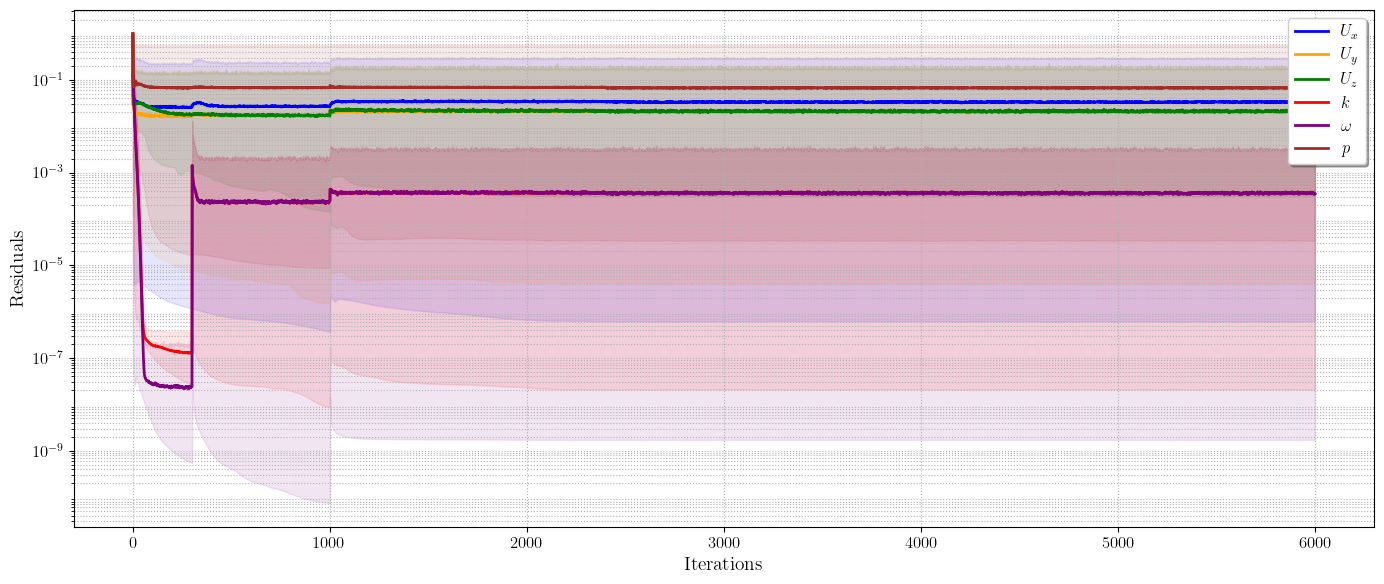

In [55]:
plt.figure(figsize=(14, 6))

components = ['Ux', 'Uy', 'Uz', 'k', 'omega', 'p']
colors = ['blue', 'orange', 'green', 'red', 'purple', 'brown']


dict_labels = {
"Ux": "$U_x$",
"Uy": "$U_y$",
"Uz": "$U_z$",
"k": "$k$",
"omega": "$\\omega$",
"p": "$p$"
}

for i, component in enumerate(components):
    grouped = solver_df_One.groupby('Time')[f'{component}_initial']
    time = grouped.mean().index[:6000]
    mean = grouped.mean().values[:6000]
    min_vals = grouped.min().values[:6000]
    max_vals = grouped.max().values[:6000]

    # Fill between min and max
    plt.fill_between(
        time, min_vals, max_vals, 
        color=colors[i], alpha=0.1
    )

    # Plot mean as solid line
    plt.plot(
        time, mean, 
        label=f'{dict_labels[component]}', 
        color=colors[i], linewidth=2
    )

# Log scale
# Log scale on y-axis
plt.yscale('log')

# Set major and minor ticks explicitly
plt.gca().yaxis.set_major_locator(LogLocator(base=10.0, subs=(1.0,), numticks=10))
plt.gca().yaxis.set_minor_locator(LogLocator(base=10.0, subs=np.arange(2, 10)*0.1, numticks=100))
plt.gca().yaxis.set_minor_formatter(NullFormatter())  # hide minor tick labels

# Grid: dotted for both
plt.grid(True, which='both', linestyle=':', linewidth=0.8)


plt.xlabel('Iterations', fontsize=14)
plt.ylabel('Residuals', fontsize=14)
plt.legend(fontsize=12, loc='upper right', frameon=True, shadow=True)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.tight_layout()


plt.savefig("./results/Onesolver_residuals.pdf", bbox_inches='tight')

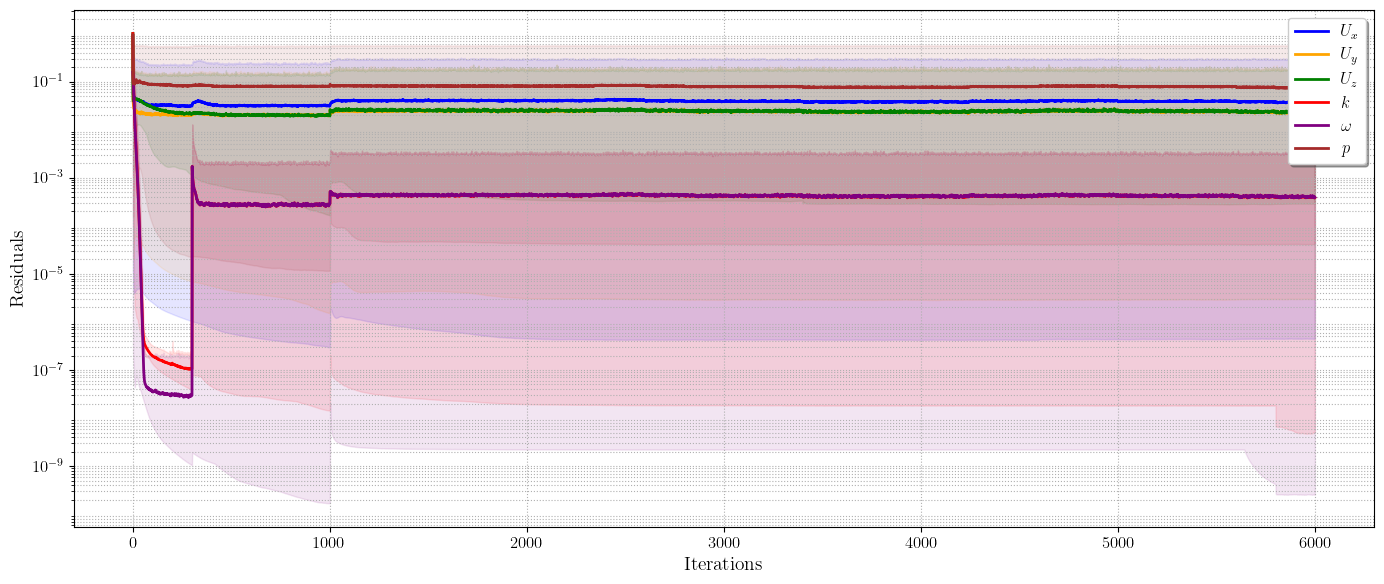

In [56]:
plt.figure(figsize=(14, 6))

components = ['Ux', 'Uy', 'Uz', 'k', 'omega', 'p']
colors = ['blue', 'orange', 'green', 'red', 'purple', 'brown']


dict_labels = {
"Ux": "$U_x$",
"Uy": "$U_y$",
"Uz": "$U_z$",
"k": "$k$",
"omega": "$\\omega$",
"p": "$p$"
}

for i, component in enumerate(components):
    grouped = solver_df_Two.groupby('Time')[f'{component}_initial']
    time = grouped.mean().index[:6000]
    mean = grouped.mean().values[:6000]
    min_vals = grouped.min().values[:6000]
    max_vals = grouped.max().values[:6000]

    # Fill between min and max
    plt.fill_between(
        time, min_vals, max_vals, 
        color=colors[i], alpha=0.1
    )

    # Plot mean as solid line
    plt.plot(
        time, mean, 
        label=f'{dict_labels[component]}', 
        color=colors[i], linewidth=2
    )

# Log scale
# Log scale on y-axis
plt.yscale('log')

# Set major and minor ticks explicitly
plt.gca().yaxis.set_major_locator(LogLocator(base=10.0, subs=(1.0,), numticks=10))
plt.gca().yaxis.set_minor_locator(LogLocator(base=10.0, subs=np.arange(2, 10)*0.1, numticks=100))
plt.gca().yaxis.set_minor_formatter(NullFormatter())  # hide minor tick labels

# Grid: dotted for both
plt.grid(True, which='both', linestyle=':', linewidth=0.8)


plt.xlabel('Iterations', fontsize=14)
plt.ylabel('Residuals', fontsize=14)
plt.legend(fontsize=12, loc='upper right', frameon=True, shadow=True)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.tight_layout()


plt.savefig("./results/Twosolver_residuals.pdf", bbox_inches='tight')

In [57]:
base_dir = "Data/CollectedResults"
base_dir = "OpenFOAM_Results_gathered/Parametric_Study/TwoStage"

cases = os.listdir(base_dir)

coeff = []
for case in cases:
    match = re.match(r"Ma_(\d+p\d+)_AoA_(\d+p\d+)", case)
    if match:
        try:
            data = load_dat(os.path.join(base_dir, case, "postProcessing", "forceCoeffs", "0", "coefficient.dat"))
            data['case'] = case
            coeff.append(data)
        except:
            print(f"Could not load coefficients for case: {case}")


coeff_df_Two = pd.concat(coeff, ignore_index=True)
coeff_df_Two.head()

Could not load coefficients for case: Ma_2p2_AoA_1p0
Could not load coefficients for case: Ma_1p2_AoA_1p0
Could not load coefficients for case: Ma_1p2_AoA_2p0
Could not load coefficients for case: Ma_1p8_AoA_1p0


,Time,Cd,Cd(f),Cd(r),Cl,Cl(f),Cl(r),CmPitch,CmRoll,CmYaw,Cs,Cs(f),Cs(r),case
0,1,2.467369,1.233705,1.233664,18.624700,-0.480739,19.105430,-9.793087,2.069039e-05,0.000241,0.004720,0.002601,0.002119,Ma_1p4_AoA_5p0
1,2,1.735882,0.867917,0.867965,12.232240,-0.386595,12.618840,-6.502716,-2.367252e-05,-0.000263,-0.006574,-0.003549,-0.003024,Ma_1p4_AoA_5p0
2,3,1.282486,0.641220,0.641266,7.903906,-0.264755,8.168661,-4.216708,-2.306593e-05,-0.000263,-0.005749,-0.003138,-0.002611,Ma_1p4_AoA_5p0
3,4,0.926459,0.463217,0.463242,4.234493,-0.093178,4.327672,-2.210425,-1.243855e-05,-0.000139,-0.003218,-0.001748,-0.001471,Ma_1p4_AoA_5p0
4,5,0.722939,0.361470,0.361469,2.115592,0.046565,2.069028,-1.011232,1.511742e-07,0.000006,-0.000057,-0.000023,-0.000035,Ma_1p4_AoA_5p0


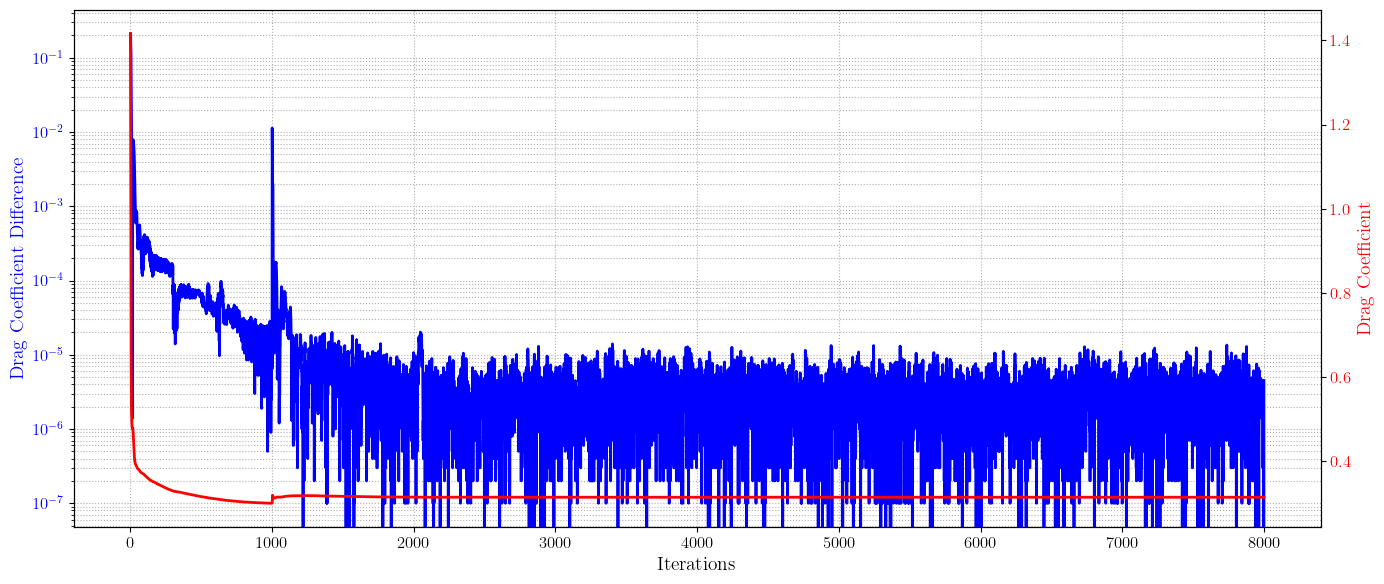

In [59]:
fig, ax1 = plt.subplots(figsize=(14, 6))

# Primary Y-axis: |ΔCd|
color1 = 'blue'
cd_diff = np.abs(np.diff(data['Cd']))
ax1.plot(data['Time'][:-1], cd_diff, color=color1, label='|ΔCd|', linewidth=2)
ax1.set_xlabel('Iterations', fontsize=14)
ax1.set_ylabel('Drag Coefficient Difference', color=color1, fontsize=14)
ax1.set_yscale('log')
ax1.tick_params(axis='y', labelcolor=color1)
ax1.grid(True, which='both', linestyle=':', linewidth=0.8)

# Secondary Y-axis: Cd
ax2 = ax1.twinx()
color2 = 'red'
ax2.plot(data['Time'], data['Cd'], color=color2, label='Cd', linewidth=2)
ax2.set_ylabel('Drag Coefficient', color=color2, fontsize=14)
ax2.tick_params(axis='y', labelcolor=color2)

# Title and layout
#plt.title('Cd and |ΔCd| vs Time', fontsize=16, fontweight='bold')
fig.tight_layout()

plt.savefig("./results/Two_Cd_and_deltaCd_vs_Time.pdf", bbox_inches='tight')

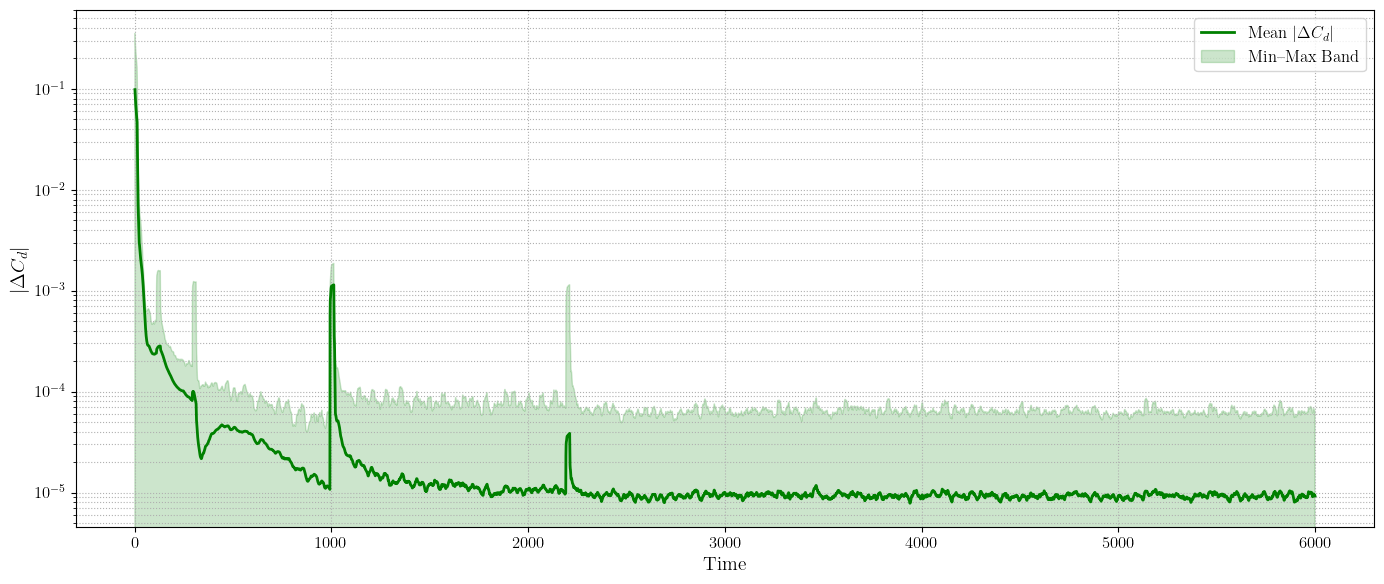

In [61]:
cd_df_sorted = coeff_df_Two.sort_values(by=['case', 'Time'])
cd_df_sorted['Cd_diff'] = cd_df_sorted.groupby('case')['Cd'].diff().abs()

# Step 2: Group by Time across all cases
grouped = cd_df_sorted.groupby('Time')['Cd_diff']
time = grouped.mean().index[:6000]
cd_diff_mean = grouped.mean()
cd_diff_min = grouped.min()
cd_diff_max = grouped.max()

# Step 3: Apply smoothing
window = 20  # number of points in the moving window
mean_smooth = cd_diff_mean.rolling(window, center=True, min_periods=1).mean()[:6000]
min_smooth = cd_diff_min.rolling(window, center=True, min_periods=1).mean()[:6000]
max_smooth = cd_diff_max.rolling(window, center=True, min_periods=1).mean()[:6000]

# Step 4: Plot
plt.figure(figsize=(14, 6))
plt.plot(time, mean_smooth, color='green', linewidth=2, label=r'Mean $|\Delta C_d|$')
plt.fill_between(time, min_smooth, max_smooth, color='green', alpha=0.2, label='Min–Max Band')

plt.yscale('log')
plt.xlabel('Time', fontsize=14)
plt.ylabel(r'$|\Delta C_d|$', fontsize=14)
plt.grid(True, which='both', linestyle=':', linewidth=0.8)
plt.legend(fontsize=12, loc='upper right')
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.tight_layout()
plt.savefig("./results/Two_mean_Cd_diff_vs_Time.pdf", bbox_inches='tight')


In [ ]:
base_dir = "Data/CollectedResults"
base_dir = "OpenFOAM_Results_gathered/Parametric_Study/TwoStage"
    
cases = os.listdir(base_dir)

yp = []
for case in cases:
    match = re.match(r"AoA_(\d+p\d+)_Ma_(\d+p\d+)", case)
    if match:
        data = load_dat(os.path.join(base_dir, case, "postProcessing", "yPlus1", "0", "yPlus.dat"))
        data['case'] = case
        yp.append(data)


yp_df = pd.concat(yp, ignore_index=True)
yp_mean = yp_df.groupby('Time')['max'].mean().reset_index()
yp_min = yp_df.groupby('Time')['max'].min().reset_index()
yp_max = yp_df.groupby('Time')['max'].max().reset_index()

plt.figure(figsize=(14, 6))
plt.plot(yp_mean['Time'], yp_mean['max'], label='Mean y+', color='blue', linewidth=2)
plt.fill_between(yp_mean['Time'], yp_min['max'], yp_max['max'], color='blue', alpha=0.2, label='Min–Max Band')

plt.xlabel('Time', fontsize=14)
plt.ylabel('y+', fontsize=14)

# Validation

In [67]:
rasero_one_df = pd.read_csv("validation/OneStage_new.csv")
rasero_two_df = pd.read_csv("validation/TwoStage_new.csv")


In [68]:
rasero_one_df

,Mach,alpha,CD,CD Power-Off,CD Power-On,CA Power-Off,CA Power-On,CL,CN,CN Potential,CN Viscous,CNalpha (0 to 4 deg) (per rad),CP,CP (0 to 4 deg),Reynolds Number
0,0.01,0,0.652446,0.652446,0.642195,0.652446,0.642195,0.000000,0.000000,0.000000,0.000000,13.303582,54.171386,52.288554,397681.7
1,0.02,0,0.580013,0.580013,0.569762,0.580013,0.569762,0.000000,0.000000,0.000000,0.000000,13.303582,54.171386,52.288554,795363.3
2,0.03,0,0.544228,0.544228,0.533977,0.544228,0.533977,0.000000,0.000000,0.000000,0.000000,13.303582,54.171386,52.288554,1193045.0
3,0.04,0,0.521319,0.521319,0.511068,0.521319,0.511068,0.000000,0.000000,0.000000,0.000000,13.303582,54.171386,52.288554,1590727.0
4,0.05,0,0.504819,0.504819,0.494569,0.504819,0.494569,0.000000,0.000000,0.000000,0.000000,13.303582,54.171386,52.288554,1988408.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7494,24.95,4,0.078212,0.097974,0.097572,0.078594,0.078192,0.274421,0.280559,0.182406,0.098153,4.018709,28.960292,28.960290,992215800.0
7495,24.96,4,0.078209,0.097970,0.097569,0.078592,0.078190,0.274407,0.280544,0.182391,0.098153,4.018501,28.960391,28.960388,992613400.0
7496,24.97,4,0.078206,0.097966,0.097565,0.078589,0.078187,0.274392,0.280530,0.182377,0.098153,4.018294,28.960484,28.960481,993011100.0
7497,24.98,4,0.078204,0.097962,0.097562,0.078586,0.078185,0.274378,0.280515,0.182362,0.098153,4.018087,28.960581,28.960579,993408800.0


In [69]:
rasero_two_df

,Time (sec),Stage,Stage Time (sec),Mach Number,Angle of Attack (deg),CD,CL,Thrust (lb),Weight (lb),Drag (lb),...,Accel-H (ft/sec^2),Velocity (ft/sec),Vel-V (ft/sec),Vel-H (ft/sec),Pitch Attitude (deg),Flight Path Angle (deg),Altitude (ft),Distance (ft),Dynamic Pressure Q (lb/in^2),Ref Area (in^2)
0,0.0000,B,0.0000,0.000000,0.0,0.000000,0.0,0.0000,42.40000,0.000000,...,0.000000,0.000000,0.000000,0.000000,83.0,83.000000,0.000000,0.000000,NaN,9.4297
1,0.0100,B,0.0100,0.010000,0.0,1.185017,0.0,204.8725,42.40000,0.000000,...,18.945990,22.228035,1.221287,0.189460,83.0,83.000000,0.006106,0.000947,0.000000,NaN
2,0.0200,B,0.0200,0.019841,0.0,1.046064,0.0,407.2115,42.39488,0.036048,...,37.658900,22.916943,3.966618,0.566049,83.0,83.000000,0.032046,0.004725,0.003654,NaN
3,0.0300,B,0.0300,0.020456,0.0,1.040514,0.0,450.9392,42.37952,0.038113,...,41.718117,24.042798,7.042546,0.983230,83.0,83.000000,0.087092,0.012471,0.003884,NaN
4,0.0400,B,0.0400,0.021461,0.0,1.031892,0.0,447.9062,42.35674,0.041602,...,41.459472,25.488230,10.097410,1.397825,83.0,83.000000,0.172791,0.024377,0.004276,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12252,716.9406,S,712.6306,0.016266,0.0,1.500000,0.0,0.0000,12.98540,0.011806,...,0.000000,-18.222600,-18.222600,-22.005000,0.0,-0.032664,9.200209,10283.400000,0.000835,NaN
12253,717.0405,S,712.7305,0.016266,0.0,1.500000,0.0,0.0000,12.98540,0.011806,...,0.000000,-18.222140,-18.222140,-22.005000,0.0,-0.032664,7.377995,10281.200000,0.000835,NaN
12254,717.1405,S,712.8305,0.016265,0.0,1.500000,0.0,0.0000,12.98540,0.011806,...,0.000000,-18.221670,-18.221670,-22.005000,0.0,-0.032664,5.555828,10279.000000,0.000835,NaN
12255,717.2405,S,712.9305,0.016265,0.0,1.500000,0.0,0.0000,12.98540,0.011806,...,0.000000,-18.221200,-18.221200,-22.005000,0.0,-0.032664,3.733707,10276.800000,0.000835,NaN


In [70]:
the_df_one

,AoA,Ma,iterations,CopX,CopY,CopZ,Force_X,Force_Y,Force_Z,Moment_X,Moment_Y,Moment_Z,Cd,Cl,CmPitch,Cd_calc,Cl_calc,Drag,Lift,case_name
0,1.0,1.0,8000.0,1.214551,-0.790742,0.000845,198.597817,129.302272,-0.237766,0.212327,0.167789,157.039630,0.245575,0.107715,-0.045145,0.561467,0.351746,-200.810238,-125.802876,Ma_1p0_AoA_1p0
1,1.0,1.2,8000.0,1.211449,-0.736575,0.000486,298.300084,181.375132,-0.090136,0.184175,0.144923,219.720329,0.249272,0.104363,-0.043672,0.585232,0.341982,-301.406117,-176.127760,Ma_1p2_AoA_1p0
2,1.0,1.4,8000.0,1.201822,-0.738932,-0.005163,376.879810,231.728681,1.590707,0.169748,-1.945795,278.488517,0.233073,0.098170,-0.040710,0.543299,0.321116,-380.852666,-225.102250,Ma_1p4_AoA_1p0
3,1.0,1.6,8000.0,1.184813,-0.726164,-0.004305,459.874669,281.862470,1.854045,0.185474,-1.979774,333.944426,0.218925,0.091001,-0.037246,0.507551,0.299020,-464.709840,-273.779933,Ma_1p6_AoA_1p0
4,1.0,1.8,8000.0,1.161120,-0.697446,-0.002423,539.203752,323.891545,1.913254,0.181272,-1.306553,376.065545,0.204546,0.083073,-0.033333,0.470109,0.271332,-544.760349,-314.418141,Ma_1p8_AoA_1p0
5,1.0,2.0,8000.0,1.136956,-0.646335,-0.001072,646.552997,367.562599,0.911100,0.185631,-0.692839,417.889754,0.198112,0.076367,-0.030057,0.456347,0.248991,-652.855408,-356.209007,Ma_2p0_AoA_1p0
6,1.0,2.2,8000.0,1.109579,-0.630680,0.002106,718.414522,408.356533,-0.762329,0.266128,1.513231,453.089745,0.183839,0.071011,-0.027257,0.419065,0.228615,-725.417942,-395.742583,Ma_2p2_AoA_1p0
7,1.0,2.4,8000.0,1.093033,-0.727605,0.003015,694.506397,462.330479,-2.072454,0.347723,2.093637,505.326265,0.236529,0.112742,-0.062066,0.340984,0.218499,-702.455433,-450.125585,Ma_2p4_AoA_1p0
8,2.0,1.0,8000.0,1.216916,-1.624426,0.007498,199.911312,266.863552,-1.343682,0.269035,1.498865,324.741187,0.252494,0.222799,-0.093517,0.584613,0.726153,-209.088731,-259.710737,Ma_1p0_AoA_2p0
9,2.0,1.2,8000.0,1.211051,-1.503235,0.005305,295.724275,367.082704,-1.086959,0.229710,1.568956,444.543098,0.252502,0.212494,-0.088873,0.598697,0.692254,-308.340926,-356.525021,Ma_1p2_AoA_2p0


In [71]:
rasero_one_df[rasero_one_df['alpha'] == 2]

,Mach,alpha,CD,CD Power-Off,CD Power-On,CA Power-Off,CA Power-On,CL,CN,CN Potential,CN Viscous,CNalpha (0 to 4 deg) (per rad),CP,CP (0 to 4 deg),Reynolds Number
2500,0.01,2,0.652446,0.668195,0.657938,0.653241,0.642978,0.417167,0.439874,0.415306,0.024568,13.303582,53.176305,52.288554,397681.7
2501,0.02,2,0.580013,0.595718,0.585460,0.580720,0.570457,0.419698,0.439874,0.415306,0.024568,13.303582,53.176305,52.288554,795363.3
2502,0.03,2,0.544228,0.559911,0.549654,0.544892,0.534628,0.420948,0.439874,0.415306,0.024568,13.303582,53.176305,52.288554,1193045.0
2503,0.04,2,0.521319,0.536988,0.526731,0.521954,0.511691,0.421749,0.439874,0.415306,0.024568,13.303582,53.176305,52.288554,1590727.0
2504,0.05,2,0.504819,0.520479,0.510221,0.505435,0.495172,0.422325,0.439874,0.415306,0.024568,13.303582,53.176305,52.288554,1988408.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,24.96,2,0.078209,0.082467,0.082066,0.078305,0.077904,0.117835,0.120628,0.091196,0.029432,4.018501,27.756122,28.960388,992613400.0
4996,24.97,2,0.078206,0.082464,0.082064,0.078302,0.077902,0.117823,0.120615,0.091188,0.029427,4.018294,27.755780,28.960481,993011100.0
4997,24.98,2,0.078204,0.082460,0.082061,0.078299,0.077899,0.117811,0.120603,0.091181,0.029422,4.018087,27.755442,28.960579,993408800.0
4998,24.99,2,0.078201,0.082457,0.082058,0.078296,0.077897,0.117798,0.120590,0.091174,0.029416,4.017880,27.755105,28.960676,993806500.0


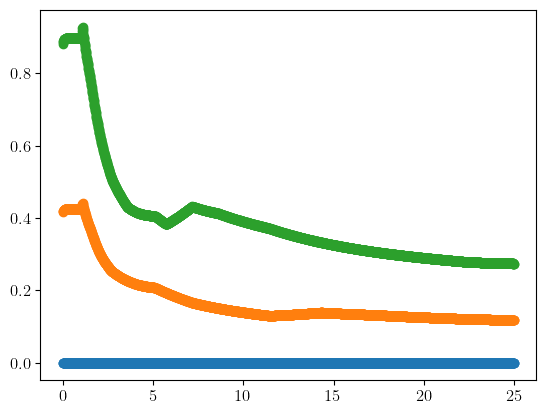

In [73]:
plt.plot(rasero_one_df[rasero_one_df['alpha'] == 0]['Mach'], rasero_one_df[rasero_one_df['alpha'] == 0]['CL'], 'o-', label='One Stage Sim AoA=0°')
plt.plot(rasero_one_df[rasero_one_df['alpha'] == 2]['Mach'], rasero_one_df[rasero_one_df['alpha'] == 2]['CL'], 'o-', label='One Stage Sim AoA=2°')
plt.plot(rasero_one_df[rasero_one_df['alpha'] == 4]['Mach'], rasero_one_df[rasero_one_df['alpha'] == 4]['CL'], 'o-', label='One Stage Sim AoA=4°')



In [81]:
def merge_cfd_rasero(cfd_df, rasero_df):
    """Merge CFD and Rasero data for all matching AoAs."""
    dfs = []
    for AoA in cfd_df['AoA'].unique():
        cfd = cfd_df[cfd_df['AoA'] == AoA][['Ma', 'AoA', 'Cd_calc', 'Cl_calc', 'CopX']].copy()
        cfd['CopX_cm'] = cfd['CopX'] * 100
        cfd = cfd.drop(columns=['CopX'])
        
        rasero = rasero_df[rasero_df['alpha'] == AoA][['Mach', 'CD', 'CL', 'CP']].copy()
        rasero['Cp_cm'] = rasero['CP'] * 2.54
        rasero = rasero.rename(columns={'Mach': 'Ma', 'CD': 'Cd_Rasero', 'CL': 'Cl_Rasero', 'Cp_cm': 'Cp_Rasero_cm'})
        
        merged = pd.merge_asof(cfd.sort_values('Ma'), rasero[['Ma', 'Cd_Rasero', 'Cl_Rasero', 'Cp_Rasero_cm']].sort_values('Ma'), on='Ma', direction='nearest')
        dfs.append(merged)
    
    return pd.concat(dfs, ignore_index=True).dropna()


def plot_comparison(df, y_cfd, y_rasero, ylabel, colors={2.0: 'blue', 4.0: 'red'}):
    """Plot CFD vs Rasero comparison for multiple AoAs."""
    for AoA, color in colors.items():
        dd = df[df['AoA'] == AoA]
        plt.plot(dd['Ma'], dd[y_cfd], 'o-', label=f'CFD AoA={AoA}°', color=color)
        plt.plot(dd['Ma'], dd[y_rasero], 's--', label=f'Rasero AoA={AoA}°', color=color, alpha=0.7)
    plt.xlabel('Mach Number')
    plt.ylabel(ylabel)
    plt.legend()
    plt.grid()

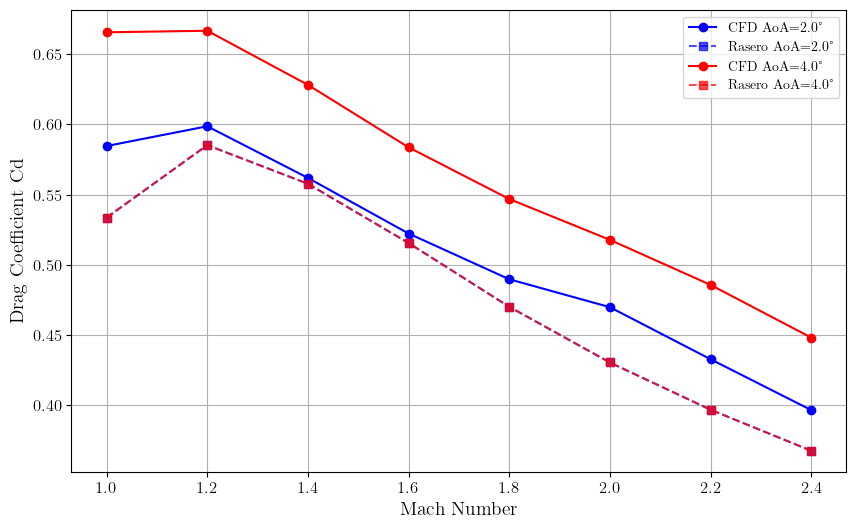

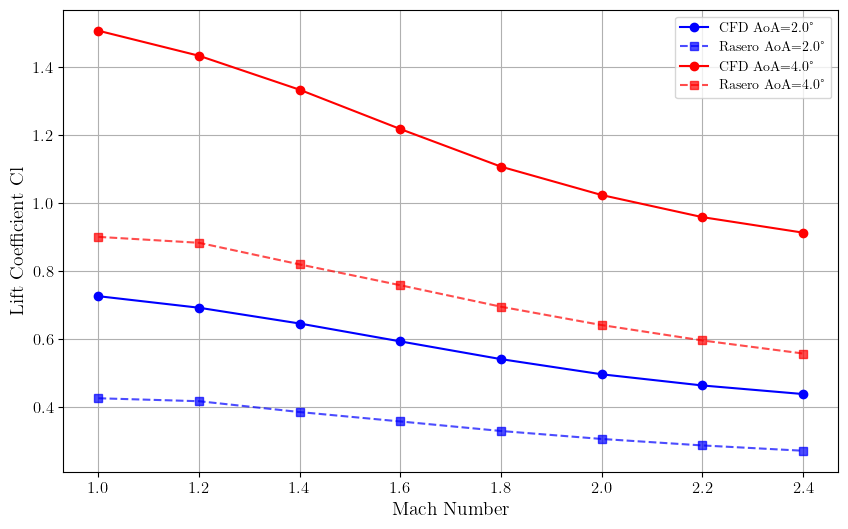

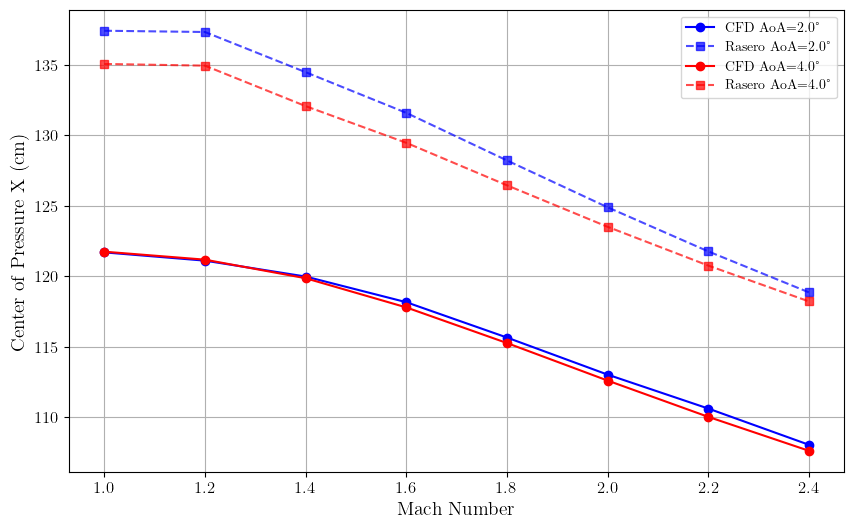

In [82]:
# === USAGE ===
# Change these two lines for one/two stage:
cfd_data = the_df_one
rasero_data = rasero_one_df

df = merge_cfd_rasero(cfd_data, rasero_data)

# Plot Cd
plt.figure(figsize=(10, 6))
plot_comparison(df, 'Cd_calc', 'Cd_Rasero', 'Drag Coefficient Cd')
plt.savefig("./results/validation/One_Cd_comparison.pdf", bbox_inches='tight')

# Plot Cl
plt.figure(figsize=(10, 6))
plot_comparison(df, 'Cl_calc', 'Cl_Rasero', 'Lift Coefficient Cl')
plt.savefig("./results/validation/One_Cl_comparison.pdf", bbox_inches='tight')
# Plot Cp
plt.figure(figsize=(10, 6))
plot_comparison(df, 'CopX_cm', 'Cp_Rasero_cm', 'Center of Pressure X (cm)')
plt.savefig("./results/validation/One_Cp_comparison.pdf", bbox_inches='tight')


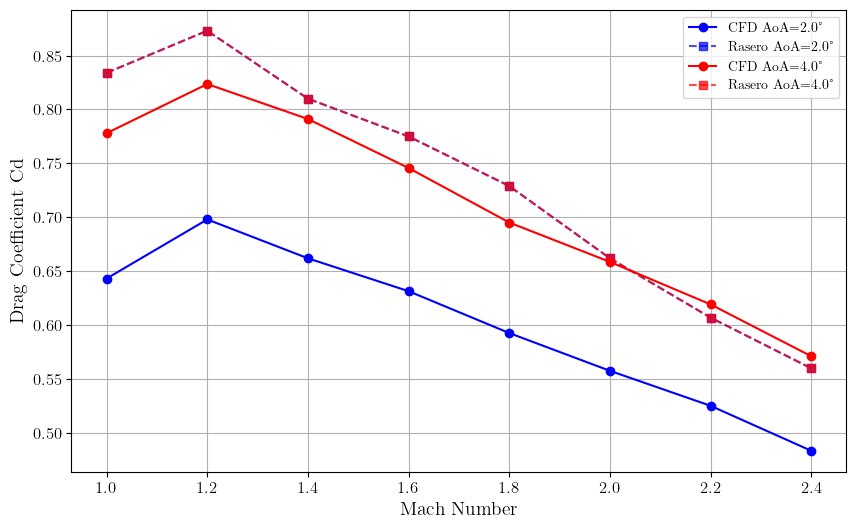

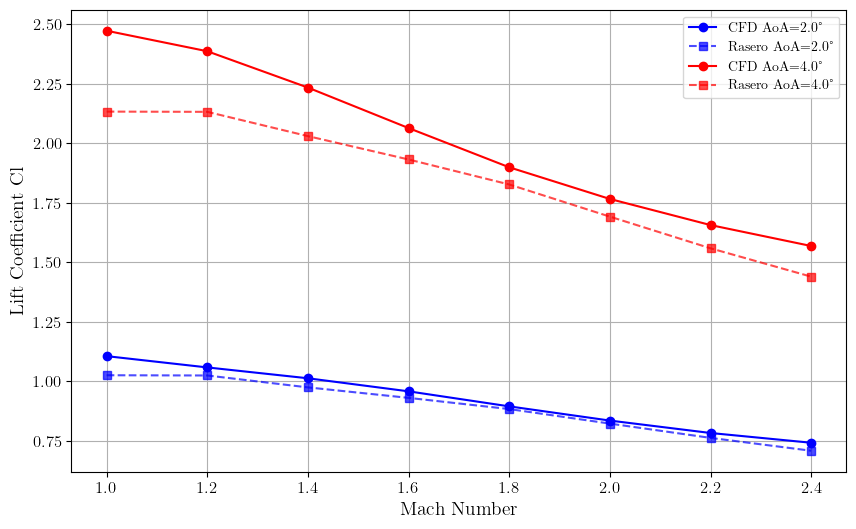

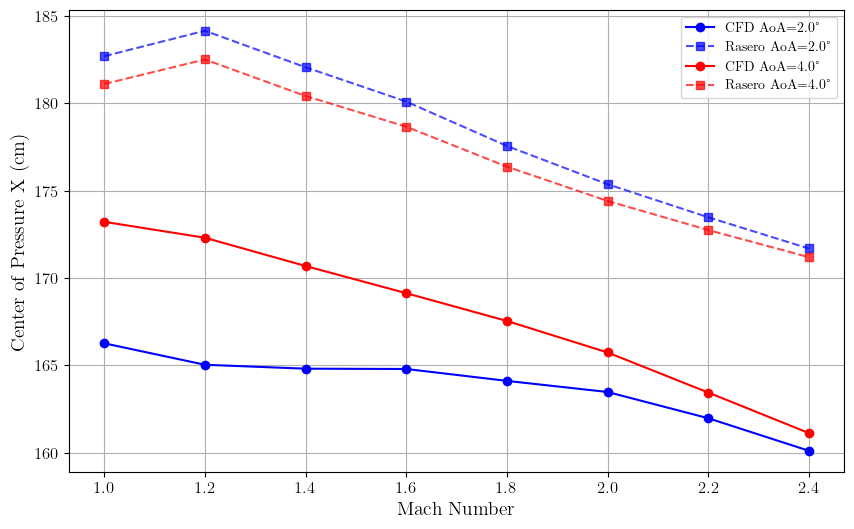

In [118]:
# === USAGE ===
# Change these two lines for one/two stage:
cfd_data = the_df_two
rasero_data = rasero_two_df

df = merge_cfd_rasero(cfd_data, rasero_data)

# Plot Cd
plt.figure(figsize=(10, 6))
plot_comparison(df, 'Cd_calc', 'Cd_Rasero', 'Drag Coefficient Cd')
plt.savefig("./results/validation/Two_Cd_comparison.pdf", bbox_inches='tight')

# Plot Cl
plt.figure(figsize=(10, 6))
plot_comparison(df, 'Cl_calc', 'Cl_Rasero', 'Lift Coefficient Cl')
plt.savefig("./results/validation/Two_Cl_comparison.pdf", bbox_inches='tight')


# Plot Cp
plt.figure(figsize=(10, 6))
plot_comparison(df, 'CopX_cm', 'Cp_Rasero_cm', 'Center of Pressure X (cm)')
plt.savefig("./results/validation/Two_Cp_comparison.pdf", bbox_inches='tight')


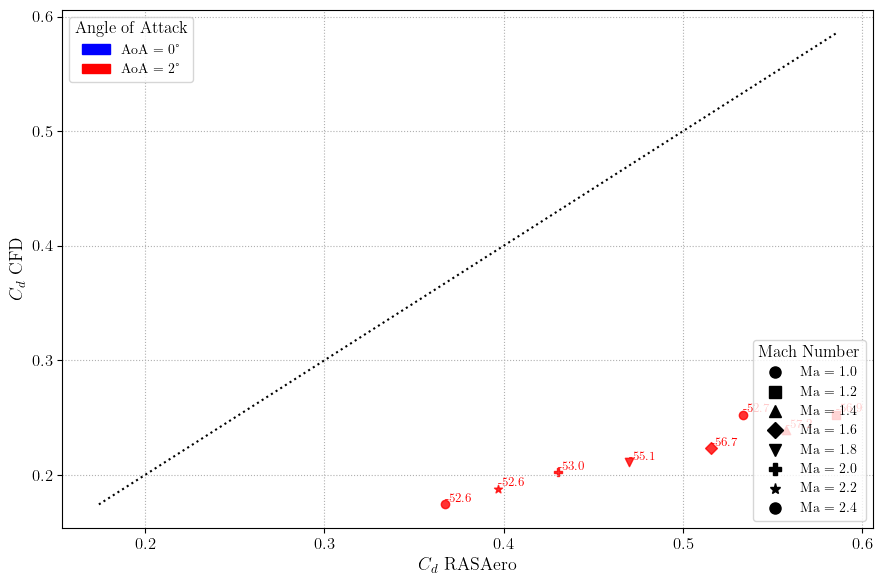

In [84]:
cd_ras = []
cd_cfd = []
aoa_list = []
mach_list = []

sdf = rasero_one_df
for row in the_df_one.itertuples():
    aoa = row.AoA
    ma = row.Ma

    match = sdf[(sdf['alpha'] == aoa) & (sdf['Mach'] == ma)]

    if not match.empty:
        cd_ras.append(match['CD'].values[0])
        cd_cfd.append(row.Cd)
        aoa_list.append(aoa)
        mach_list.append(ma)

# Build DataFrame
compare_df = pd.DataFrame({
    'Cd_ras': cd_ras,
    'Cd_cfd': cd_cfd,
    'AoA': aoa_list,
    'Ma': mach_list
})

# Compute % error
compare_df['Cd_pct_error'] = 100 * (compare_df['Cd_cfd'] - compare_df['Cd_ras']) / compare_df['Cd_ras']

# === Your plotting code here ===
# Same as before for plotting the points
# We'll just improve the legend now:

plt.figure(figsize=(9, 6))

# Color map for AoA
colors = {0: 'blue', 2: 'red'}

# Marker map for Mach number
unique_mach = sorted(compare_df['Ma'].unique())
markers = ['o', 's', '^', 'D', 'v', 'P', '*']
mach_marker_map = {ma: markers[i % len(markers)] for i, ma in enumerate(unique_mach)}

# Plot points
for aoa in [0, 2]:
    subset = compare_df[compare_df['AoA'] == aoa]
    for ma in subset['Ma'].unique():
        subsub = subset[subset['Ma'] == ma]
        plt.scatter(
            subsub['Cd_ras'], subsub['Cd_cfd'],
            color=colors[aoa],
            marker=mach_marker_map[ma],
            alpha=0.8
        )
        for _, row in subsub.iterrows():
            label = f"{row['Cd_pct_error']:+.1f}%"
            plt.text(row['Cd_ras'], row['Cd_cfd'], label, fontsize=9, color=colors[aoa], ha='left', va='bottom')

# Diagonal reference line
min_val = min(compare_df['Cd_ras'].min(), compare_df['Cd_cfd'].min())
max_val = max(compare_df['Cd_ras'].max(), compare_df['Cd_cfd'].max())
plt.plot([min_val, max_val], [min_val, max_val], linestyle=':', color='black')

plt.xlabel('$C_d$ RASAero', fontsize=13)
plt.ylabel('$C_d$ CFD', fontsize=13)
#plt.title('$Cd$ Comparison: CFD vs RASAero', fontsize=14, fontweight='bold')
plt.grid(True, linestyle=':', linewidth=0.8)

# === Clean custom legends ===

# Color legend for AoA
color_handles = [
    mpatches.Patch(color='blue', label='AoA = 0°'),
    mpatches.Patch(color='red', label='AoA = 2°')
]

# Marker legend for Mach numbers
marker_handles = [
    mlines.Line2D([], [], color='black', marker=mach_marker_map[ma], linestyle='None', markersize=8, label=f'Ma = {ma}')
    for ma in unique_mach
]

# Combine and place
legend1 = plt.legend(handles=color_handles, title='Angle of Attack', loc='upper left', frameon=True)
legend2 = plt.legend(handles=marker_handles, title='Mach Number', loc='lower right', frameon=True)
plt.gca().add_artist(legend1)  # keep both legends

plt.tight_layout()

#plt.savefig("./results/Cd_comparison_CFD_vs_RASAero.pdf", bbox_inches='tight')


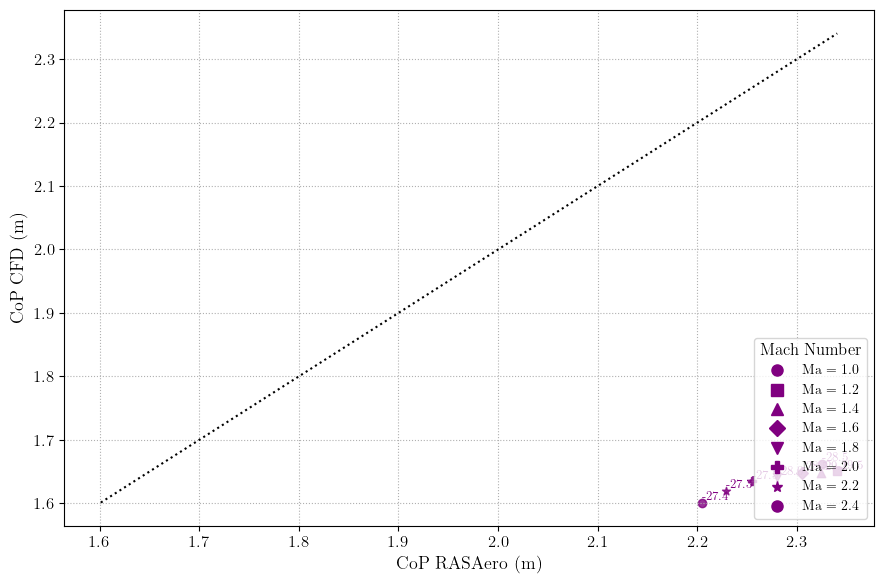

In [156]:
cp_ras = []
cp_cfd = []
mach_list = []

aoa = 2.0  # Only AoA 2.0
for row in the_df_two[the_df_two['AoA'] == aoa].itertuples():
    ma = row.Ma
    match = rasero_two_df[(rasero_two_df['alpha'] == aoa) & (rasero_two_df['Mach'] == ma)]
    if not match.empty:
        cp_ras.append(match['Cp'].values[0] * 0.0254)  # Convert inches to meters
        cp_cfd.append(row.CopX)
        mach_list.append(ma)

# Build dataframe
compare_cp = pd.DataFrame({
    'Cp_ras': cp_ras,
    'Cp_cfd': cp_cfd,
    'Ma': mach_list
})
compare_cp['Cp_pct_error'] = 100 * (compare_cp['Cp_cfd'] - compare_cp['Cp_ras']) / compare_cp['Cp_ras']

# Plot
plt.figure(figsize=(9, 6))
markers = ['o', 's', '^', 'D', 'v', 'P', '*']
unique_mach = sorted(compare_cp['Ma'].unique())
mach_marker_map = {ma: markers[i % len(markers)] for i, ma in enumerate(unique_mach)}

# Plot scatter points and annotations
for ma in unique_mach:
    sub = compare_cp[compare_cp['Ma'] == ma]
    plt.scatter(
        sub['Cp_ras'], sub['Cp_cfd'],
        color='purple',
        marker=mach_marker_map[ma],
        label=f'Ma = {ma}',
        alpha=0.8
    )
    for _, row in sub.iterrows():
        label = f"{row['Cp_pct_error']:+.1f}%"
        plt.text(row['Cp_ras'], row['Cp_cfd'], label, fontsize=9, color='purple', ha='left', va='bottom')

# Reference line
min_val = min(compare_cp['Cp_ras'].min(), compare_cp['Cp_cfd'].min())
max_val = max(compare_cp['Cp_ras'].max(), compare_cp['Cp_cfd'].max())
plt.plot([min_val, max_val], [min_val, max_val], linestyle=':', color='black')

plt.xlabel('CoP RASAero (m)', fontsize=13)
plt.ylabel('CoP CFD (m)', fontsize=13)
#plt.title('Center of Pressure Comparison (AoA = 2°)', fontsize=14, fontweight='bold')
plt.grid(True, linestyle=':', linewidth=0.8)

# Legend: Mach only
marker_handles = [
    mlines.Line2D([], [], color='purple', marker=mach_marker_map[ma], linestyle='None', markersize=8, label=f'Ma = {ma}')
    for ma in unique_mach
]
plt.legend(handles=marker_handles, title='Mach Number', loc='lower right', frameon=True)

plt.tight_layout()

#plt.savefig("./results/Cp_comparison_CFD_vs_RASAero.pdf", bbox_inches='tight')


# Force Analysis

In [209]:
COMPONENTS = [
    {"name": "Nose Cone", "stage": "Sustainer", "mass_g": 247, "pos_cm": 22.0},
    {"name": "Nose Tip Assembly", "stage": "Sustainer", "mass_g": 180, "pos_cm": 0.0},
    {"name": "Shock Cord", "stage": "Sustainer", "mass_g": 100, "pos_cm": 2.54},
    {"name": "Updated Main", "stage": "Sustainer", "mass_g": 191, "pos_cm": 5.08},
    {"name": "Shock Cord", "stage": "Sustainer", "mass_g": 100, "pos_cm": 5.08},
    {"name": "Swivel", "stage": "Sustainer", "mass_g": 63.5, "pos_cm": 5.08},
    {"name": "Nose Cone Straight Length", "stage": "Sustainer", "mass_g": 137, "pos_cm": 52.4},
    {"name": "Av Bay + Recovery", "stage": "Sustainer", "mass_g": 457, "pos_cm": 58.6},
    {"name": "Tube Coupler", "stage": "Sustainer", "mass_g": 0, "pos_cm": 77},
    {"name": "Swivel", "stage": "Sustainer", "mass_g": 63.5, "pos_cm": 60.4},
    {"name": "Bulkhead", "stage": "Sustainer", "mass_g": 30, "pos_cm": 60.8},
    {"name": "Ave Bay Components + Service Module", "stage": "Sustainer", "mass_g": 528, "pos_cm": 66.6},
    {"name": "Recovery Components", "stage": "Sustainer", "mass_g": 220, "pos_cm": 66.6},
    {"name": "Bulkhead", "stage": "Sustainer", "mass_g": 30, "pos_cm": 73.7},
    {"name": "Swivel", "stage": "Sustainer", "mass_g": 63.5, "pos_cm": 73.7},
    {"name": "Shock Cord", "stage": "Sustainer", "mass_g": 58, "pos_cm": 75.5},
    {"name": "Updated Drogue", "stage": "Sustainer", "mass_g": 90, "pos_cm": 78.8},
    {"name": "Shock Cord", "stage": "Sustainer", "mass_g": 58, "pos_cm": 86.4},
    {"name": "Swivel", "stage": "Sustainer", "mass_g": 63.5, "pos_cm": 88.7},
    {"name": "Motor Retention Plate", "stage": "Sustainer", "mass_g": 55, "pos_cm": 89.7},
    {"name": "Thrust Transfer Coupler", "stage": "Sustainer", "mass_g": 45, "pos_cm": 90.1},
    {"name": "Centering Ring + Epoxy", "stage": "Sustainer", "mass_g": 10, "pos_cm": 95},
    {"name": "Centering Ring + Epoxy", "stage": "Sustainer", "mass_g": 10, "pos_cm": 157},
    {"name": "Freeform Fin Set", "stage": "Sustainer", "mass_g": 78, "pos_cm": 158},
    {"name": "Centering Ring + Epoxy", "stage": "Sustainer", "mass_g": 10, "pos_cm": 171},
    {"name": "Tip to Tip Fin Fillets", "stage": "Sustainer", "mass_g": 58, "pos_cm": 163},
    {"name": "Fin Leading Edge", "stage": "Sustainer", "mass_g": 14, "pos_cm": 161},
 
    {"name": "Av Bay", "stage": "Booster", "mass_g": 459, "pos_cm": 175},
    {"name": "Bulkhead", "stage": "Booster", "mass_g": 30, "pos_cm": 172},
    {"name": "Ave Bay Components + Service Module", "stage": "Booster", "mass_g": 301, "pos_cm": 175},
    {"name": "Recovery Components", "stage": "Booster", "mass_g": 146, "pos_cm": 175},
    {"name": "Bulkhead", "stage": "Booster", "mass_g": 30, "pos_cm": 180},
    {"name": "Swivel", "stage": "Booster", "mass_g": 63.5, "pos_cm": 180},
    {"name": "Recovery Bay + Main Tube", "stage": "Booster", "mass_g": 887, "pos_cm": 229},
    {"name": "Shock Cord", "stage": "Booster", "mass_g": 100, "pos_cm": 181},
    {"name": "Updated Main", "stage": "Booster", "mass_g": 110, "pos_cm": 184},
    {"name": "Shock Cord", "stage": "Booster", "mass_g": 100, "pos_cm": 190},
    {"name": "Updated Drogue", "stage": "Booster", "mass_g": 90, "pos_cm": 193},
    {"name": "Shock Cord", "stage": "Booster", "mass_g": 58, "pos_cm": 199},
    {"name": "Swivel", "stage": "Booster", "mass_g": 63.5, "pos_cm": 204},
    {"name": "Motor Retention Plate", "stage": "Booster", "mass_g": 55, "pos_cm": 205},
    {"name": "Thrust Transfer Coupler", "stage": "Booster", "mass_g": 45.4, "pos_cm": 205},
    {"name": "Thrust Transfer Plate", "stage": "Booster", "mass_g": 10, "pos_cm": 209},
    {"name": "Centering Ring + Epoxy", "stage": "Booster", "mass_g": 10, "pos_cm": 210},
    {"name": "Centering Ring + Epoxy", "stage": "Booster", "mass_g": 10, "pos_cm": 286},
    {"name": "Freeform Fin Set", "stage": "Booster", "mass_g": 114, "pos_cm": 281},
    {"name": "Tip to Tip", "stage": "Booster", "mass_g": 13, "pos_cm": 290},

    {"name": "Sustainer Motor", "stage": "Sustainer", "mass_g": 6400, "pos_cm": 135},
    {"name": "Booster Motor", "stage": "Booster", "mass_g": 7200, "pos_cm": 290},
]


df_components_raw = pd.DataFrame(COMPONENTS)
df_components_raw["mass_kg"] = df_components_raw["mass_g"] / 1000.0
df_components_raw["cg_m"]    = df_components_raw["pos_cm"] / 100.0
df_components_raw

print(df_components_raw[df_components_raw['stage'] == 'Sustainer'].groupby('stage')['mass_g'].sum())
print(df_components_raw[df_components_raw['stage'] == 'Booster'].groupby('stage')['mass_g'].sum())


stage
Sustainer    9360.0
Name: mass_g, dtype: float64
stage
Booster    9895.4
Name: mass_g, dtype: float64


In [199]:
def distribute_component(
    df: pd.DataFrame,
    component_name: str,
    half_length: float,
    n_div: int,
    *,
    mass_col: str = "mass_kg",
    cg_col: str   = "cg_m",
    name_col: str = "name",
) -> pd.DataFrame:
    """
    Replace one component row with `n_div` equal-mass slices spread over
    [cg - half_length, cg + half_length], so a large point mass (e.g. the
    motor) is approximated as a distributed mass for the bending analysis.

    Parameters
    ----------
    df : DataFrame
        Must contain at least columns `name_col`, `mass_col`, `cg_col`.
    component_name : str
        Exact string in `df[name_col]` to replace.
    half_length : float
        L in metres. The new slice CGs are linearly spaced from
        (cg - L) to (cg + L).
    n_div : int
        Number of slices (>= 2).

    Returns
    -------
    DataFrame
        New frame with the original row removed and the slices appended.
    """
    if n_div < 2:
        raise ValueError("n_div must be >= 2")

    mask = df[name_col] == component_name
    if not mask.any():
        raise KeyError(f"{component_name!r} not found in {name_col} column")

    row = df.loc[mask].iloc[0]
    df_out = df.loc[~mask].copy()

    total_mass = row[mass_col]
    cg0        = row[cg_col]

    masses = np.full(n_div, total_mass / n_div)
    cg_new = np.linspace(cg0 - half_length, cg0 + half_length, n_div)

    add_rows = pd.DataFrame({
        name_col : [f"{component_name} seg{i+1}" for i in range(n_div)],
        mass_col : masses,
        cg_col   : cg_new,
    })

    return pd.concat([df_out, add_rows], ignore_index=True)

In [218]:
df_components = distribute_component(
    df_components_raw,
    "Sustainer Motor",
    half_length=757/2000,
    n_div=30,
)

df_components_distrib = distribute_component(
    df_components,
    "Booster Motor",
    half_length=893/2000,
    n_div=30,
)

df_components_distrib

,name,stage,mass_g,pos_cm,mass_kg,cg_m
0,Nose Cone,Sustainer,247.0,22.00,0.247,0.220000
1,Nose Tip Assembly,Sustainer,180.0,0.00,0.180,0.000000
2,Shock Cord,Sustainer,100.0,2.54,0.100,0.025400
3,Updated Main,Sustainer,191.0,5.08,0.191,0.050800
4,Shock Cord,Sustainer,100.0,5.08,0.100,0.050800
...,...,...,...,...,...,...
102,Booster Motor seg26,NaN,NaN,NaN,0.240,3.223328
103,Booster Motor seg27,NaN,NaN,NaN,0.240,3.254121
104,Booster Motor seg28,NaN,NaN,NaN,0.240,3.284914
105,Booster Motor seg29,NaN,NaN,NaN,0.240,3.315707


In [211]:
def compute_rocket_bending(rocket_tri: pv.PolyData,
                            df_components: pd.DataFrame,
                            n_slices: int = 105) -> dict:
    """
    Bin the surface pressure load into axial stations and combine it with
    component inertial loads (translational + rotational relief) to get the
    internal axial load, shear force and bending moment along the rocket.

    df_components must have columns "mass_kg" and "cg_m" (see
    `distribute_component` for splitting large point masses like the motor
    into slices before calling this).
    """
    rocket_tri = rocket_tri.compute_cell_sizes()
    area    = rocket_tri.cell_data["Area"]
    normals = rocket_tri.cell_normals

    pressure = rocket_tri.point_data_to_cell_data()["p"]
    force = -pressure[:, None] * area[:, None] * normals
    force_x, force_y, force_z = force[:, 0], force[:, 1], force[:, 2]

    centres   = rocket_tri.cell_centers().points
    x_centres = centres[:, 0]
    edges     = np.linspace(x_centres.min(), x_centres.max(), n_slices + 1)
    dx        = edges[1] - edges[0]
    idx       = np.clip(np.digitize(x_centres, edges, right=True) - 1, 0, n_slices - 1)

    Fx_bin = np.zeros(n_slices)
    Fy_bin = np.zeros(n_slices)
    Fz_bin = np.zeros(n_slices)
    np.add.at(Fx_bin, idx, force_x)
    np.add.at(Fy_bin, idx, force_y)
    np.add.at(Fz_bin, idx, force_z)
    x_mid = (edges[:-1] + edges[1:]) / 2

    df = pd.DataFrame({"x_mid_m": x_mid, "Fx_N": Fx_bin, "Fy_N": Fy_bin, "Fz_N": Fz_bin})

    # rigid-body accelerations from the net aerodynamic force
    total_mass = df_components["mass_kg"].sum()
    Fx_aero, Fy_aero, Fz_aero = Fx_bin.sum(), Fy_bin.sum(), Fz_bin.sum()
    aX, aY, aZ = Fx_aero / total_mass, Fy_aero / total_mass, Fz_aero / total_mass

    cg_x = (df_components["cg_m"] * df_components["mass_kg"]).sum() / total_mass
    I_yz = (df_components["mass_kg"] * (df_components["cg_m"] - cg_x) ** 2).sum()
    M_z  = ((x_mid - cg_x) * Fy_bin).sum()
    alpha_z = M_z / I_yz

    # per-component inertial relief, binned onto the same stations
    F_trans_y = -df_components["mass_kg"] * aY
    F_rot_y   =  df_components["mass_kg"] * alpha_z * (cg_x - df_components["cg_m"])
    F_trans_x = -df_components["mass_kg"] * aX

    comp_idx = np.clip(np.digitize(df_components["cg_m"], edges, right=True) - 1, 0, n_slices - 1)
    Fy_point = np.zeros(n_slices)
    Fx_point = np.zeros(n_slices)
    np.add.at(Fy_point, comp_idx, (F_trans_y + F_rot_y).to_numpy())
    np.add.at(Fx_point, comp_idx, F_trans_x.to_numpy())

    Fy_total = Fy_bin + Fy_point
    Fx_total = Fx_bin + Fx_point

    shear_y    = -np.cumsum(Fy_total)
    moment_y   = np.cumsum(shear_y * dx)
    axial_load = -np.cumsum(Fx_total)

    return {
        "df": df,
        "dx": dx,
        "Fy_bin": Fy_bin,
        "Fy_point": Fy_point,
        "Fy_total": Fy_total,
        "Fx_total": Fx_total,
        "axial_load": axial_load,
        "shear_y": shear_y,
        "moment_y": moment_y,
        "Fx": Fx_aero,
        "Fy": Fy_aero,
        "Fz": Fz_aero,
        "aX": aX,
        "aY": aY,
        "aZ": aZ,
        "alpha_z": alpha_z,
        "cg_x": cg_x,
    }

In [212]:
base_dir = "OpenFOAM_Results_gathered/Parametric_Study/TwoStage"

results = []
for case in sorted(os.listdir(base_dir)):
    if not case.startswith("Ma_"):
        continue

    m = re.fullmatch(r"Ma_([+-]?\d+)p(\d+)_AoA_([+-]?\d+)p(\d+)", case)
    ma  = float(f"{m.group(1)}.{m.group(2)}")
    aoa = float(f"{m.group(3)}.{m.group(4)}")

    print(f"Processing case: {case} (Ma={ma}, AoA={aoa})")
    try:
        t = os.listdir(os.path.join(base_dir, case, "postProcessing", "rocketVTK"))[0]
        path = os.path.join(base_dir, case, "postProcessing", "rocketVTK", t, "rocketWall.vtp")
        rocket = pv.read(path).compute_cell_sizes()
        rocket_tri = rocket.extract_surface().triangulate()

        result = compute_rocket_bending(rocket_tri, df_components)
        result["aoa"] = aoa
        result["ma"] = ma

        results.append(result)
    except Exception as e:
        print(f"  Error processing case {case}: {e}")
        continue

df_loads = pd.DataFrame(results)
df_loads.head()

Processing case: Ma_0p8_AoA_1p0 (Ma=0.8, AoA=1.0)
  Error processing case Ma_0p8_AoA_1p0: [Errno 2] No such file or directory: 'OpenFOAM_Results_gathered/Parametric_Study/TwoStage/Ma_0p8_AoA_1p0/postProcessing/rocketVTK'
Processing case: Ma_0p8_AoA_2p0 (Ma=0.8, AoA=2.0)
  Error processing case Ma_0p8_AoA_2p0: [Errno 2] No such file or directory: 'OpenFOAM_Results_gathered/Parametric_Study/TwoStage/Ma_0p8_AoA_2p0/postProcessing/rocketVTK'
Processing case: Ma_0p8_AoA_3p0 (Ma=0.8, AoA=3.0)
  Error processing case Ma_0p8_AoA_3p0: [Errno 2] No such file or directory: 'OpenFOAM_Results_gathered/Parametric_Study/TwoStage/Ma_0p8_AoA_3p0/postProcessing/rocketVTK'
Processing case: Ma_0p8_AoA_4p0 (Ma=0.8, AoA=4.0)
  Error processing case Ma_0p8_AoA_4p0: [Errno 2] No such file or directory: 'OpenFOAM_Results_gathered/Parametric_Study/TwoStage/Ma_0p8_AoA_4p0/postProcessing/rocketVTK'
Processing case: Ma_0p8_AoA_5p0 (Ma=0.8, AoA=5.0)
  Error processing case Ma_0p8_AoA_5p0: [Errno 2] No such file or 

,df,dx,Fy_bin,Fy_point,Fy_total,Fx_total,axial_load,shear_y,moment_y,Fx,Fy,Fz,aX,aY,aZ,alpha_z,cg_x,aoa,ma
0,x_mid_m Fx_N Fy_N Fz_N...,0.025282,"[-0.31646552531479677, -0.6102413702933192, -1...","[4.706885763330244, 5.903962932140346, 0.0, 0....","[4.390420238015447, 5.293721561847027, -1.2518...","[-13.657283163705888, -24.342696545300594, -32...","[13.657283163705888, 37.99997970900648, 70.569...","[-4.390420238015447, -9.684141799862473, -8.43...","[-0.1109969781002663, -0.35582786375714553, -0...",-212.599265,-187.487522,-0.596949,-11.041020,-9.736880,-0.031002,3.737678,1.901537,1.0,1.0
1,x_mid_m Fx_N Fy_N Fz_N...,0.025282,"[-0.6549420979849695, -1.2755406425230764, -2....","[9.151035014822444, 11.493894932063005, 0.0, 0...","[8.496092916837474, 10.21835428953993, -2.0309...","[-13.600111150874708, -24.27271663628064, -32....","[13.600111150874708, 37.87282778715535, 70.431...","[-8.496092916837474, -18.714447206377404, -16....","[-0.21479507388894256, -0.6879267957087695, -1...",-216.454673,-402.755830,-0.192184,-11.241245,-20.916513,-0.009981,6.217158,1.901537,2.0,1.0
2,x_mid_m Fx_N Fy_N Fz_N...,0.025282,"[-0.9908840511104996, -1.9791876267090405, -2....","[13.592523522937755, 17.08995724321383, 0.0, 0...","[12.601639471827255, 15.110769616504792, -2.77...","[-13.57016716175286, -24.232987339128204, -32....","[13.57016716175286, 37.803154500881064, 70.345...","[-12.601639471827255, -27.712409088332045, -24...","[-0.3185899810616124, -1.0192048420375677, -1....",-217.782613,-641.240772,1.769315,-11.310210,-33.301867,0.091887,8.054500,1.901537,3.0,1.0
3,x_mid_m Fx_N Fy_N Fz_N...,0.025282,"[-1.3220884486397502, -2.6403162212887126, -3....","[18.284681290349546, 23.00485840149115, 0.0, 0...","[16.962592841709796, 20.364542180202434, -3.55...","[-13.581025676331542, -24.240735951078207, -32...","[13.581025676331542, 37.82176162740975, 70.326...","[-16.962592841709796, -37.32713502191223, -33....","[-0.42884198871724766, -1.3725327891326717, -2...",-216.158344,-900.594239,4.216578,-11.225856,-46.770996,0.218982,9.792221,1.901537,4.0,1.0
4,x_mid_m Fx_N Fy_N Fz_...,0.025282,"[-1.6444047518991327, -3.3034996084652395, -4....","[23.067268749770598, 29.04045226708424, 0.0, 0...","[21.422863997871467, 25.736952658619003, -4.34...","[-13.575160720528025, -24.222310231436094, -32...","[13.575160720528025, 37.797470951964115, 70.24...","[-21.422863997871467, -47.15981665649047, -42....","[-0.5416049118549905, -1.7338819270044978, -2....",-215.130557,-1181.444983,5.787278,-11.172479,-61.356554,0.300554,11.110667,1.901537,5.0,1.0


In [233]:
base_dir = "OpenFOAM_Results_gathered/Parametric_Study/OneStage"

results = []
for case in sorted(os.listdir(base_dir)):
    if not case.startswith("Ma_"):
        continue

    m = re.fullmatch(r"Ma_([+-]?\d+)p(\d+)_AoA_([+-]?\d+)p(\d+)", case)
    ma  = float(f"{m.group(1)}.{m.group(2)}")
    aoa = float(f"{m.group(3)}.{m.group(4)}")

    print(f"Processing case: {case} (Ma={ma}, AoA={aoa})")
    try:
        t = os.listdir(os.path.join(base_dir, case, "postProcessing", "rocketVTK"))[0]
        path = os.path.join(base_dir, case, "postProcessing", "rocketVTK", t, "rocketWall.vtp")
        rocket = pv.read(path).compute_cell_sizes()
        rocket_tri = rocket.extract_surface().triangulate()

        result = compute_rocket_bending(rocket_tri, df_components)
        result["aoa"] = aoa
        result["ma"] = ma

        results.append(result)
    except Exception as e:
        print(f"  Error processing case {case}: {e}")
        continue

df_loads_sustainer = pd.DataFrame(results)
df_loads_sustainer.head()

Processing case: Ma_0p8_AoA_1p0 (Ma=0.8, AoA=1.0)
  Error processing case Ma_0p8_AoA_1p0: [Errno 2] No such file or directory: 'OpenFOAM_Results_gathered/Parametric_Study/OneStage/Ma_0p8_AoA_1p0/postProcessing/rocketVTK'
Processing case: Ma_0p8_AoA_2p0 (Ma=0.8, AoA=2.0)
  Error processing case Ma_0p8_AoA_2p0: [Errno 2] No such file or directory: 'OpenFOAM_Results_gathered/Parametric_Study/OneStage/Ma_0p8_AoA_2p0/postProcessing/rocketVTK'
Processing case: Ma_0p8_AoA_3p0 (Ma=0.8, AoA=3.0)
  Error processing case Ma_0p8_AoA_3p0: [Errno 2] No such file or directory: 'OpenFOAM_Results_gathered/Parametric_Study/OneStage/Ma_0p8_AoA_3p0/postProcessing/rocketVTK'
Processing case: Ma_0p8_AoA_4p0 (Ma=0.8, AoA=4.0)
  Error processing case Ma_0p8_AoA_4p0: [Errno 2] No such file or directory: 'OpenFOAM_Results_gathered/Parametric_Study/OneStage/Ma_0p8_AoA_4p0/postProcessing/rocketVTK'
Processing case: Ma_0p8_AoA_5p0 (Ma=0.8, AoA=5.0)
  Error processing case Ma_0p8_AoA_5p0: [Errno 2] No such file or 

,df,dx,Fy_bin,Fy_point,Fy_total,Fx_total,axial_load,shear_y,moment_y,Fx,Fy,Fz,aX,aY,aZ,alpha_z,cg_x,aoa,ma
0,x_mid_m Fx_N Fy_N Fz_N...,0.014043,"[-0.12523021661783293, -0.25675307258292823, -...","[3.1650447779757203, 1.7438224720043065, 0.0, ...","[3.0398145613578875, 1.4870693994213782, -0.29...","[-5.491652997797313, -11.135080570542176, -14....","[5.491652997797313, 16.62673356833949, 30.7165...","[-3.0398145613578875, -4.526883960779266, -4.2...","[-0.042686613742474344, -0.10625540821672268, ...",-198.856024,-129.041971,-0.056552,-10.327286,-6.701599,-0.002937,5.722731,1.901537,1.0,1.0
1,x_mid_m Fx_N Fy_N Fz_N...,0.014043,"[-0.26764169744373556, -0.5017787761034105, -0...","[6.512512748458214, 3.588218469113519, 0.0, 12...","[6.244871051014478, 3.0864396930101083, -0.655...","[-5.479826058299479, -11.124031666765898, -14....","[5.479826058299479, 16.603857725065378, 30.693...","[-6.244871051014478, -9.331310744024586, -8.67...","[-0.08769363822875323, -0.2187286238836833, -0...",-200.114685,-266.459966,0.987474,-10.392653,-13.838194,0.051283,11.749673,1.901537,2.0,1.0
2,x_mid_m Fx_N Fy_N Fz_N...,0.014043,"[-0.4071311850489359, -0.7698665207624581, -0....","[9.940677366598166, 5.477071101961092, 0.0, 19...","[9.53354618154923, 4.707204581198633, -0.99041...","[-5.468817433743611, -11.119050442981878, -14....","[5.468817433743611, 16.58786787672549, 30.6754...","[-9.53354618154923, -14.240750762747863, -13.2...","[-0.13387487796822914, -0.3338507037767351, -0...",-200.643092,-407.107080,2.189446,-10.420095,-21.142489,0.113706,17.924187,1.901537,3.0,1.0
3,x_mid_m Fx_N Fy_N Fz_N...,0.014043,"[-0.5382085298790105, -1.0171623083039405, -1....","[13.500816181149133, 7.438641882199982, 0.0, 2...","[12.962607651270122, 6.4214795738960415, -1.34...","[-5.470987921851927, -11.110470581218133, -14....","[5.470987921851927, 16.58145850307006, 30.6482...","[-12.962607651270122, -19.384087225166162, -18...","[-0.18202749369614094, -0.4542286518356956, -0...",-200.049257,-553.210623,2.927950,-10.389255,-28.730155,0.152059,24.335257,1.901537,4.0,1.0
4,x_mid_m Fx_N Fy_N Fz_N...,0.014043,"[-0.6715694166891011, -1.2758034077623632, -1....","[17.2006097461692, 9.477165142901676, 0.0, 33....","[16.529040329480097, 8.201361735139312, -1.649...","[-5.459879110169802, -11.093440019184197, -14....","[5.459879110169802, 16.553319129353998, 30.602...","[-16.529040329480097, -24.73040206461941, -23....","[-0.23210914542205482, -0.5793859609383724, -0...",-200.207529,-705.121681,6.048791,-10.397474,-36.619425,0.314135,30.995732,1.901537,5.0,1.0


In [ ]:
# Full load analysis restricted to the sustainer alone (post-separation stack)
df_components_sustainer_raw = df_components_raw[df_components_raw["stage"] == "Sustainer"].copy()

df_components_sustainer = distribute_component(
    df_components_sustainer_raw,
    "Sustainer Motor",
    half_length=757/2000,
    n_div=30,
)

base_dir = "OpenFOAM_Results_gathered/Parametric_Study/OneStage"

results_sustainer = []
for case in sorted(os.listdir(base_dir)):
    if not case.startswith("Ma_"):
        continue

    m = re.fullmatch(r"Ma_([+-]?\d+)p(\d+)_AoA_([+-]?\d+)p(\d+)", case)
    ma  = float(f"{m.group(1)}.{m.group(2)}")
    aoa = float(f"{m.group(3)}.{m.group(4)}")

    print(f"Processing case: {case} (Ma={ma}, AoA={aoa})")
    try:
        t = os.listdir(os.path.join(base_dir, case, "postProcessing", "rocketVTK"))[0]
        path = os.path.join(base_dir, case, "postProcessing", "rocketVTK", t, "rocketWall.vtp")
        rocket = pv.read(path).compute_cell_sizes()
        rocket_tri = rocket.extract_surface().triangulate()

        result = compute_rocket_bending(rocket_tri, df_components_sustainer)
        result["aoa"] = aoa
        result["ma"] = ma

        results_sustainer.append(result)
    except Exception as e:
        print(f"  Error processing case {case}: {e}")
        continue

df_loads_sustainer = pd.DataFrame(results_sustainer)
df_loads_sustainer.head()

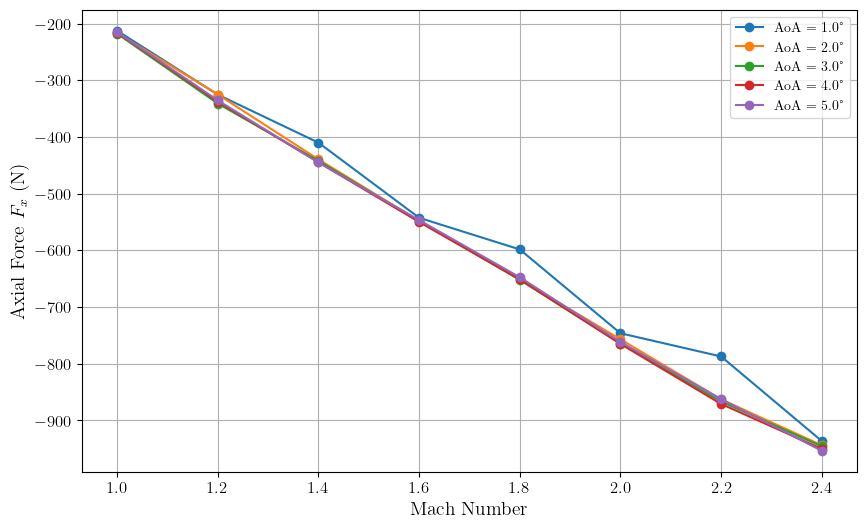

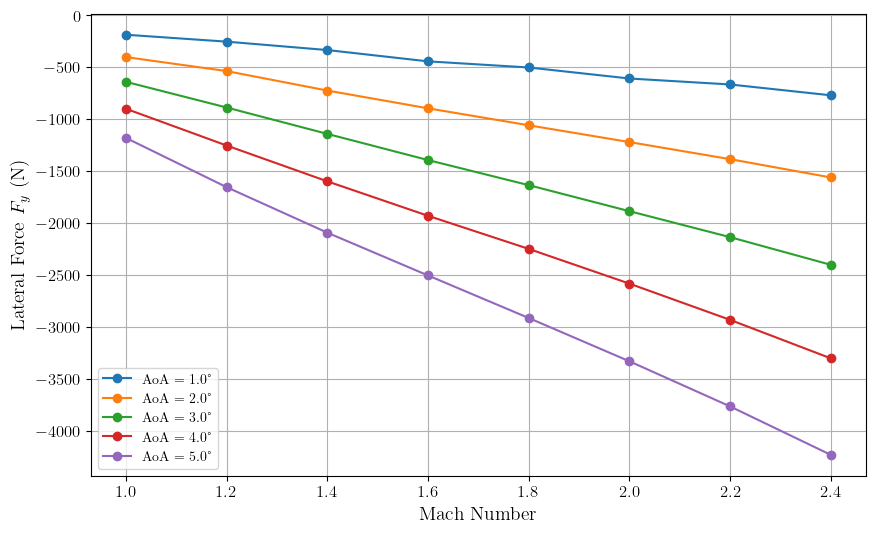

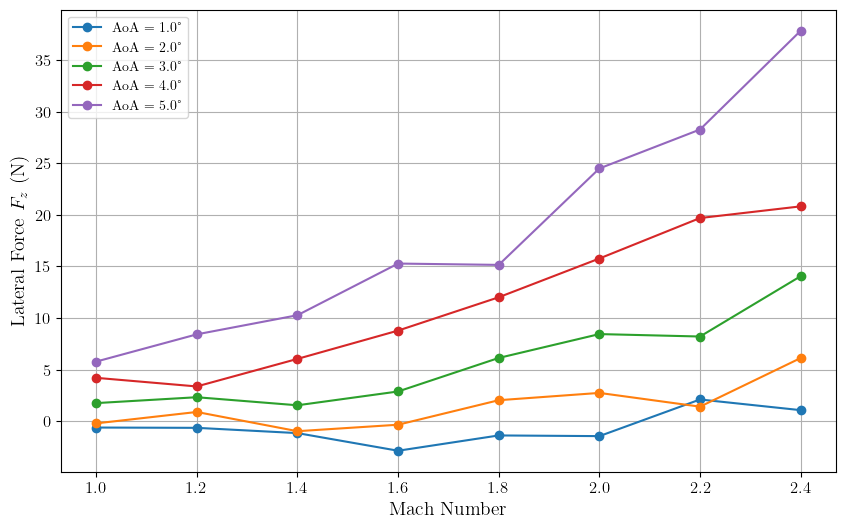

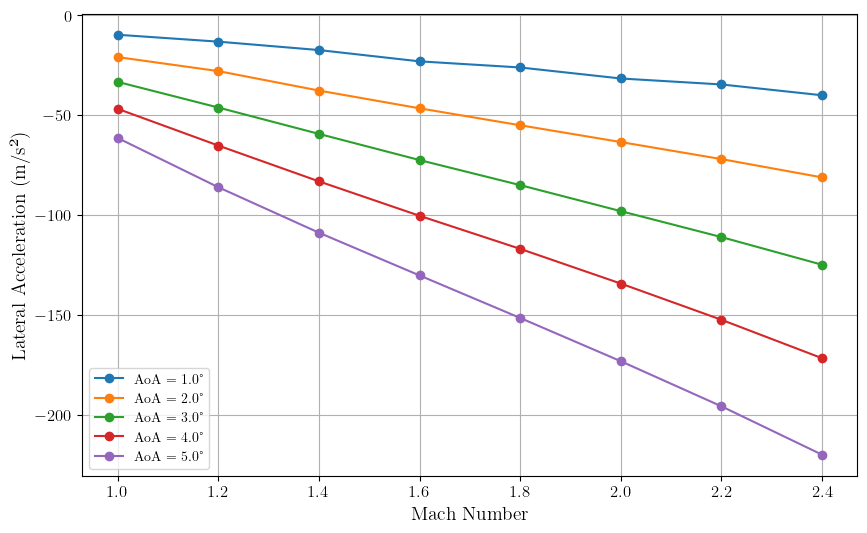

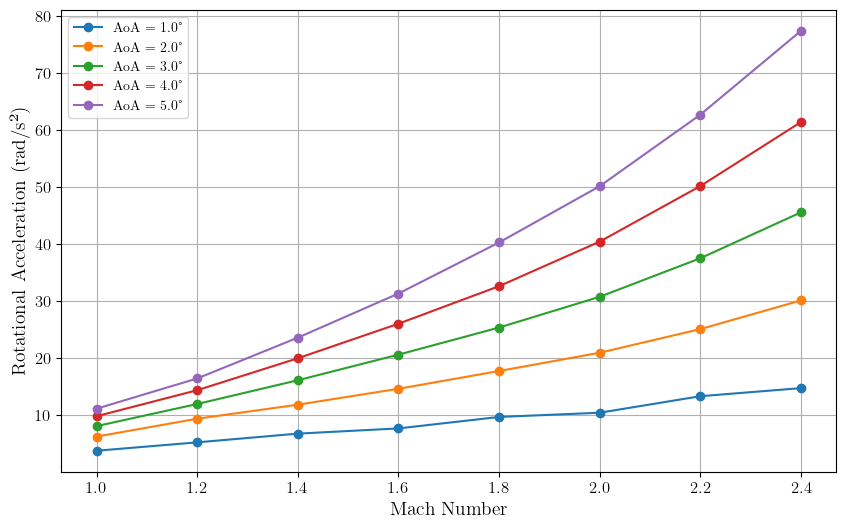

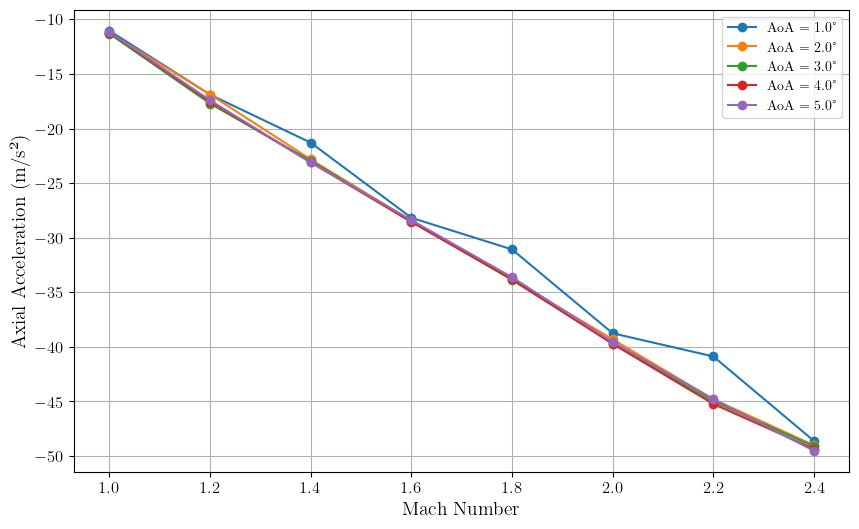

In [213]:
def plot_vs_mach(df, column, ylabel, filename):
    fig, ax = plt.subplots(figsize=(10, 6))
    for aoa in sorted(df["aoa"].unique()):
        data = df[df["aoa"] == aoa].sort_values("ma")
        ax.plot(data["ma"], data[column], "o-", label=f"AoA = {aoa}°")
    ax.set_xlabel("Mach Number")
    ax.set_ylabel(ylabel)
    ax.legend()
    ax.grid(True)
    fig.savefig(f"./results/{filename}", bbox_inches="tight")
    return fig, ax

PLOTS_VS_MACH = [
    ("Fx",      "Axial Force $F_x$ (N)",             "Fx_vs_Ma.pdf"),
    ("Fy",      "Lateral Force $F_y$ (N)",            "Fy_vs_Ma.pdf"),
    ("Fz",      "Lateral Force $F_z$ (N)",            "Fz_vs_Ma.pdf"),
    ("aY",      "Lateral Acceleration (m/s²)",        "aY_vs_Ma.pdf"),
    ("alpha_z", "Rotational Acceleration (rad/s²)",   "alpha_z_vs_Ma.pdf"),
    ("aX",      "Axial Acceleration (m/s²)",         "aX_vs_Ma.pdf"),
]
for column, ylabel, filename in PLOTS_VS_MACH:
    plot_vs_mach(df_loads, column, ylabel, filename)

In [ ]:
dthe_df = analyze_all_cases("Data/CollectedResultsMesh_New")

No case directories found matching pattern: Data/CollectedResultsMesh_New/Ma_*_AoA_*


In [222]:
pressure = rocket_tri.point_data['p']
x = rocket_tri.points[:, 0]
y = rocket_tri.points[:, 1]
z = rocket_tri.points[:, 2]

faces = rocket_tri.faces.reshape(-1, 4)[:, 1:]          # noqa: F841

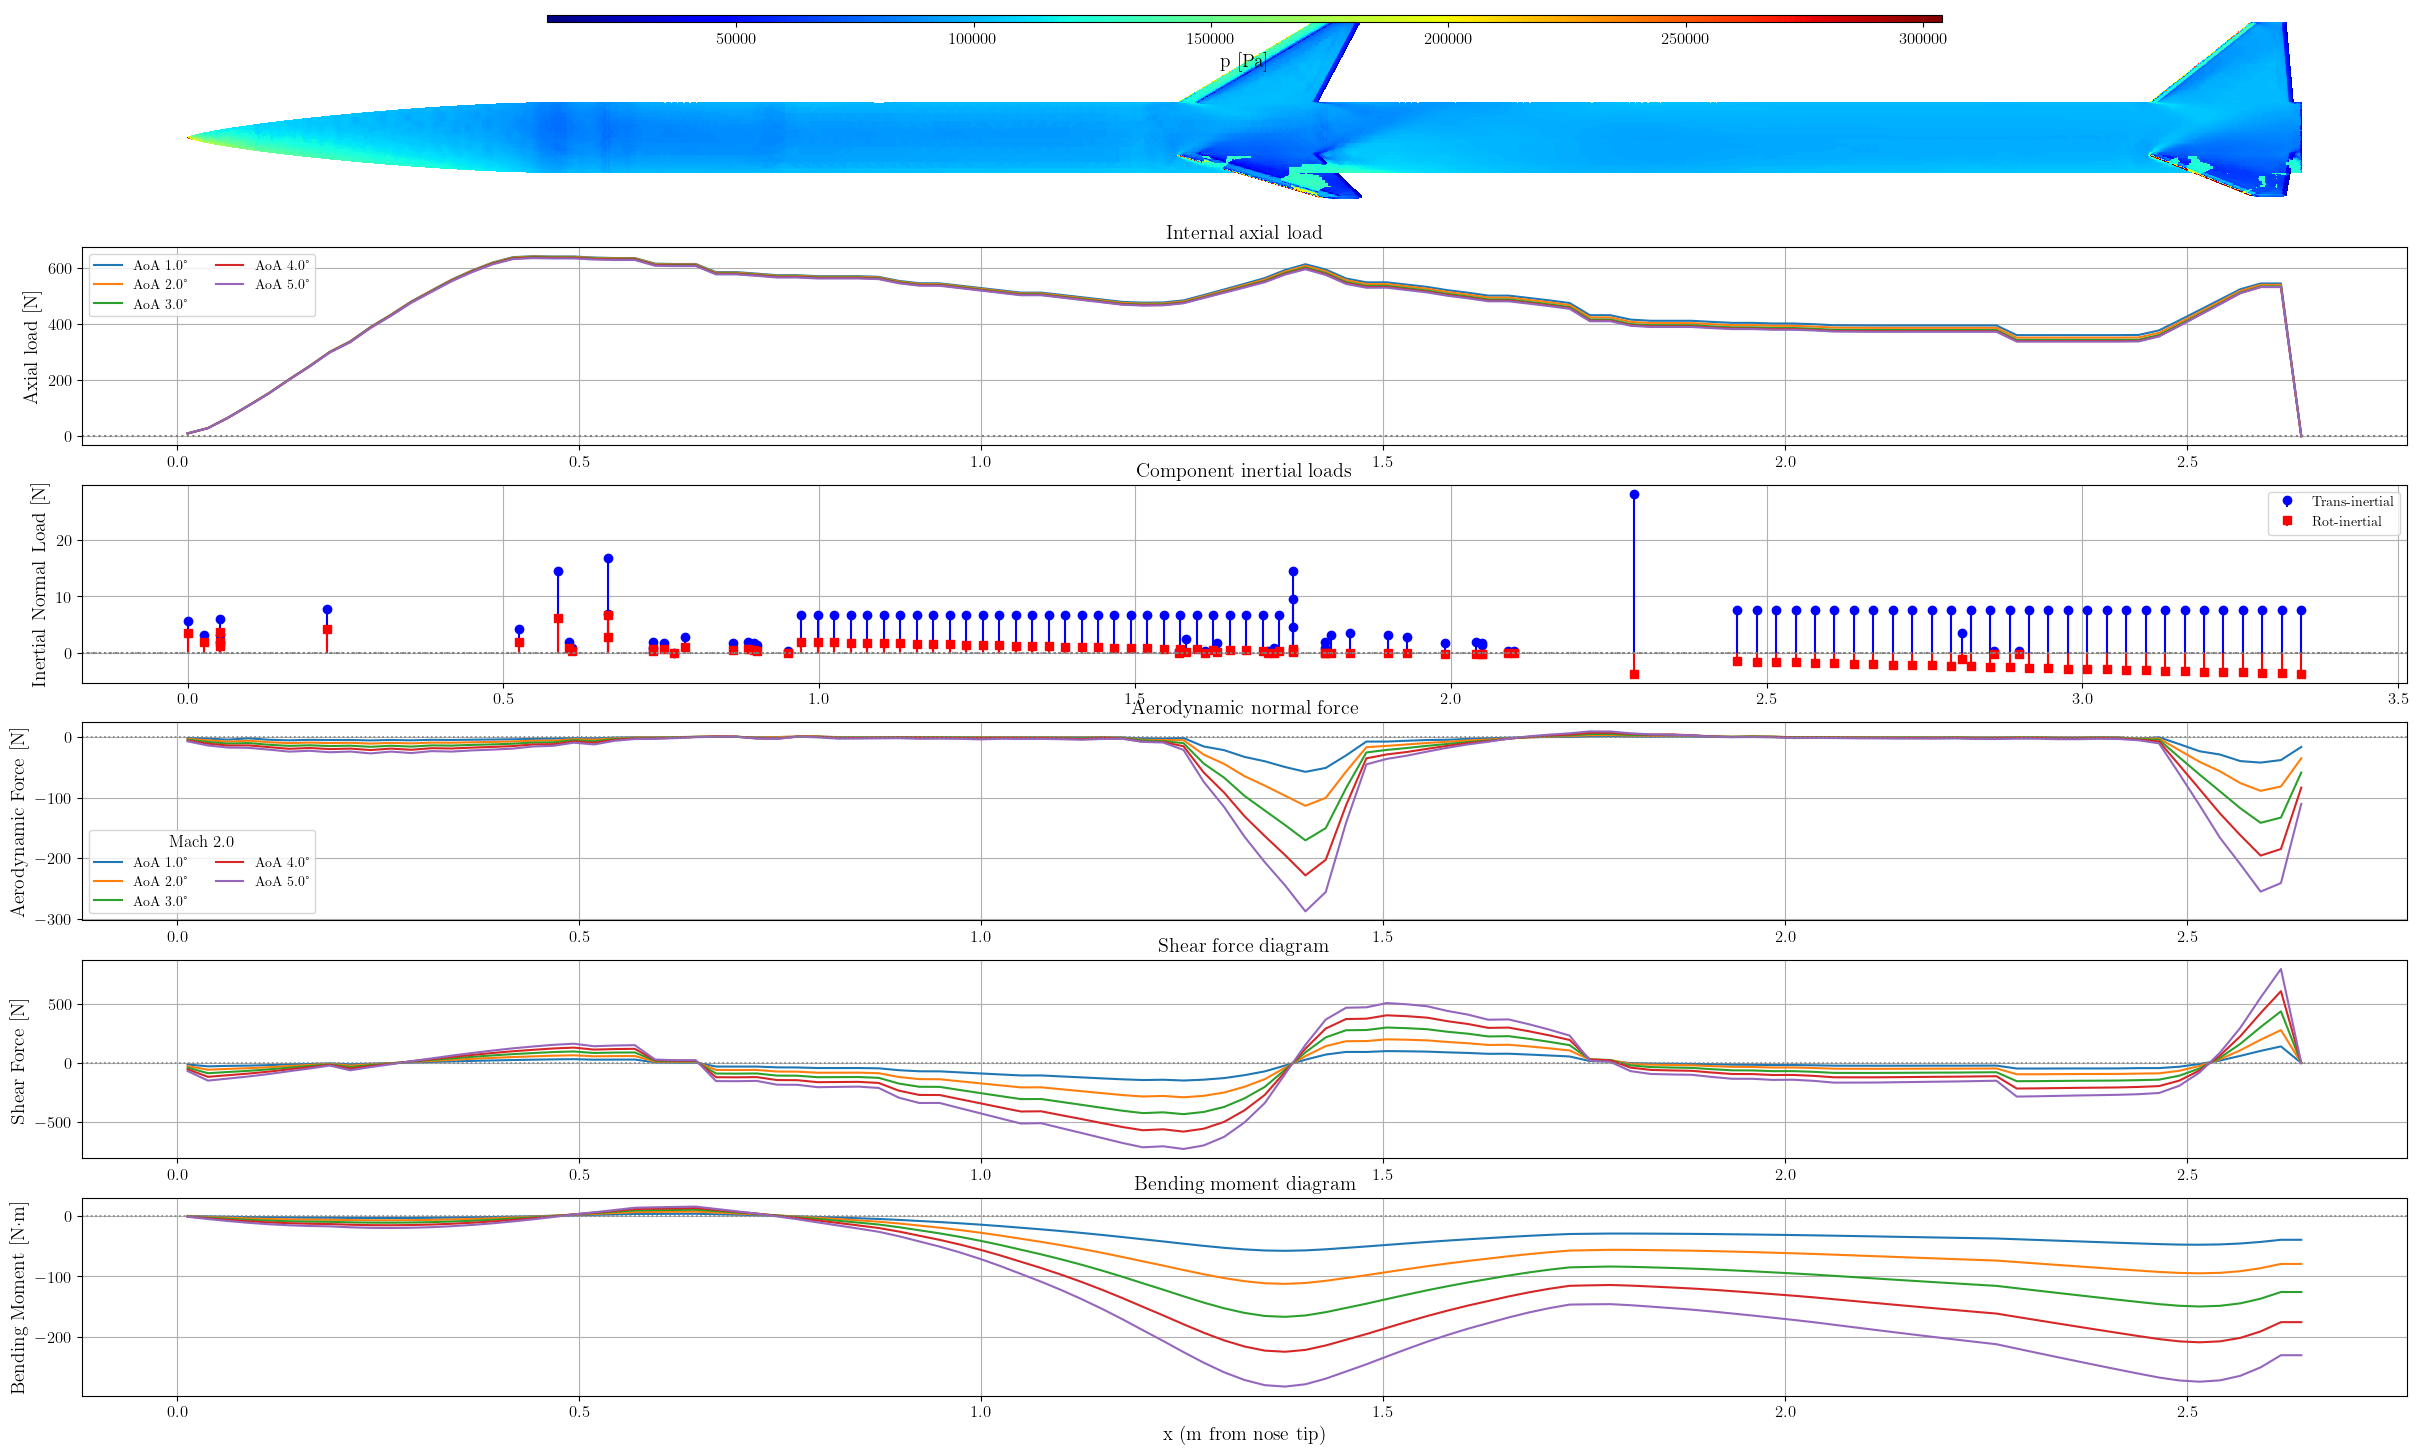

In [232]:
ma_target = 2.0
rows_ma = df_loads[np.isclose(df_loads["ma"], ma_target)]
if rows_ma.empty:
    raise ValueError(f"No runs at Mach {ma_target}")

# first run supplies pressure map & stems
row0    = rows_ma.iloc[0]
df_bin0 = row0["df"]
#df_comp = row0["df_components"]

# -------------------------------- figure -------------------------------
fig, axes = plt.subplots(6, 1, figsize=(30, 18), sharex=False)

# 0) pressure map -------------------------------------------------------
tc = axes[0].tripcolor(x, y, faces, pressure, shading="flat", cmap="jet")
cax = inset_axes(axes[0], width="60%", height="4%", loc="lower center",
                    bbox_to_anchor=(0, 0.9, 1, 1),
                    bbox_transform=axes[0].transAxes)
fig.colorbar(tc, cax=cax, orientation="horizontal").set_label("p [Pa]")
axes[0].grid(False)
for sp in axes[0].spines.values():
    sp.set_visible(False)
axes[0].tick_params(left=False, bottom=False,
                    labelleft=False, labelbottom=False)

# 1) axial internal load N(x) ------------------------------------------
colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
for i, (_, rw) in enumerate(rows_ma.sort_values("aoa").iterrows()):
    col   = colors[i % len(colors)]
    lbl   = f"AoA {rw['aoa']:.1f}°"
    xmid  = rw["df"]["x_mid_m"].values

    # compute axial load if not stored
    if "axial_load" in rw:
        axial = rw["axial_load"]
    else:  # derive on the fly
        Fx_total = rw["Fx_bin"] + rw["Fx_point"]
        axial = -np.cumsum(Fx_total)

    axes[1].plot(xmid, axial, color=col, label=lbl)

axes[1].set_ylabel("Axial load [N]")
axes[1].set_title("Internal axial load")
axes[1].legend(ncol=2)
axes[1].axhline(0, ls=":", color="gray")
axes[1].grid(True)

# 2) stems from first run ----------------------------------------------
aY0, alpha_z0, cg_x0 = row0["aY"], row0["alpha_z"], row0["cg_x"]
trans0 = -df_components_distrib["mass_kg"] * aY0
rot0   =  df_components_distrib["mass_kg"] * alpha_z0 * (cg_x0 - df_components_distrib["cg_m"])

axes[2].stem(df_components_distrib["cg_m"], trans0, basefmt=" ",
                linefmt="b-", markerfmt="bo", label="Trans‑inertial")
axes[2].stem(df_components_distrib["cg_m"], rot0,   basefmt=" ",
                linefmt="r-", markerfmt="rs", label="Rot‑inertial")
axes[2].set_ylabel("Inertial Normal Load [N]")
axes[2].set_title("Component inertial loads")
axes[2].legend()
axes[2].axhline(0, ls=":", color="gray")
axes[2].grid(True)

# 3‑5) Fy_bin, shear, moment for each AoA ------------------------------
for i, (_, rw) in enumerate(rows_ma.sort_values("aoa").iterrows()):
    col   = colors[i % len(colors)]
    lbl   = f"AoA {rw['aoa']:.1f}°"
    dloc  = rw["df"]
    xmid  = dloc["x_mid_m"].values

    axes[3].plot(xmid, rw["Fy_bin"],  color=col, label=lbl)
    axes[4].plot(xmid, rw["shear_y"], color=col, label=lbl)
    axes[5].plot(xmid, rw["moment_y"], color=col, label=lbl)

axes[3].set_ylabel("Aerodynamic Force [N]")
axes[3].set_title("Aerodynamic normal force")

axes[4].set_ylabel("Shear Force [N]")
axes[4].set_title("Shear force diagram")

axes[5].set_ylabel("Bending Moment [N·m]")
axes[5].set_xlabel("x (m from nose tip)")
axes[5].set_title("Bending moment diagram")

# single legend on panel 3
axes[3].legend(title=f"Mach {ma_target}", ncol=2)
axes[4].legend().set_visible(False)
axes[5].legend().set_visible(False)

# zero lines on panels 2‑5
for idx in (2, 3, 4, 5):
    axes[idx].axhline(0, color="gray", linestyle=":", linewidth=1.2)
    axes[idx].grid(True)


#plt.savefig(f"./results/forces_Ma2.pdf", bbox_inches='tight')

In [235]:
base_dir

'OpenFOAM_Results_gathered/Parametric_Study/OneStage'

In [236]:
path = "OpenFOAM_Results_gathered/Parametric_Study/OneStage/Ma_2p0_AoA_5p0/postProcessing/rocketVTK/8000/rocketWall.vtp"
rocket = pv.read(path).compute_cell_sizes()
rocket_tri_one = rocket.extract_surface().triangulate()

In [237]:
pressure = rocket_tri_one.point_data['p']
x = rocket_tri_one.points[:, 0]
y = rocket_tri_one.points[:, 1]
z = rocket_tri_one.points[:, 2]

faces = rocket_tri_one.faces.reshape(-1, 4)[:, 1:]          # noqa: F841

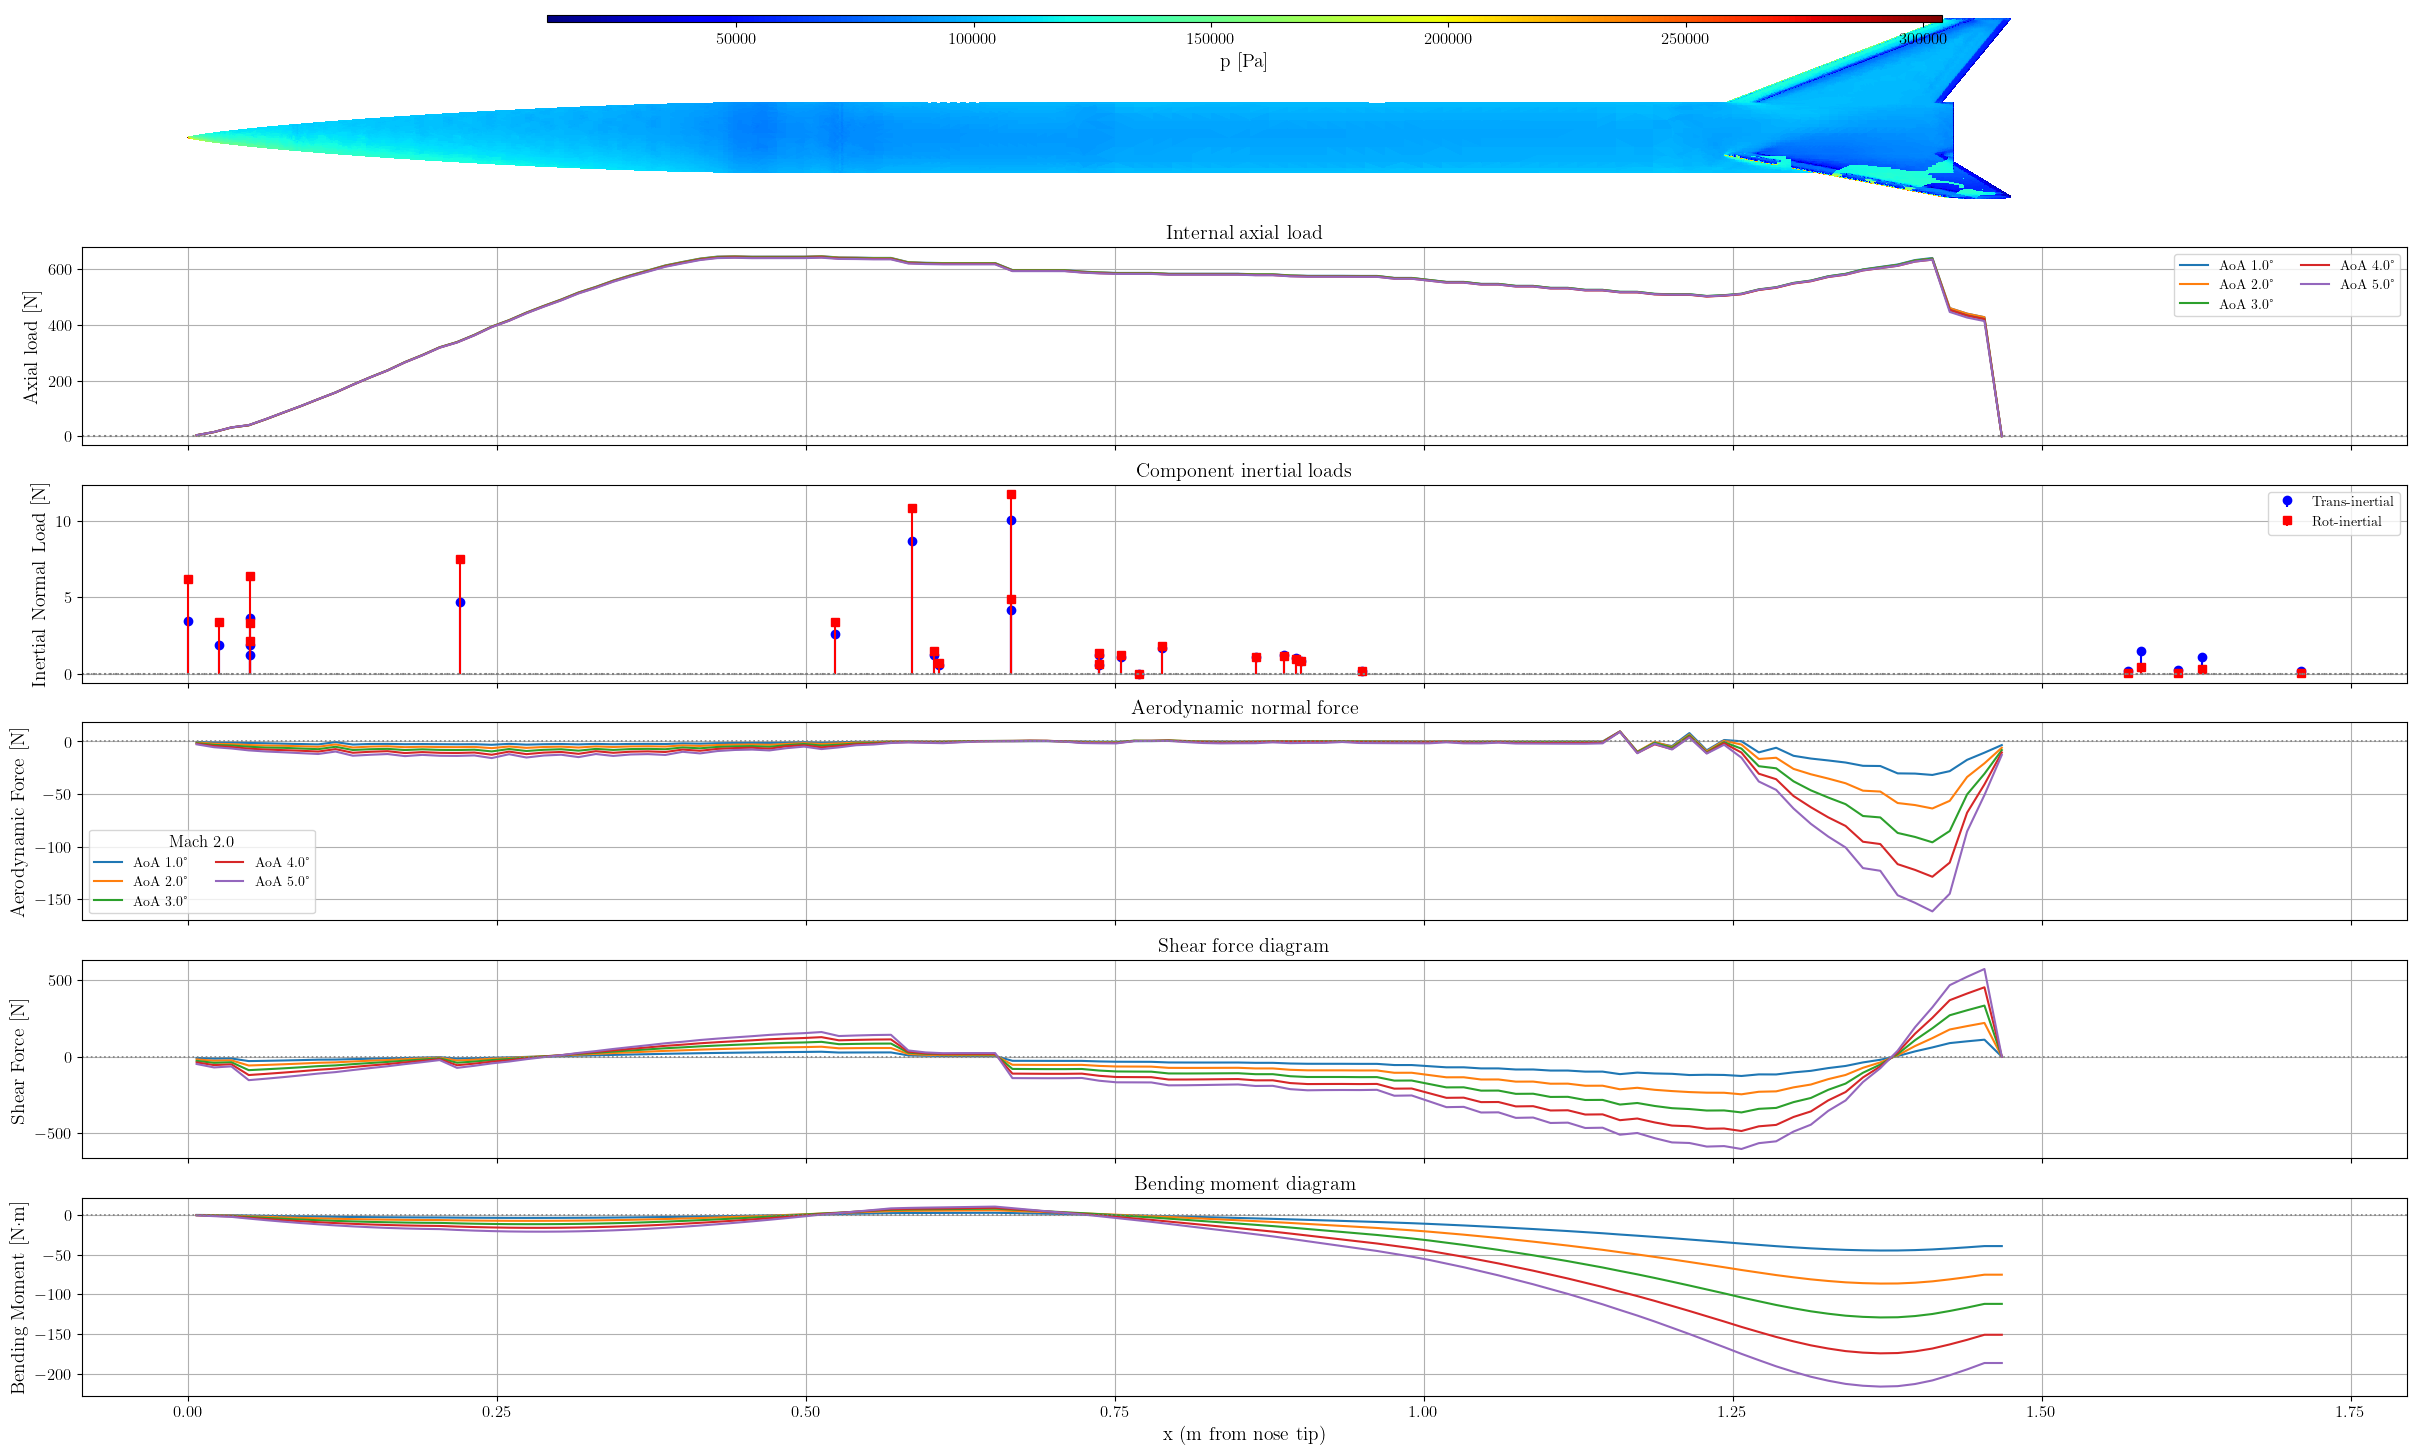

In [240]:
ma_target = 2.0
rows_ma = df_loads_sustainer[np.isclose(df_loads_sustainer["ma"], ma_target)]
if rows_ma.empty:
    raise ValueError(f"No runs at Mach {ma_target}")

# first run supplies pressure map & stems
row0    = rows_ma.iloc[0]
df_bin0 = row0["df"]

components_porc = df_components_distrib[df_components_distrib["stage"] == "Sustainer"].copy()

# -------------------------------- figure -------------------------------
fig, axes = plt.subplots(6, 1, figsize=(30, 18), sharex=True)

# 0) pressure map -------------------------------------------------------
tc = axes[0].tripcolor(x, y, faces, pressure, shading="flat", cmap="jet")
cax = inset_axes(axes[0], width="60%", height="4%", loc="lower center",
                    bbox_to_anchor=(0, 0.9, 1, 1),
                    bbox_transform=axes[0].transAxes)
fig.colorbar(tc, cax=cax, orientation="horizontal").set_label("p [Pa]")
axes[0].grid(False)
for sp in axes[0].spines.values():
    sp.set_visible(False)
axes[0].tick_params(left=False, bottom=False,
                    labelleft=False, labelbottom=False)

# 1) axial internal load N(x) ------------------------------------------
colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
for i, (_, rw) in enumerate(rows_ma.sort_values("aoa").iterrows()):
    col   = colors[i % len(colors)]
    lbl   = f"AoA {rw['aoa']:.1f}°"
    xmid  = rw["df"]["x_mid_m"].values

    # compute axial load if not stored
    if "axial_load" in rw:
        axial = rw["axial_load"]
    else:  # derive on the fly
        Fx_total = rw["Fx_bin"] + rw["Fx_point"]
        axial = -np.cumsum(Fx_total)

    axes[1].plot(xmid, axial, color=col, label=lbl)

axes[1].set_ylabel("Axial load [N]")
axes[1].set_title("Internal axial load")
axes[1].legend(ncol=2)
axes[1].axhline(0, ls=":", color="gray")
axes[1].grid(True)

# 2) stems from first run ----------------------------------------------
aY0, alpha_z0, cg_x0 = row0["aY"], row0["alpha_z"], row0["cg_x"]
trans0 = -components_porc["mass_kg"] * aY0
rot0   =  components_porc["mass_kg"] * alpha_z0 * (cg_x0 - components_porc["cg_m"])

axes[2].stem(components_porc["cg_m"], trans0, basefmt=" ",
                linefmt="b-", markerfmt="bo", label="Trans‑inertial")
axes[2].stem(components_porc["cg_m"], rot0,   basefmt=" ",
                linefmt="r-", markerfmt="rs", label="Rot‑inertial")
axes[2].set_ylabel("Inertial Normal Load [N]")
axes[2].set_title("Component inertial loads")
axes[2].legend()
axes[2].axhline(0, ls=":", color="gray")
axes[2].grid(True)

# 3‑5) Fy_bin, shear, moment for each AoA ------------------------------
for i, (_, rw) in enumerate(rows_ma.sort_values("aoa").iterrows()):
    col   = colors[i % len(colors)]
    lbl   = f"AoA {rw['aoa']:.1f}°"
    dloc  = rw["df"]
    xmid  = dloc["x_mid_m"].values

    axes[3].plot(xmid, rw["Fy_bin"],  color=col, label=lbl)
    axes[4].plot(xmid, rw["shear_y"], color=col, label=lbl)
    axes[5].plot(xmid, rw["moment_y"], color=col, label=lbl)

axes[3].set_ylabel("Aerodynamic Force [N]")
axes[3].set_title("Aerodynamic normal force")

axes[4].set_ylabel("Shear Force [N]")
axes[4].set_title("Shear force diagram")

axes[5].set_ylabel("Bending Moment [N·m]")
axes[5].set_xlabel("x (m from nose tip)")
axes[5].set_title("Bending moment diagram")

# single legend on panel 3
axes[3].legend(title=f"Mach {ma_target}", ncol=2)
axes[4].legend().set_visible(False)
axes[5].legend().set_visible(False)

# zero lines on panels 2‑5
for idx in (2, 3, 4, 5):
    axes[idx].axhline(0, color="gray", linestyle=":", linewidth=1.2)
    axes[idx].grid(True)


#plt.savefig(f"./results/forces_Ma2.pdf", bbox_inches='tight')